In [8]:
from pathlib import Path
import os, sys

# Auto-set repo root (expects Data/ and predictions/ at root)
cwd = Path.cwd()
REPO_ROOT = None
for parent in [cwd, *cwd.parents]:
    if (parent / "Data").exists() and (parent / "predictions").exists():
        REPO_ROOT = parent
        break
if REPO_ROOT is None:
    REPO_ROOT = cwd
os.chdir(REPO_ROOT)

# Add notebook-local modules to import path
src_candidates = [
    REPO_ROOT / "notebooks",
    REPO_ROOT / "code_repository" / "notebooks",
]
for SRC in src_candidates:
    if SRC.exists() and str(SRC) not in sys.path:
        sys.path.insert(0, str(SRC))
        break
print(f"Working dir: {Path.cwd()}")


Working dir: /mnt/nas/PhD/Code/Ms_paint/code_repository


In [9]:
from analysis.plot_style import apply_style, save_figure, set_save_dir
FIGURE_ID = "figure4"
FIG_DIR = set_save_dir(REPO_ROOT, FIGURE_ID)
apply_style()


In [10]:
# =========================
# 0) CONFIG & IMPORTS
# =========================
import os, glob
from pathlib import Path
import numpy as np
import pandas as pd

# --- your paths ---
os.chdir(REPO_ROOT)
EXP        = "Feature_augmentation_experiment"
TASK       = "binary"
PRED_ROOT  = f"predictions/{EXP}/{TASK}"

# --- what to analyze ---
MODEL_TYPES = ["pytorch_mlp", "tabm", "lightgbm", "mlp", "rf", "xgboost"]
METRICS     = ["mcc", "roc_auc", "pr_auc"]

# --- data assumptions ---
ALWAYS_ON  = "Text_Embedding"
THRESHOLD  = 0.5

# --- outputs ---
BASE_OUTDIR = Path(f"analysis_exports/Feature_augmentation_experiment")
BASE_OUTDIR.mkdir(parents=True, exist_ok=True)

# Stats / plots
import pingouin as pg
try:
    import scikit_posthocs as sp
    HAS_SCPH = True
except Exception:
    HAS_SCPH = False
from statsmodels.stats.multitest import multipletests

# Plotters you already created (assumed available)
from analysis.model_comparison import (
    plot_boxplots_with_significance,
    plot_pairwise_q_heatmap_sig,
)

# --- metrics helpers you already used ---
from sklearn.metrics import (
    matthews_corrcoef, average_precision_score, roc_auc_score
)

def split_runname_by_model(run_name: str, model_type: str):
    marker = f"_{model_type}_"
    if marker not in run_name: return None
    prefix, modalities = run_name.split(marker, 1)
    if "_" not in prefix: return None
    aug, llm = prefix.split("_", 1)
    return aug, llm, modalities

def parse_atomic_features(modalities: str):
    return [m.strip() for m in modalities.split("+") if m.strip()]

def read_one_run_dir(run_dir: str):
    frames = []
    for pf in glob.glob(os.path.join(run_dir, "*.pkl")):
        try:
            df = pd.read_pickle(pf)
        except Exception:
            continue
        needed = {"True","ProbaPos","cv_iter","fold_idx","rep_idx"}
        if not needed.issubset(df.columns):
            continue
        keep = ["True","Pred","ProbaPos","cv_iter","fold_idx","rep_idx"]
        for k in keep:
            if k not in df.columns:
                df[k] = np.nan
        frames.append(df[keep].copy())
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

def compute_metrics_from_df(df, prob_col="ProbaPos", pred_col="Pred", thr=0.5):
    y_true = df["True"].astype(int).values
    if pred_col in df.columns and df[pred_col].notna().any():
        y_pred = df[pred_col].fillna((df[prob_col] >= thr).astype(int) if prob_col in df.columns else 0).astype(int).values
    else:
        if prob_col not in df.columns:
            raise ValueError("Need Pred or ProbaPos to compute metrics.")
        y_pred = (df[prob_col].values >= thr).astype(int)
    out = {"mcc": matthews_corrcoef(y_true, y_pred)}
    if prob_col in df.columns:
        y_score = df[prob_col].astype(float).values
        try: out["pr_auc"]  = average_precision_score(y_true, y_score)
        except Exception: out["pr_auc"] = np.nan
        try: out["roc_auc"] = roc_auc_score(y_true, y_score)
        except Exception: out["roc_auc"] = np.nan
    else:
        out.update({"pr_auc": np.nan, "roc_auc": np.nan})
    return out


In [11]:
# =========================
# 1) BUILD PER-CYCLE TABLE (all 3 metrics at once) FOR ONE MODEL
# =========================
def build_per_cycle_table(model_type: str) -> pd.DataFrame:
    runs = []
    for d in sorted(os.listdir(PRED_ROOT)):
        run_dir = os.path.join(PRED_ROOT, d)
        if not os.path.isdir(run_dir): 
            continue
        parsed = split_runname_by_model(d, model_type)
        if parsed is None:
            continue
        aug, llm, modalities = parsed
        runs.append({"run_dir": run_dir, "run_name": d, "aug": aug, "llm": llm, "modalities": modalities})
    if not runs:
        return pd.DataFrame()

    rows = []
    for r in runs:
        df = read_one_run_dir(r["run_dir"])
        if df.empty: 
            continue
        df["cv_iter"]  = df["cv_iter"].astype(int)
        df["fold_idx"] = df["fold_idx"].astype(int)
        df["rep_idx"]  = df["rep_idx"].astype(int)

        feats  = parse_atomic_features(r["modalities"])
        var_feats = [f for f in feats if f != ALWAYS_ON]
        var_tag = "+".join(sorted(var_feats)) if var_feats else "(Text only)"  # TE-only

        for (it, fd), g in df.groupby(["cv_iter","fold_idx"]):
            mets = compute_metrics_from_df(g, prob_col="ProbaPos", pred_col="Pred", thr=THRESHOLD)
            rows.append({
                "model_type": model_type,
                "var_tag": var_tag,
                "cv_iter": int(it),
                "fold_idx": int(fd),
                "cv_cycle": 5*int(it) + int(fd),
                **mets
            })
    return pd.DataFrame(rows)


In [12]:
from matplotlib import colors
from matplotlib.patches import Patch

def _fmt_q(v):
    if v is None or np.isnan(v): return ""
    return f"{v:.2f}" if v >= 1e-2 else f"{v:.1e}"

def plot_boxplots_with_significance(
    resample_df,
    pval_matrix,
    value_metric="mcc",
    alpha=0.05,
    title=None,
    figsize=(12, 6),
    savepath=None,
    friedman_table=None,
    friedman_p_override=None,
    show_points="outliers",  # "outliers" | "all" | "none"
    whis=1.5,
    base_feature=None,       # kept for API compatibility, not used in grid
    feature_separator="+",
    plus_fontsize=8,         # controls dot size in grid
    feature_label_fontsize=9,
    label_rotation=60,       # rotation of top x-ticks IF you ever re-enable labels
):
    """
    Boxplots (top) + feature-incidence dot grid (bottom).

    - Top axis: metric by var_tag, colored by BH decision vs best.
      Shows x-ticks (for alignment) but NO text labels.
    - Bottom axis: dot matrix showing which features are present in each coalition.
      Rows are ordered: Proteomics, ECFP, InfoAlign (CellPaint), GC, MIC.
      Text_Embedding is not shown (assumed always on).
    """
    import numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt

    def _fmt_p(p):
        return f"{p:.3g}" if p >= 1e-3 else f"{p:.1e}"

    # -----------------------------
    # 1) Prepare data & ordering
    # -----------------------------
    df = resample_df[["var_tag", "cv_cycle", value_metric]].dropna().copy()
    if df.empty:
        raise ValueError("resample_df is empty after dropping NaNs.")

    means = df.groupby("var_tag")[value_metric].mean().sort_values(ascending=False)
    order = means.index.tolist()
    best = order[0]
    best_mean = float(means.iloc[0])
    n_tags = len(order)

    # ---------------------------------
    # 2) Palette from BH decisions
    # ---------------------------------
    palette = []
    for tag in order:
        if tag == best:
            palette.append("#1f77b4")  # best = blue
        else:
            if (best in pval_matrix.index) and (tag in pval_matrix.columns):
                q = pval_matrix.loc[best, tag]
            else:
                q = np.nan
            if (not np.isnan(q)) and (q < alpha) and (means.loc[tag] < best_mean):
                palette.append("#c45c5c")  # significantly worse
            else:
                palette.append("#9e9e9e")  # not different

    # ---------------------------------
    # 3) Friedman p for title
    # ---------------------------------
    if friedman_p_override is not None:
        p_show = friedman_p_override
    else:
        if friedman_table is None:
            try:
                import pingouin as pg
                friedman_table = pg.friedman(
                    data=df.rename(columns={value_metric: "value"}),
                    dv="value", within="var_tag", subject="cv_cycle"
                )
            except Exception:
                friedman_table = None
        p_show = None
        if friedman_table is not None:
            if "p-unc" in friedman_table.columns:
                p_show = float(friedman_table["p-unc"].iloc[0])
            elif "p" in friedman_table.columns:
                p_show = float(friedman_table["p"].iloc[0])

    # Slightly taller figure to fit the grid
    if isinstance(figsize, (tuple, list)) and len(figsize) == 2:
        fw, fh = figsize
        figsize_use = (fw, fh * 1.4)
    else:
        figsize_use = figsize

    # ---------------------------------
    # 4) Build feature-incidence matrix
    # ---------------------------------
    # Map var_tag -> set(features) (variable features only)
    tag_to_features = {}
    feature_universe = set()

    for vt in order:
        if vt == "(Text only)":
            feats_here = set()
        else:
            parts = [p.strip() for p in vt.split(feature_separator) if p.strip()]
            feats_here = set(parts)
        tag_to_features[vt] = feats_here
        feature_universe.update(feats_here)

    # Desired row order (internal names; CellPaint is later relabeled to InfoAlign)
    preferred_order_internal = ["Proteomics", "ECFP", "CellPaint", "GC", "MIC"]
    feature_list = [f for f in preferred_order_internal if f in feature_universe]
    remaining = sorted(f for f in feature_universe if f not in feature_list)
    feature_list.extend(remaining)

    # Build incidence matrix (rows=features, cols=var_tag in 'order')
    incidence_matrix = np.zeros((len(feature_list), n_tags), dtype=int)
    internal_index = {feat: i for i, feat in enumerate(feature_list)}
    for j, vt in enumerate(order):
        feats = tag_to_features[vt]
        for feat in feats:
            if feat in internal_index:
                i = internal_index[feat]
                incidence_matrix[i, j] = 1

    # ---------------------------------
    # 5) Create figure with two axes
    # ---------------------------------
    fig, (ax_box, ax_feat) = plt.subplots(
        2, 1, sharex=False, figsize=figsize_use,
        gridspec_kw={"height_ratios": [3.0, 1.6]}
    )

    # -------------------------
    # 5a) Boxplot (top)
    # -------------------------
    sns.boxplot(
        data=df, x="var_tag", y=value_metric, order=order,
        whis=whis, fliersize=2,
        showfliers=(show_points != "outliers"),
        palette=palette,
        ax=ax_box,
    )

    # optional points
    if show_points == "all":
        sns.stripplot(
            data=df, x="var_tag", y=value_metric, order=order,
            color="k", alpha=0.25, size=2, jitter=0.15, ax=ax_box
        )
    elif show_points == "outliers":
        outs = []
        for tag, g in df.groupby("var_tag"):
            q1 = g[value_metric].quantile(0.25)
            q3 = g[value_metric].quantile(0.75)
            iqr = q3 - q1
            lo = q1 - whis * iqr
            hi = q3 + whis * iqr
            og = g[(g[value_metric] < lo) | (g[value_metric] > hi)].copy()
            outs.append(og)
        outs = pd.concat(outs, ignore_index=True) if outs else df.iloc[0:0]
        if not outs.empty:
            sns.stripplot(
                data=outs, x="var_tag", y=value_metric, order=order,
                color="k", alpha=0.6, size=2.5, jitter=0.15, ax=ax_box
            )

    # Get actual x positions of box centers (for perfect alignment)
    xticks = ax_box.get_xticks()
    if len(xticks) != n_tags:
        # fallback: assume integer positions
        xticks = np.arange(n_tags)
    tag_to_x = {tag: xticks[i] for i, tag in enumerate(order)}

    # Ensure numeric x-range is padded like a categorical axis
    dx = xticks[1] - xticks[0] if n_tags > 1 else 1.0
    ax_box.set_xlim(xticks[0] - 0.5 * dx, xticks[-1] + 0.5 * dx)

    ax_box.axhline(best_mean, color="#1f77b4", linestyle="--", linewidth=1, alpha=0.9)
    ax_box.set_ylabel(value_metric.upper())

    base_title = title or f"{value_metric.upper()} by feature set"
    if p_show is not None:
        ax_box.set_title(f"{base_title} (Friedman p={_fmt_p(p_show)})")
    else:
        ax_box.set_title(base_title)
    ax_box.grid(True, axis="y", alpha=0.3)

    # X-axis: keep ticks, remove labels
    ax_box.set_xticks(xticks)
    ax_box.set_xticklabels([])       # <--- no text labels
    ax_box.set_xlabel("")            # remove "var_tag"

    from matplotlib.lines import Line2D
    ax_box.legend(handles=[
        Line2D([0],[0], color="#1f77b4", lw=6, label="Best"),
        Line2D([0],[0], color="#9e9e9e", lw=6, label=f"Not statistically different vs best (BH q≥{alpha})"),
        Line2D([0],[0], color="#c45c5c", lw=6, label=f"Significantly worse (BH q<{alpha})"),
        Line2D([0],[0], color="#1f77b4", lw=1, ls="--", label="Best mean"),
    ], frameon=False, loc="lower left")

    # -------------------------
    # 5b) Feature grid (bottom) — DOTS, EQUAL SPACING, NO X LABELS
    # -------------------------
    n_feat, _ = incidence_matrix.shape

    # Use SAME x-limits as the boxplot
    ax_feat.set_xlim(ax_box.get_xlim())
    ax_feat.set_facecolor("white")

    # Equal spacing horizontally and vertically (1 unit in x = 1 in y)
    ax_feat.set_ylim(-0.5, n_feat - 0.5)
    ax_feat.set_aspect("equal", adjustable="box")

    # Build dot positions using the REAL box x-positions
    xs, ys = [], []
    for j, vt in enumerate(order):
        x = tag_to_x[vt]
        for i in range(n_feat):
            if incidence_matrix[i, j] == 1:
                xs.append(x)
                ys.append(i)

    ax_feat.scatter(
        xs, ys,
        s=(plus_fontsize + 2) ** 2,
        marker="o",
        color="black",
        linewidths=0,
    )

    # Y-axis: feature names, with CellPaint renamed to InfoAlign
    disp_map = {"CellPaint": "InfoAlign"}
    y_labels = [disp_map.get(f, f) for f in feature_list]
    ax_feat.set_yticks(np.arange(n_feat))
    ax_feat.set_yticklabels(y_labels, fontsize=feature_label_fontsize)
    ax_feat.invert_yaxis()

    # X-axis: fully hidden here (only ticks on top axis)
    ax_feat.set_xticks([])
    ax_feat.grid(False)
    ax_feat._skip_style_axes = True
    ax_feat.set_xlabel("")

    # Remove spines and tick marks for a clean matrix look
    ax_feat.tick_params(axis="both", which="both", length=0)
    for spine in ax_feat.spines.values():
        spine.set_visible(False)

    plt.tight_layout()
    if savepath:
        save_figure(plt.gcf(), savepath, dpi=200, bbox_inches="tight")
    plt.show()


In [13]:
# =========================
# 2) ANALYZE ONE (MODEL, METRIC): Friedman (Bonferroni-gated) -> Conover/Wilcoxon + BH, plots, exports
# =========================
def analyze_model_metric(
    resample_all: pd.DataFrame,
    model_type: str,
    metric: str,
    outdir: Path,
    alpha: float = 0.05,
    alpha_bonf: float | None = None,
    gate_posthoc_on_omnibus: bool = True,
):
    outdir.mkdir(parents=True, exist_ok=True)

    # keep only the columns we need
    df = resample_all[["var_tag", "cv_cycle", metric]].dropna().copy()
    if df.empty:
        return {"model": model_type, "metric": metric, "status": "no_data"}

    # balance cycles
    k = df["var_tag"].nunique()
    ok = df.groupby("cv_cycle")["var_tag"].nunique() == k
    if not ok.all():
        df = df[df["cv_cycle"].isin(ok[ok].index)].copy()

    # save per-cycle table
    df.to_csv(outdir / f"{model_type}_per_cycle_{metric}.csv", index=False)

    # Friedman (raw omnibus p)
    fried = pg.friedman(data=df.rename(columns={metric: "value"}), dv="value", within="var_tag", subject="cv_cycle")
    fried.to_csv(outdir / f"{model_type}_friedman_{metric}.csv", index=False)
    if "p-unc" in fried.columns:
        fried_p = float(fried["p-unc"].iloc[0])
    elif "p" in fried.columns:
        fried_p = float(fried["p"].iloc[0])
    else:
        # fallback to first p-like column
        fried_p = float(fried.filter(like="p").iloc[0, 0])

    # Bonferroni gate (decision by raw p < alpha_bonf)
    alpha_bonf_eff = float(alpha if alpha_bonf is None else alpha_bonf)
    omnibus_sig_after_bonf = bool(np.isfinite(fried_p) and (fried_p < alpha_bonf_eff))

    # wide & means
    wide = df.pivot_table(index="cv_cycle", columns="var_tag", values=metric, aggfunc="mean").dropna(axis=0, how="any")
    means = wide.mean(axis=0).sort_values(ascending=False)
    best = means.index[0]
    best_mean = float(means.iloc[0])
    best_std = float(wide[best].std())
    groups = list(wide.columns)

    # Posthoc only if omnibus passes Bonferroni gate (unless disabled)
    posthoc_performed = False
    if (not gate_posthoc_on_omnibus) or omnibus_sig_after_bonf:
        try:
            if HAS_SCPH:
                ptab = sp.posthoc_conover_friedman(wide, p_adjust="fdr_bh")
                ptab.index.name = ptab.columns.name = "var_tag"
                pval_matrix = ptab.copy()
                method_used = "Conover–Friedman (BH)"
            else:
                raise RuntimeError("scikit-posthocs not available")
        except Exception:
            import itertools
            pairs = []
            raw_p = []
            for a, b in itertools.combinations(groups, 2):
                ab = wide[[a, b]].dropna()
                p = float(pg.wilcoxon(ab[a], ab[b], alternative="two-sided")["p-val"].iloc[0]) if not ab.empty else 1.0
                pairs.append((a, b))
                raw_p.append(p)
            raw_p = np.array(raw_p, float)
            _, p_bh, _, _ = multipletests(raw_p, alpha=alpha, method="fdr_bh")
            pmat = pd.DataFrame(np.ones((len(groups), len(groups))), index=groups, columns=groups, dtype=float)
            for (a, b), adj in zip(pairs, p_bh):
                pmat.loc[a, b] = pmat.loc[b, a] = adj
            pval_matrix = pmat
            method_used = "Paired Wilcoxon (BH)"
        posthoc_performed = True
    else:
        pval_matrix = pd.DataFrame(np.ones((len(groups), len(groups))), index=groups, columns=groups, dtype=float)
        np.fill_diagonal(pval_matrix.values, np.nan)
        method_used = "No posthoc (omnibus ns after Bonferroni)"

    pval_matrix.to_csv(outdir / f"{model_type}_pairwise_{metric}_pvals_BH.csv")

    # MCS vs best (q >= alpha)
    mcs = [g for g in groups if (pd.isna(pval_matrix.loc[best, g]) or pval_matrix.loc[best, g] >= alpha)]
    mcs = sorted(mcs, key=lambda x: means.loc[x], reverse=True)

    # export means, winner, MCS
    means_df = means.reset_index().rename(columns={"index": "var_tag", 0: "mean"})
    means_df["std"] = wide.std(axis=0).reindex(means.index).values
    means_df.to_csv(outdir / f"{model_type}_coalition_means_{metric}.csv", index=False)

    pd.DataFrame({
        "best": [best],
        "mean": [best_mean],
        "std": [best_std],
        "n_cycles": [int(wide.shape[0])],
        "friedman_p_raw": [fried_p],
        "alpha_bonferroni": [alpha_bonf_eff],
        "friedman_sig_after_alpha_bonf": [omnibus_sig_after_bonf],
        "posthoc": [method_used],
    }).to_csv(outdir / f"{model_type}_winner_summary_{metric}.csv", index=False)

    pd.DataFrame({"var_tag": mcs, "mean": [means.loc[x] for x in mcs]}).to_csv(outdir / f"{model_type}_MCS_{metric}.csv", index=False)

    # plots (always show descriptive boxplot)
    p_text = f"{fried_p:.3g}" if np.isfinite(fried_p) else "n/a"
    a_text = f"{alpha_bonf_eff:.3g}" if np.isfinite(alpha_bonf_eff) else "n/a"
    sig_text = "SIGNIFICANT" if omnibus_sig_after_bonf else "ns"

    plot_boxplots_with_significance(
        resample_df=df,
        pval_matrix=pval_matrix,
        value_metric=metric,
        alpha=alpha,
        title=(
            f"{model_type}: {metric.upper()} by feature set\n"
            f"Friedman p(raw)={p_text}; alpha_bonf={a_text} -> {sig_text}"
        ),
        savepath=str(outdir / f"{model_type}_boxplots_BH_{metric}.svg"),
        friedman_table=fried,
        base_feature=ALWAYS_ON,
        feature_separator="+",
    )

    # pairwise heatmap only when posthoc is valid
    if posthoc_performed:
        plot_pairwise_q_heatmap_sig(
            pval_matrix,
            means,
            alpha=alpha,
            title=f"{model_type}: pairwise BH q-values ({metric.upper()})",
            annotate=False,
            annot_size=6,
            cbar_decimals=2,
            savepath=str(outdir / f"{model_type}_pairwise_BH_{metric}.svg"),
        )

    return {
        "model": model_type,
        "metric": metric,
        "best": best,
        "best_mean": best_mean,
        "best_std": best_std,
        "n_cycles": int(wide.shape[0]),
        "mcs": mcs,
        "friedman_p_raw": fried_p,
        "alpha_bonferroni": alpha_bonf_eff,
        "friedman_sig_after_alpha_bonf": omnibus_sig_after_bonf,
        "posthoc": method_used,
        "posthoc_performed": posthoc_performed,
    }



=== MODEL: pytorch_mlp ===
  Bonferroni omnibus alpha across metrics: 0.016667 (m=3)


/tmp/ipykernel_6852/3597690819.py:142: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


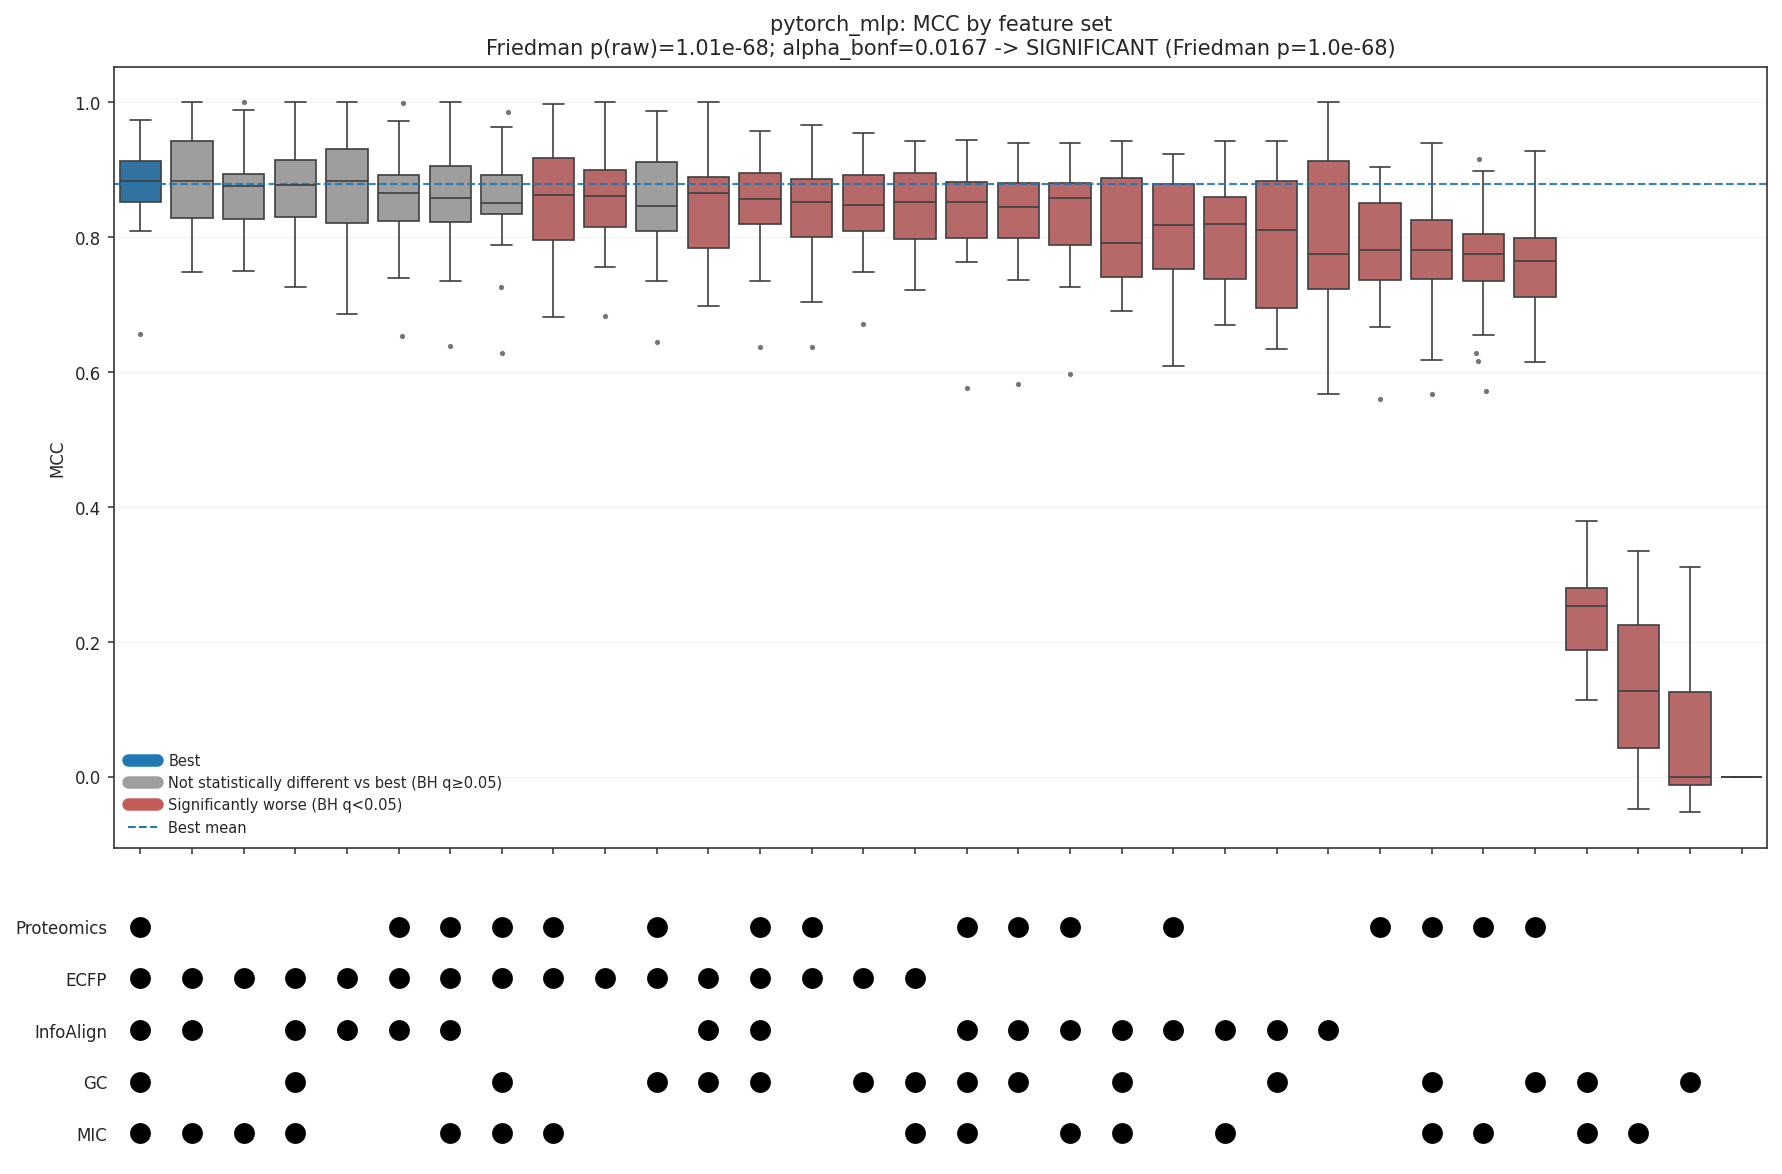

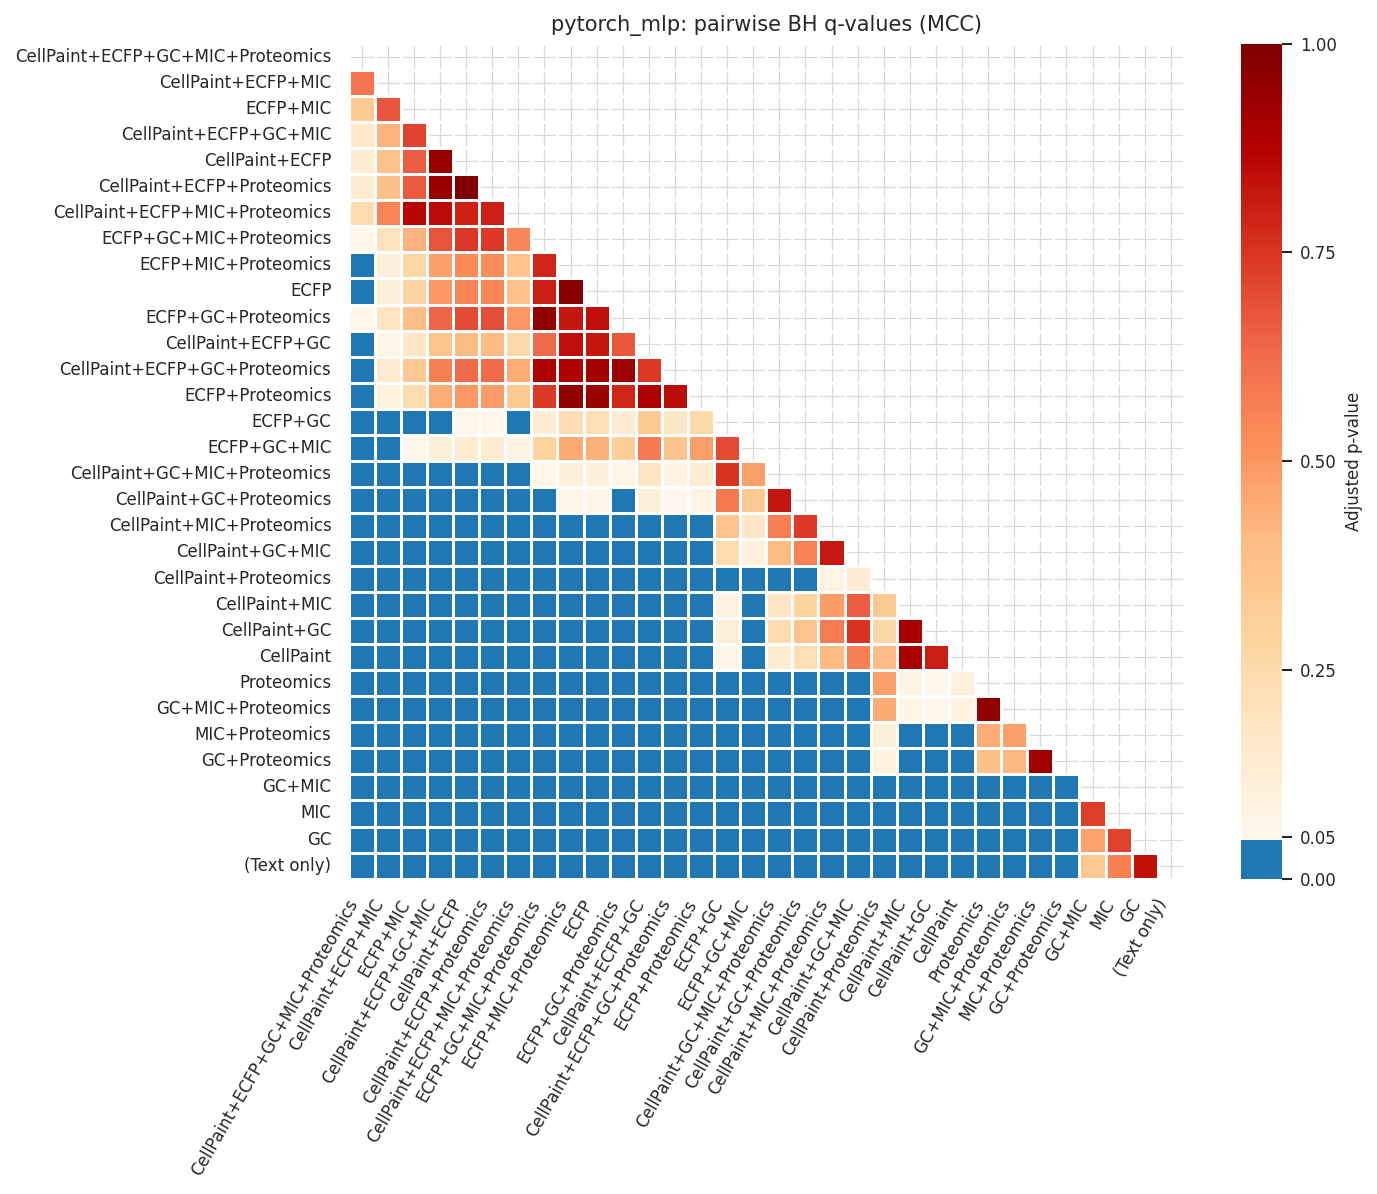

/tmp/ipykernel_6852/3597690819.py:142: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


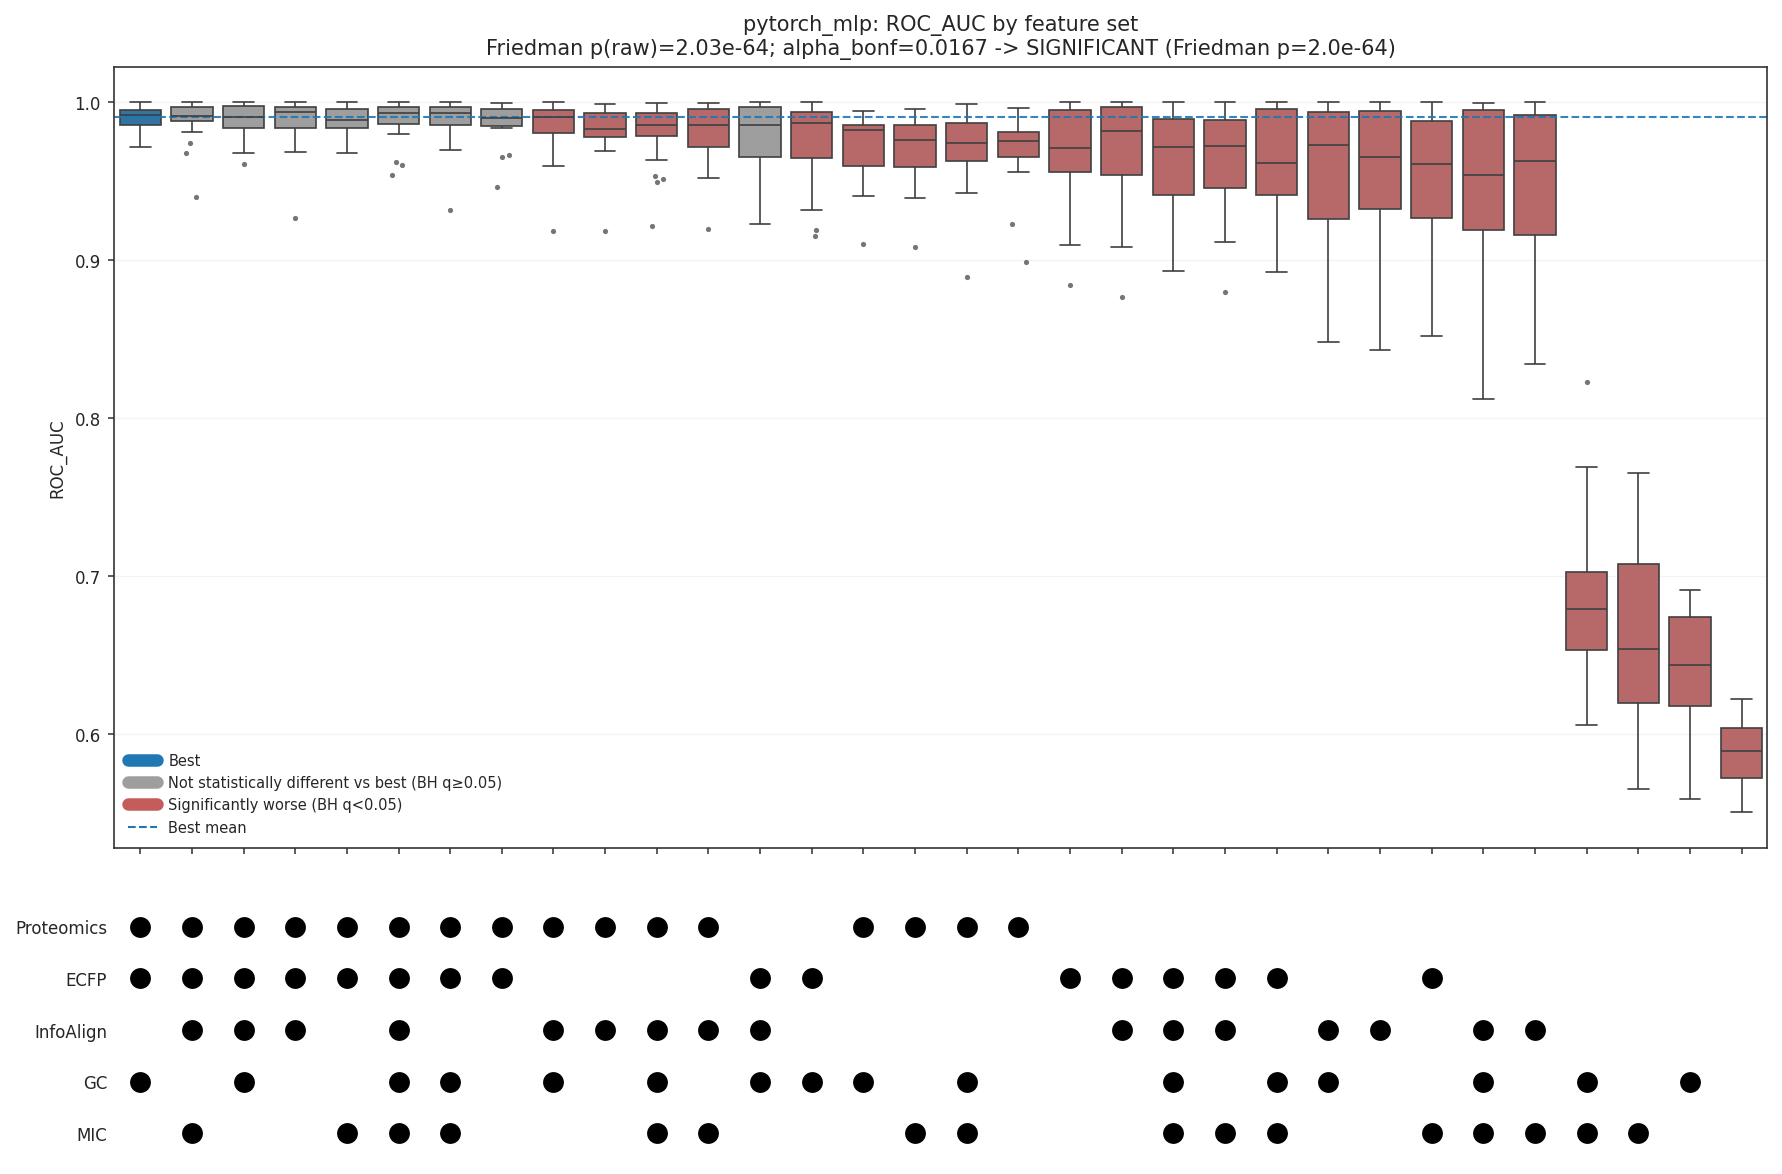

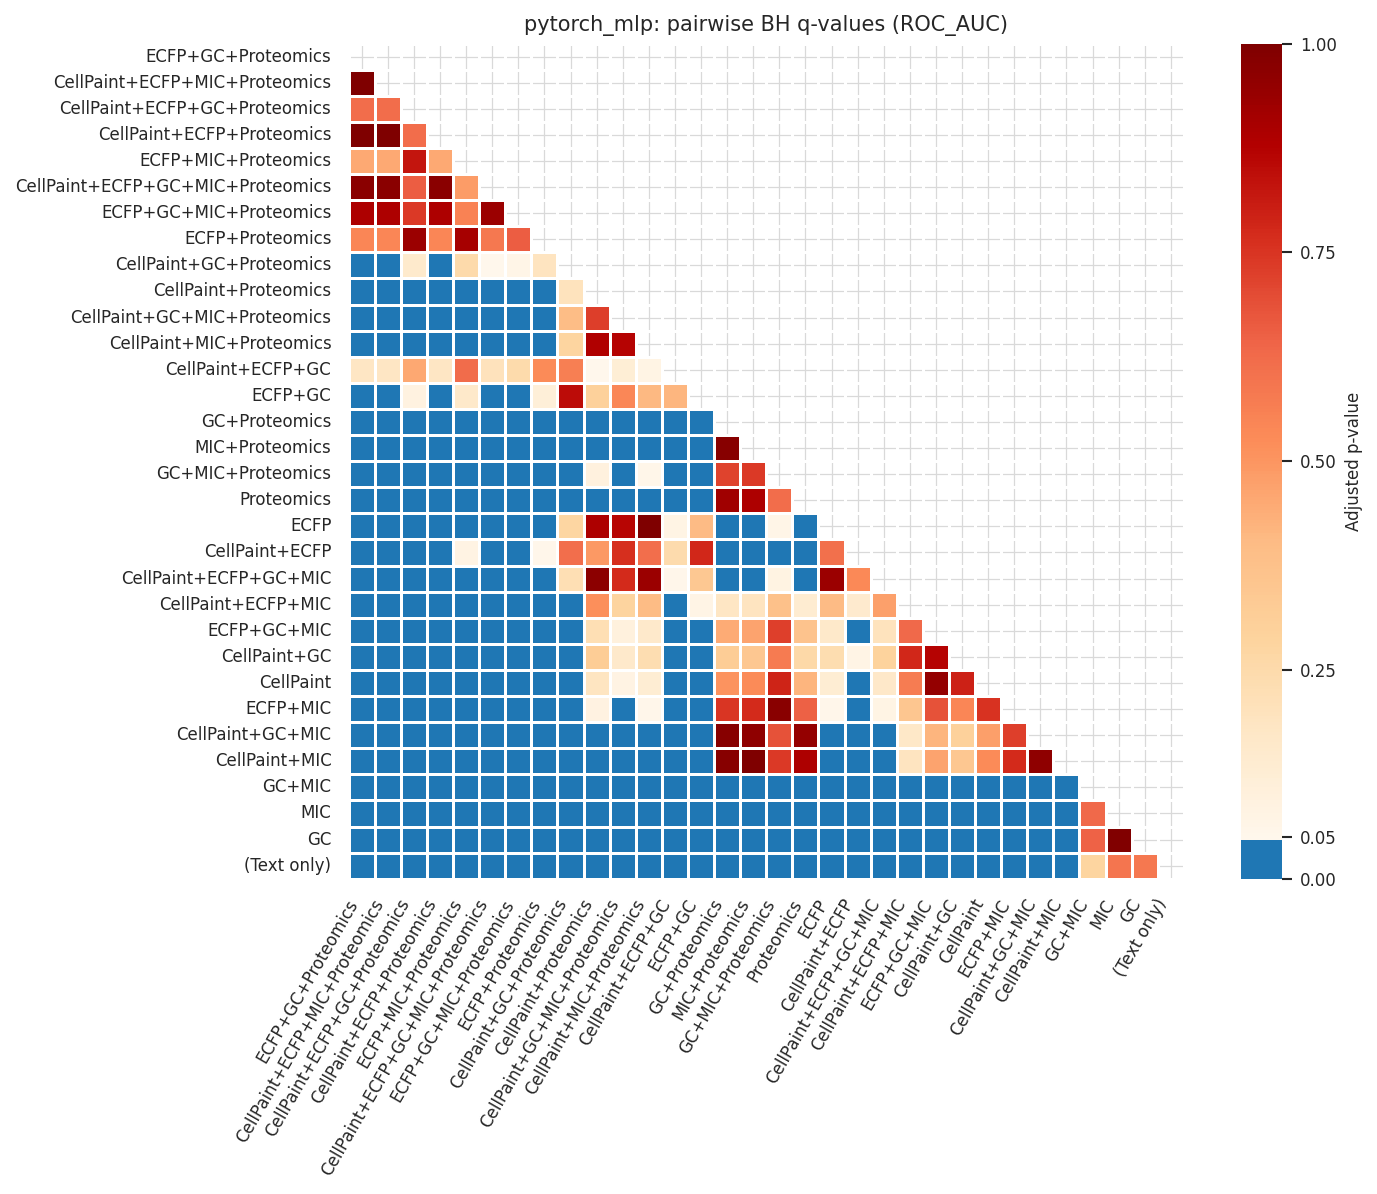

/tmp/ipykernel_6852/3597690819.py:142: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


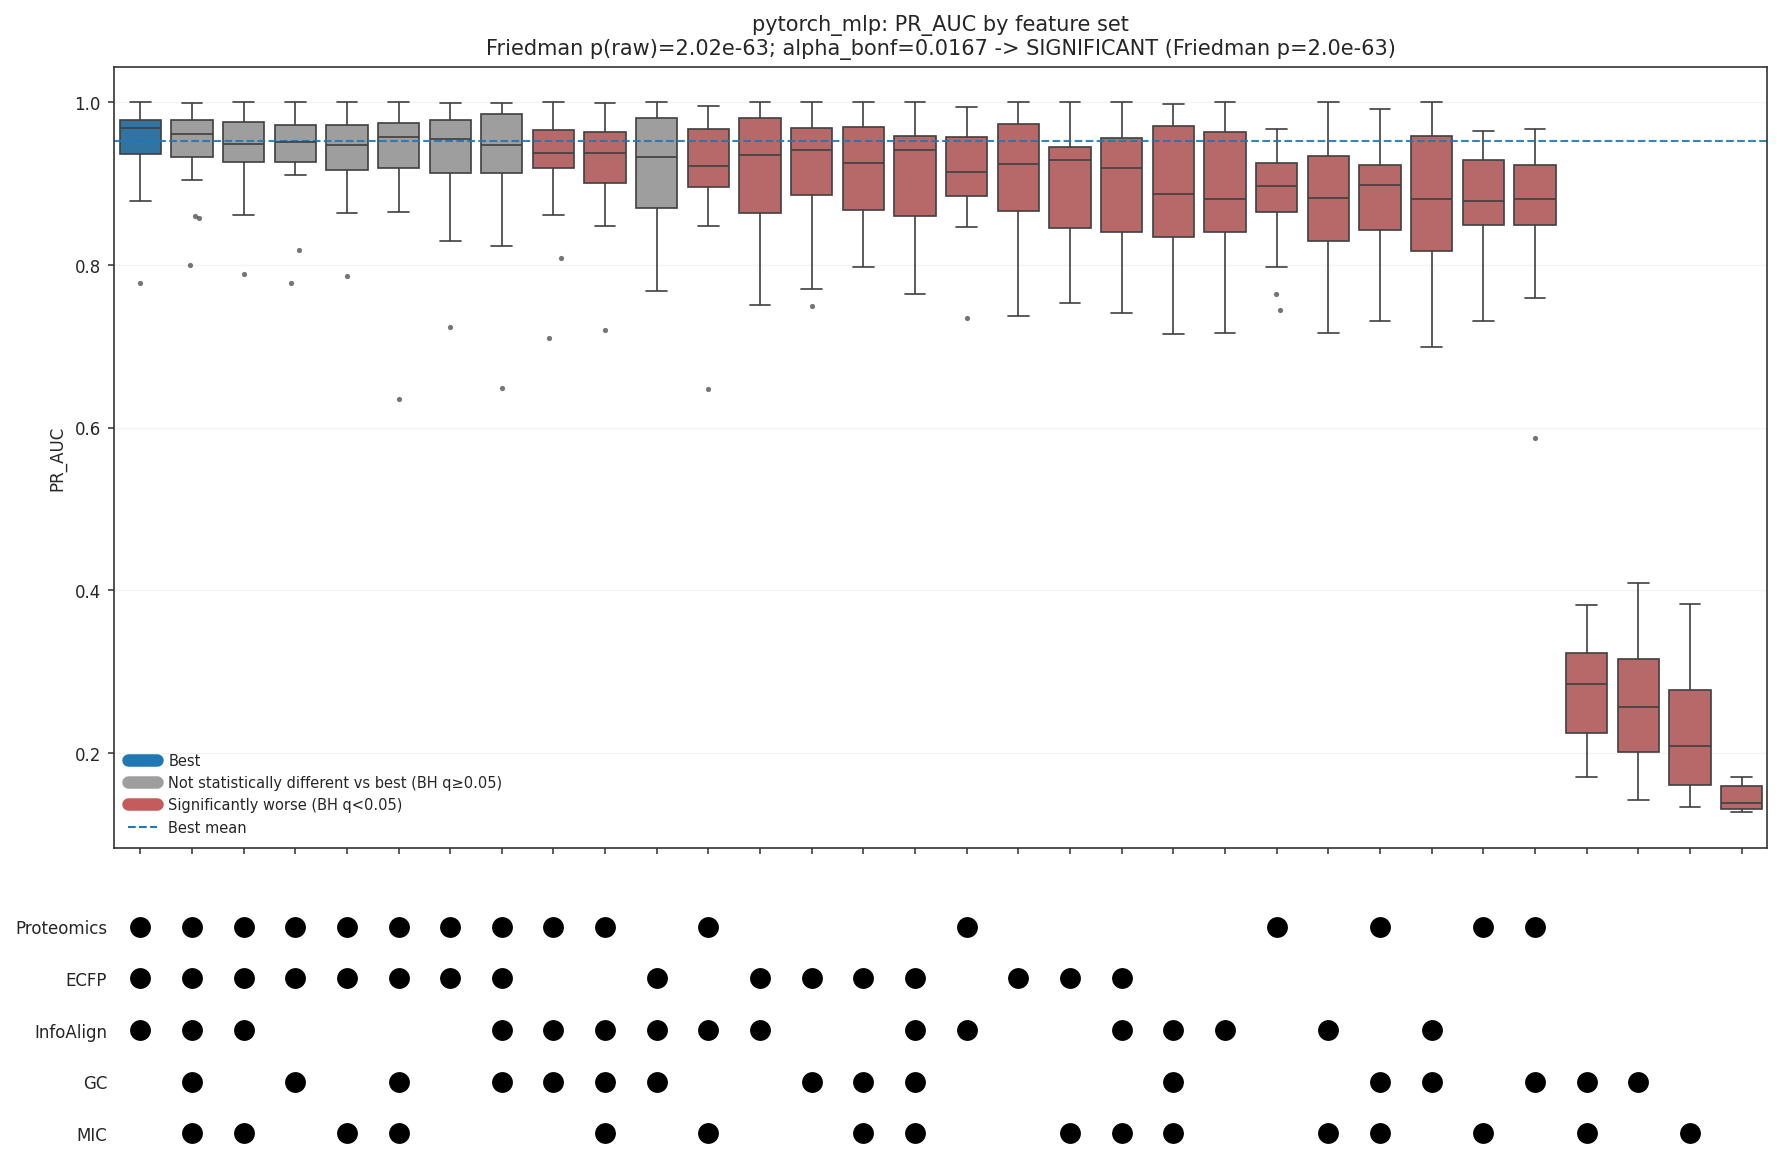

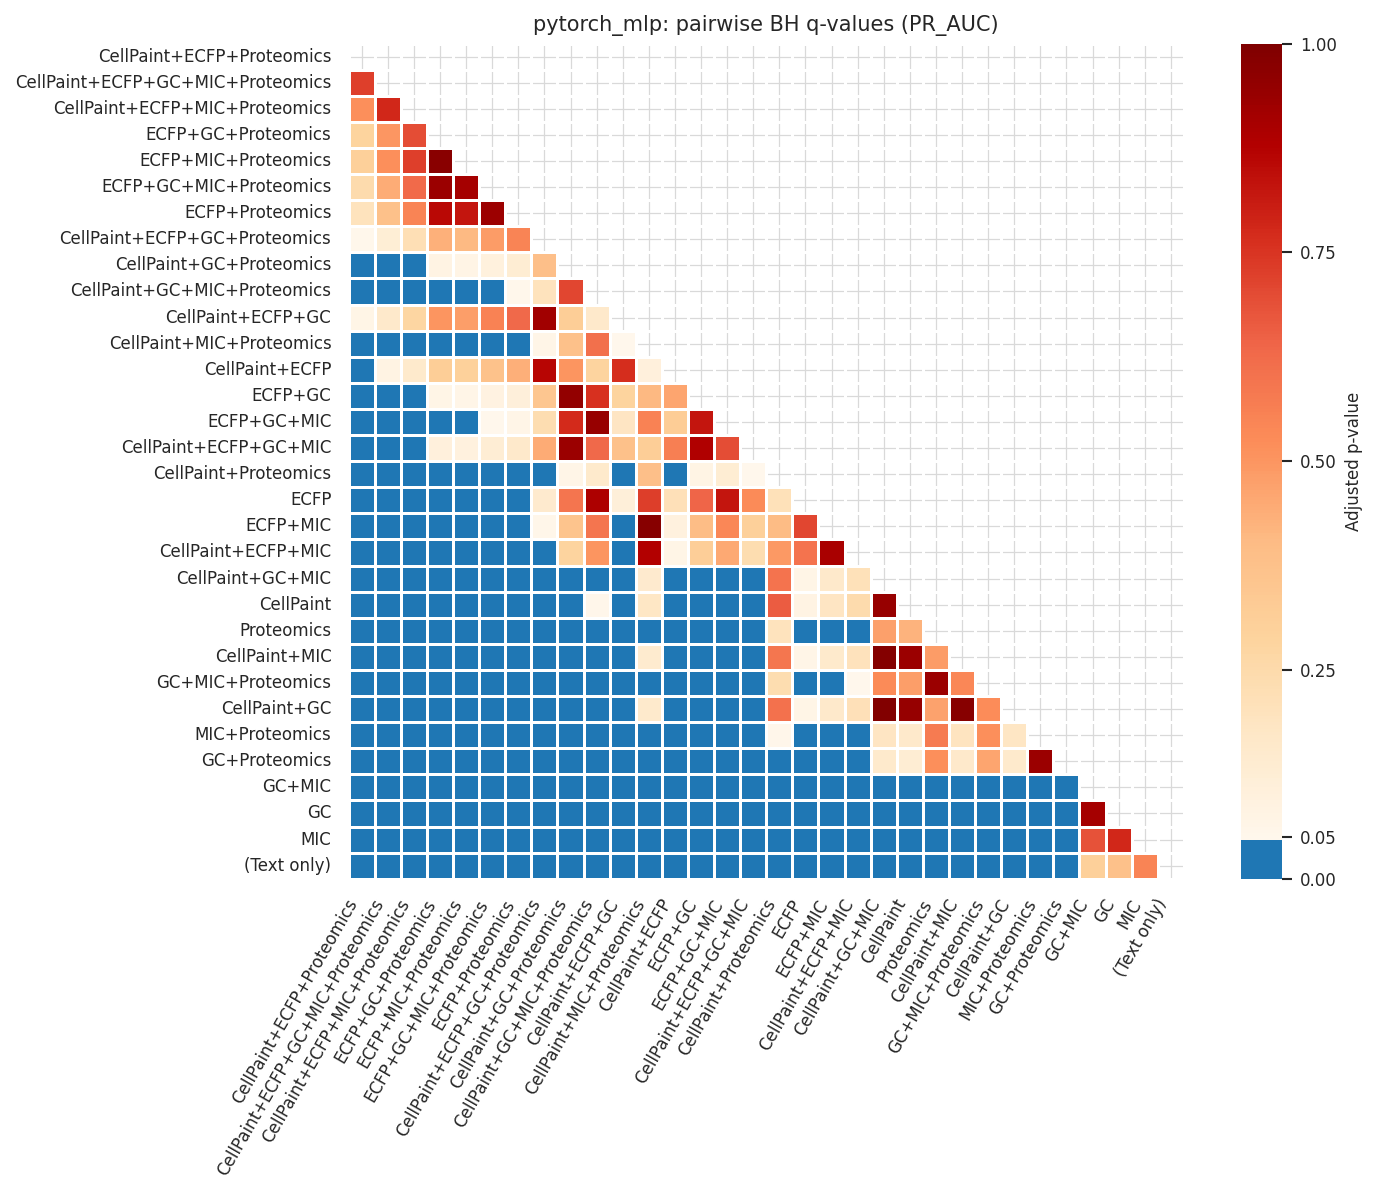


=== MODEL: tabm ===
  Bonferroni omnibus alpha across metrics: 0.016667 (m=3)


/tmp/ipykernel_6852/3597690819.py:142: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


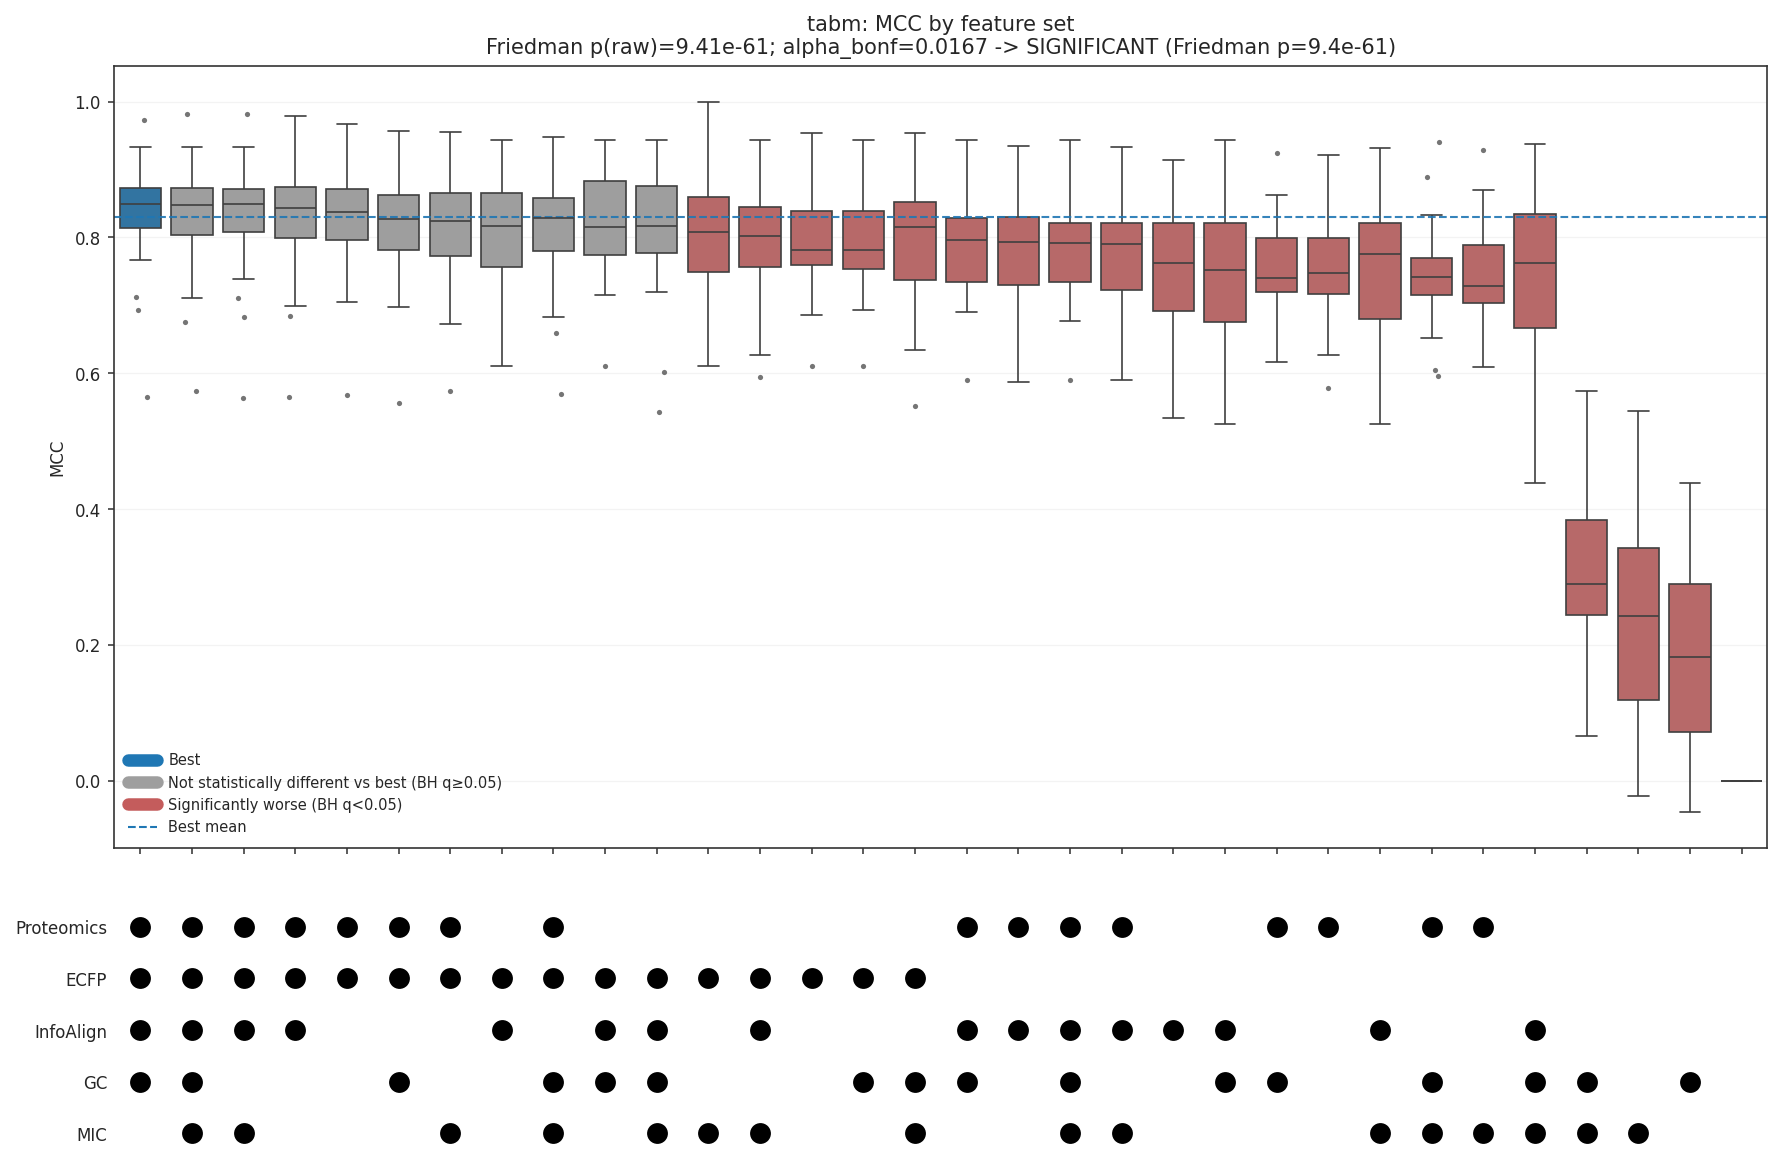

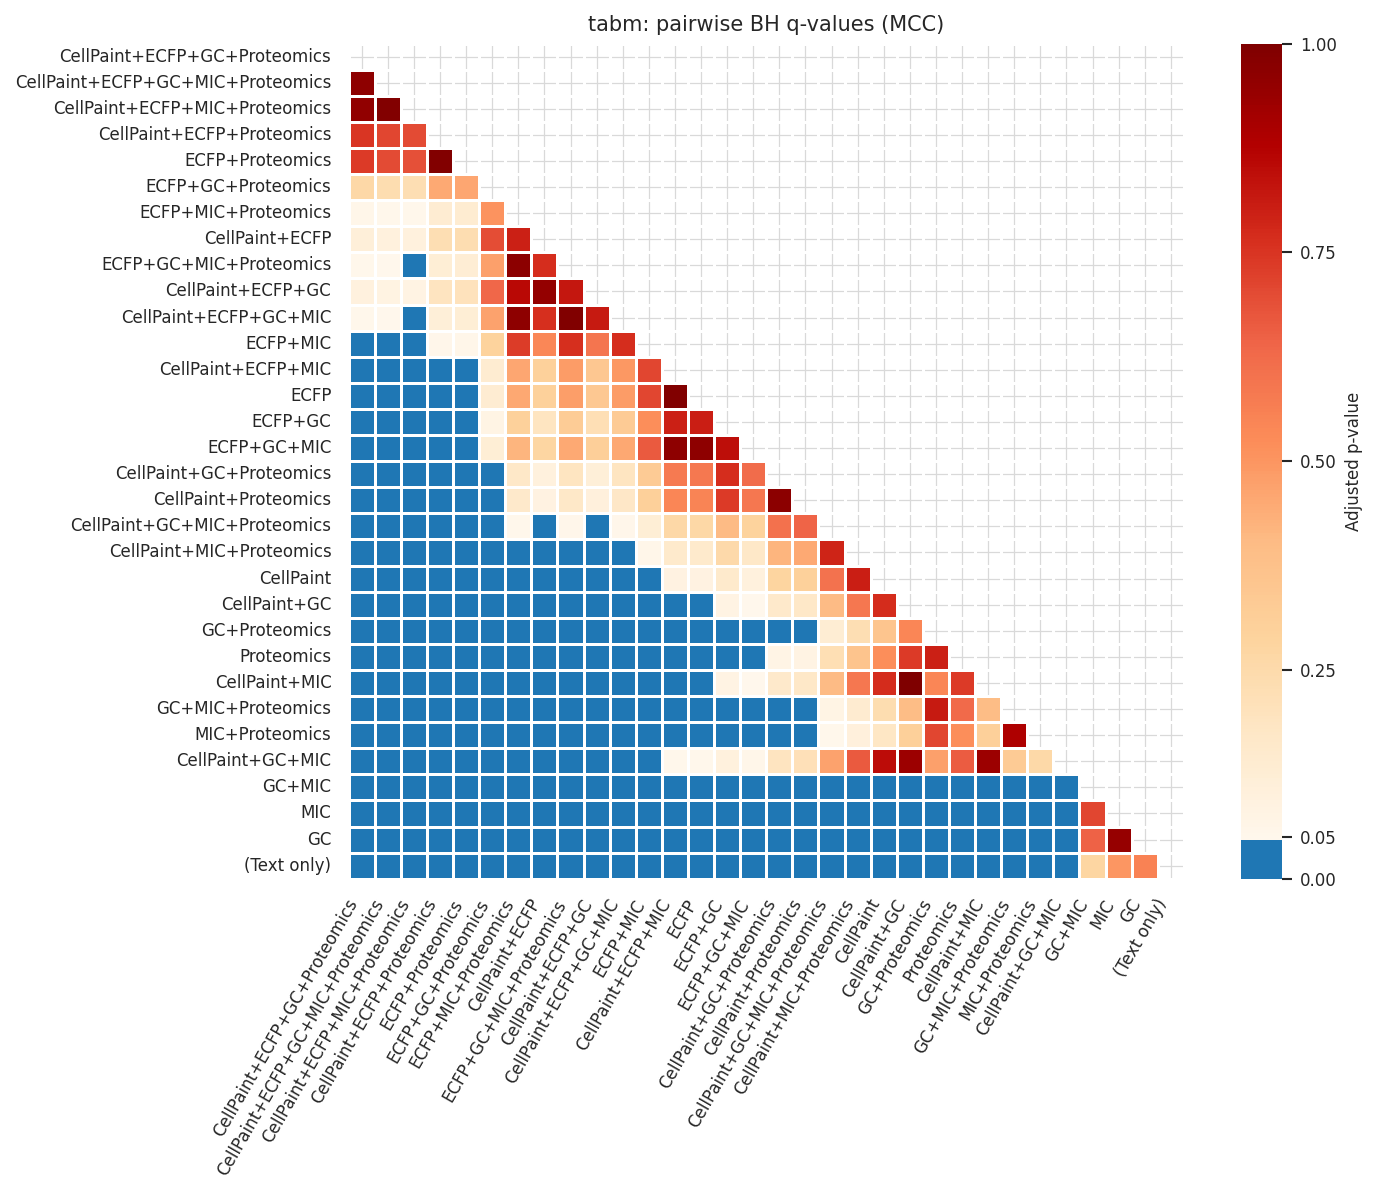

/tmp/ipykernel_6852/3597690819.py:142: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


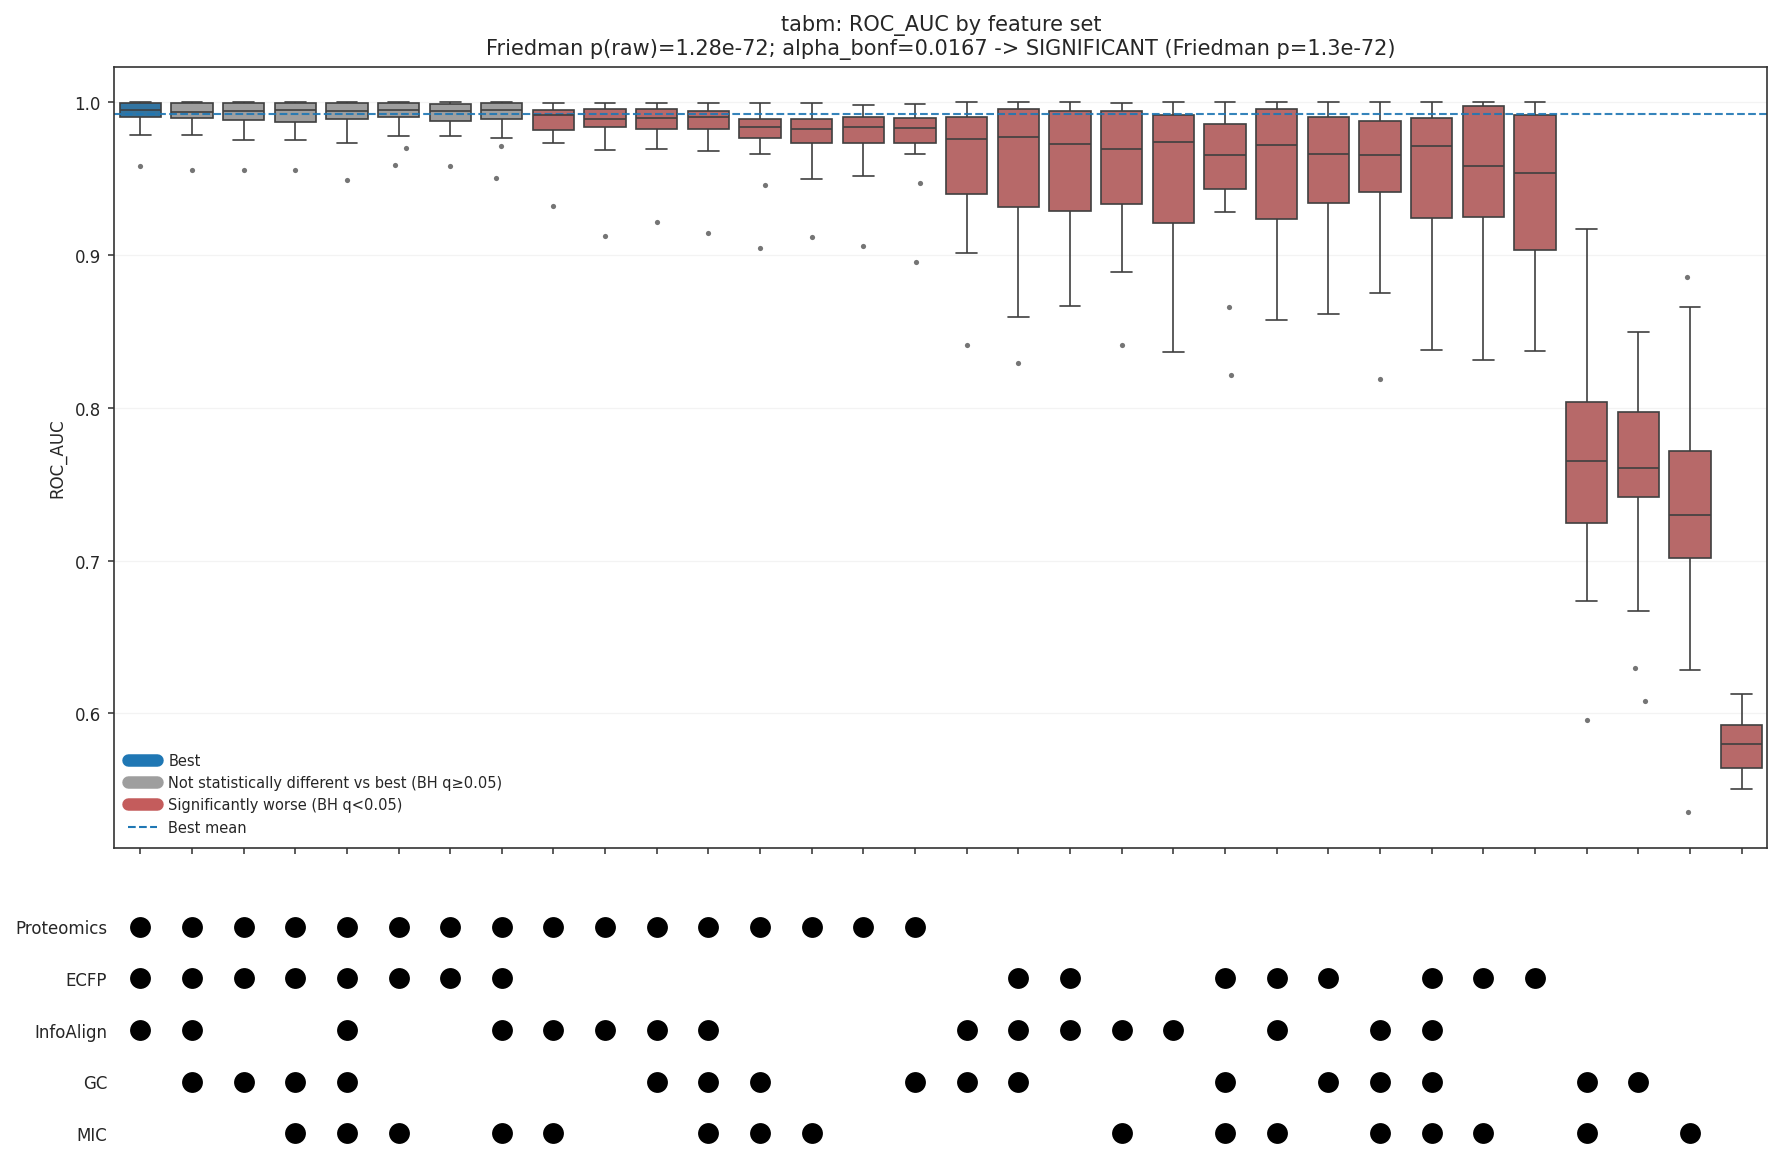

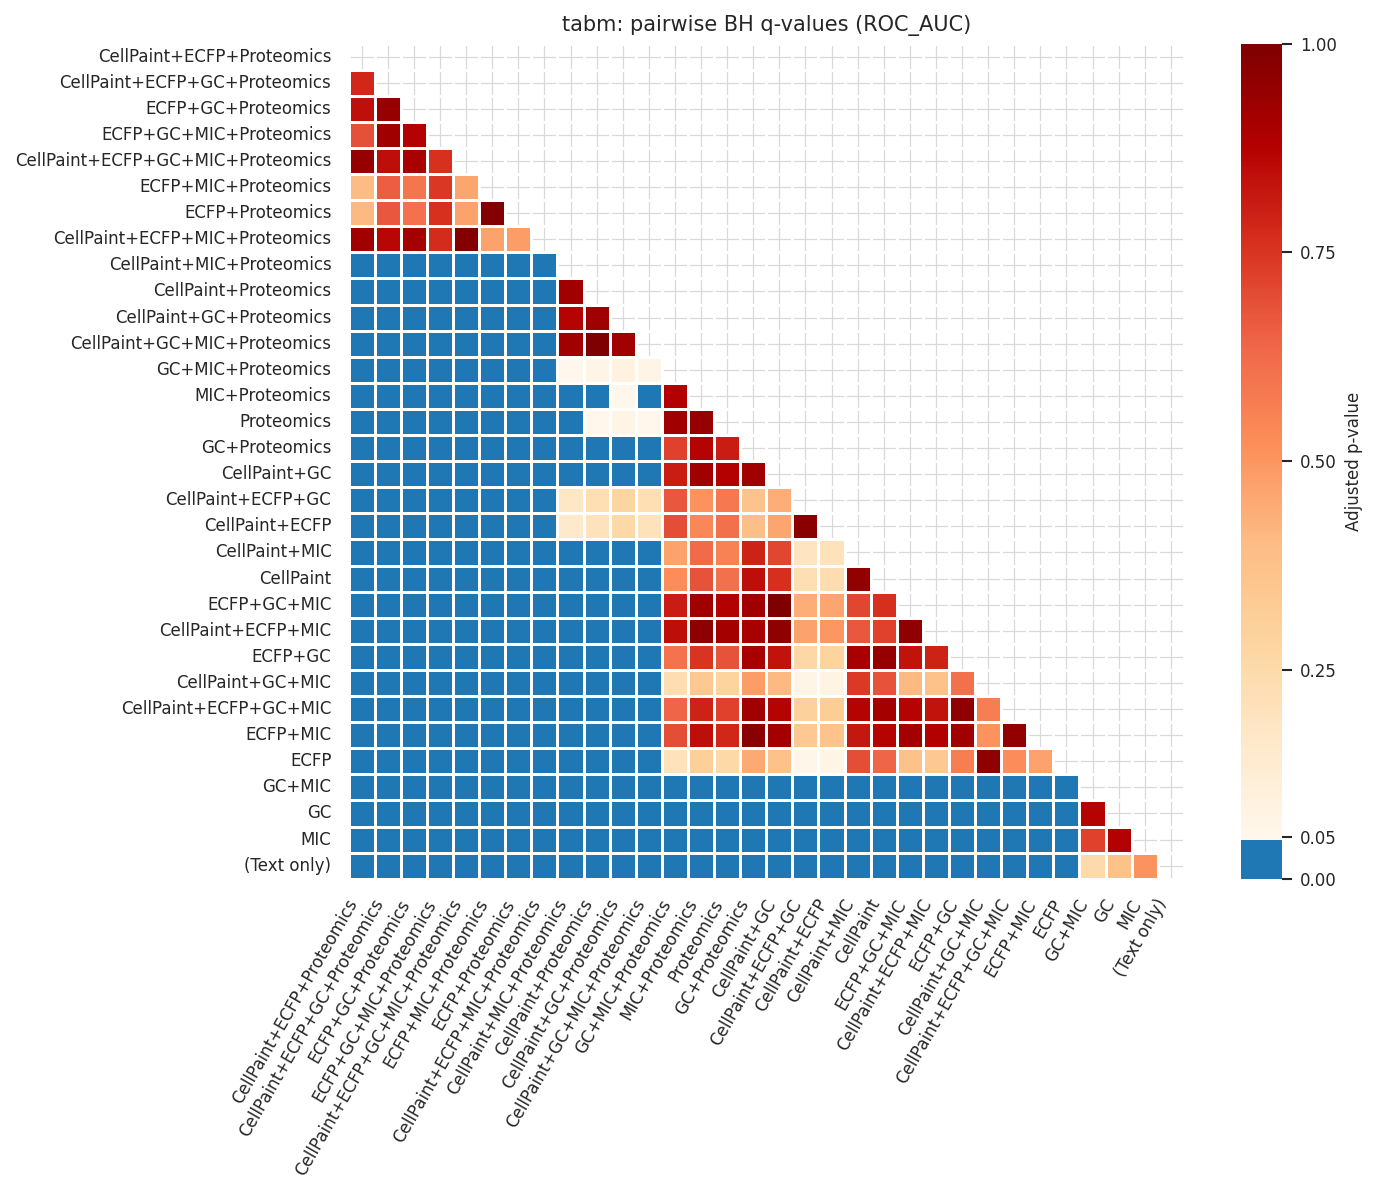

/tmp/ipykernel_6852/3597690819.py:142: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


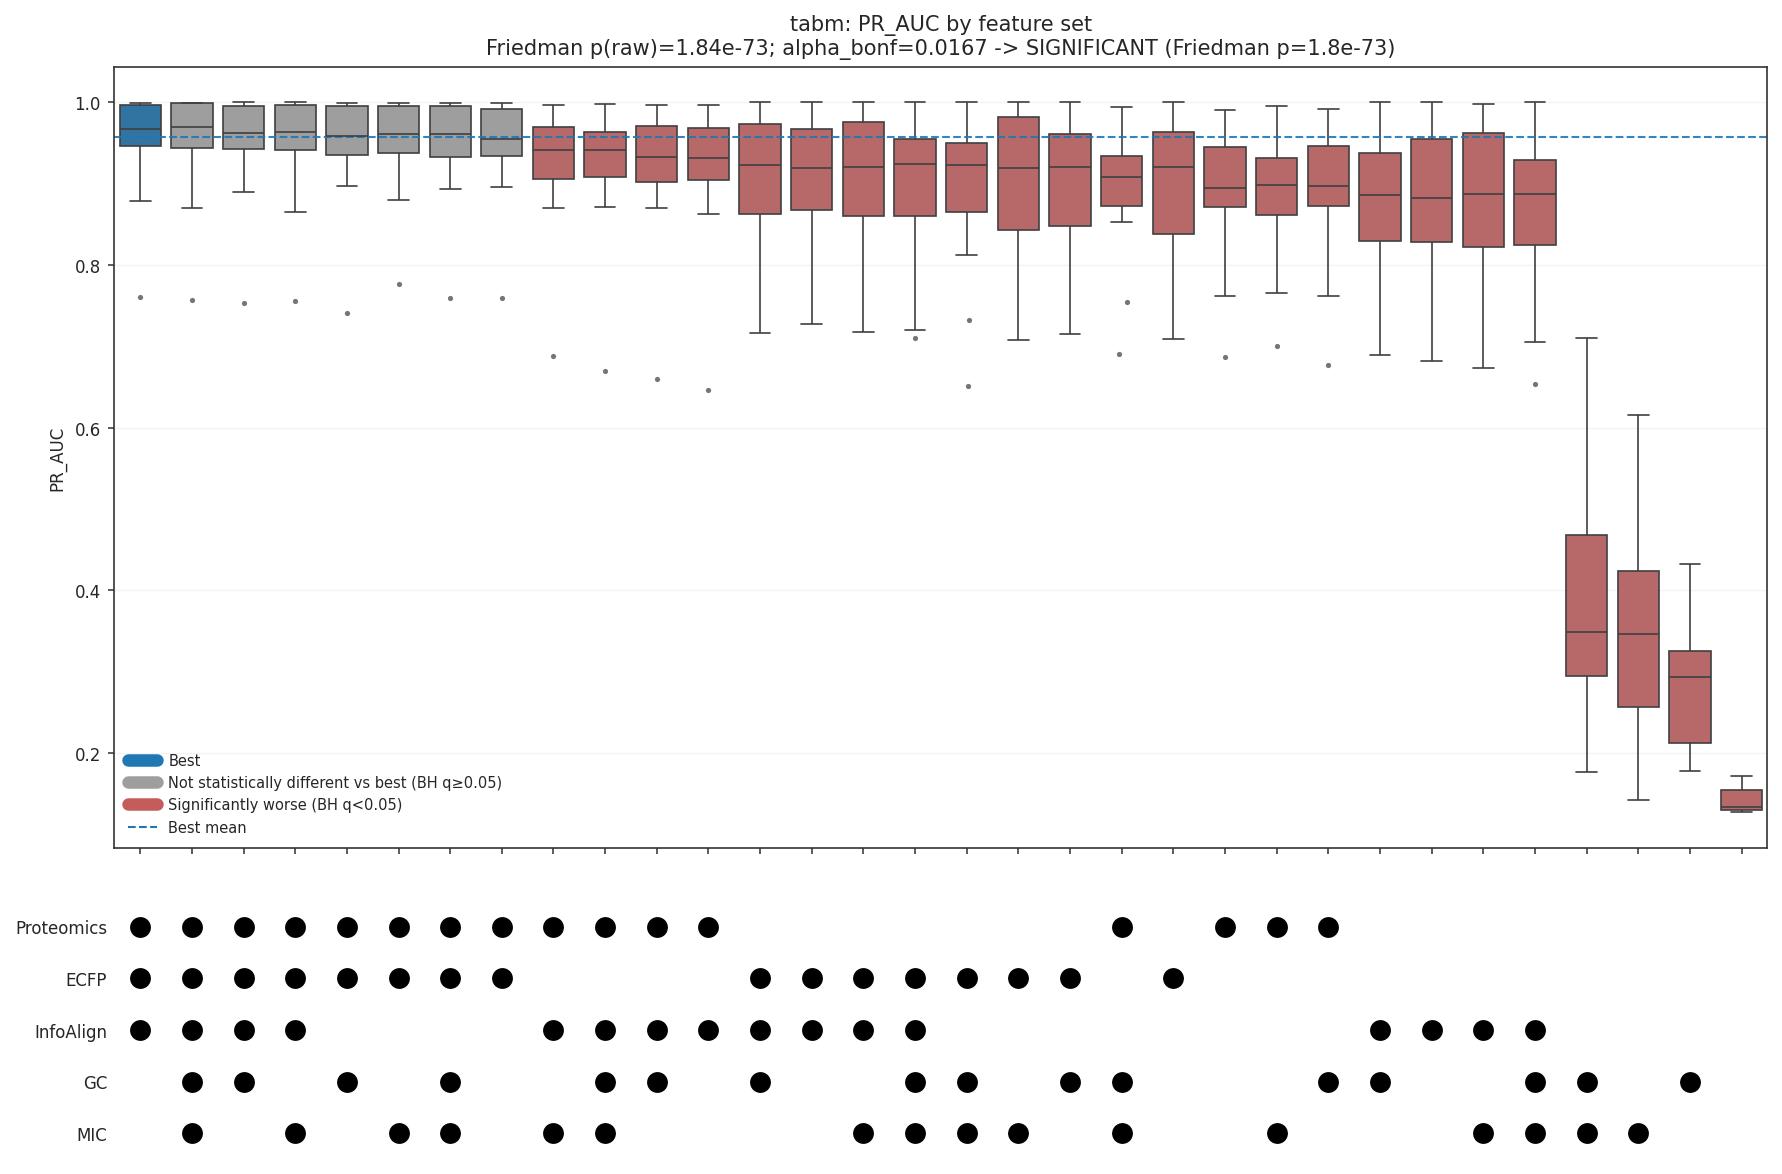

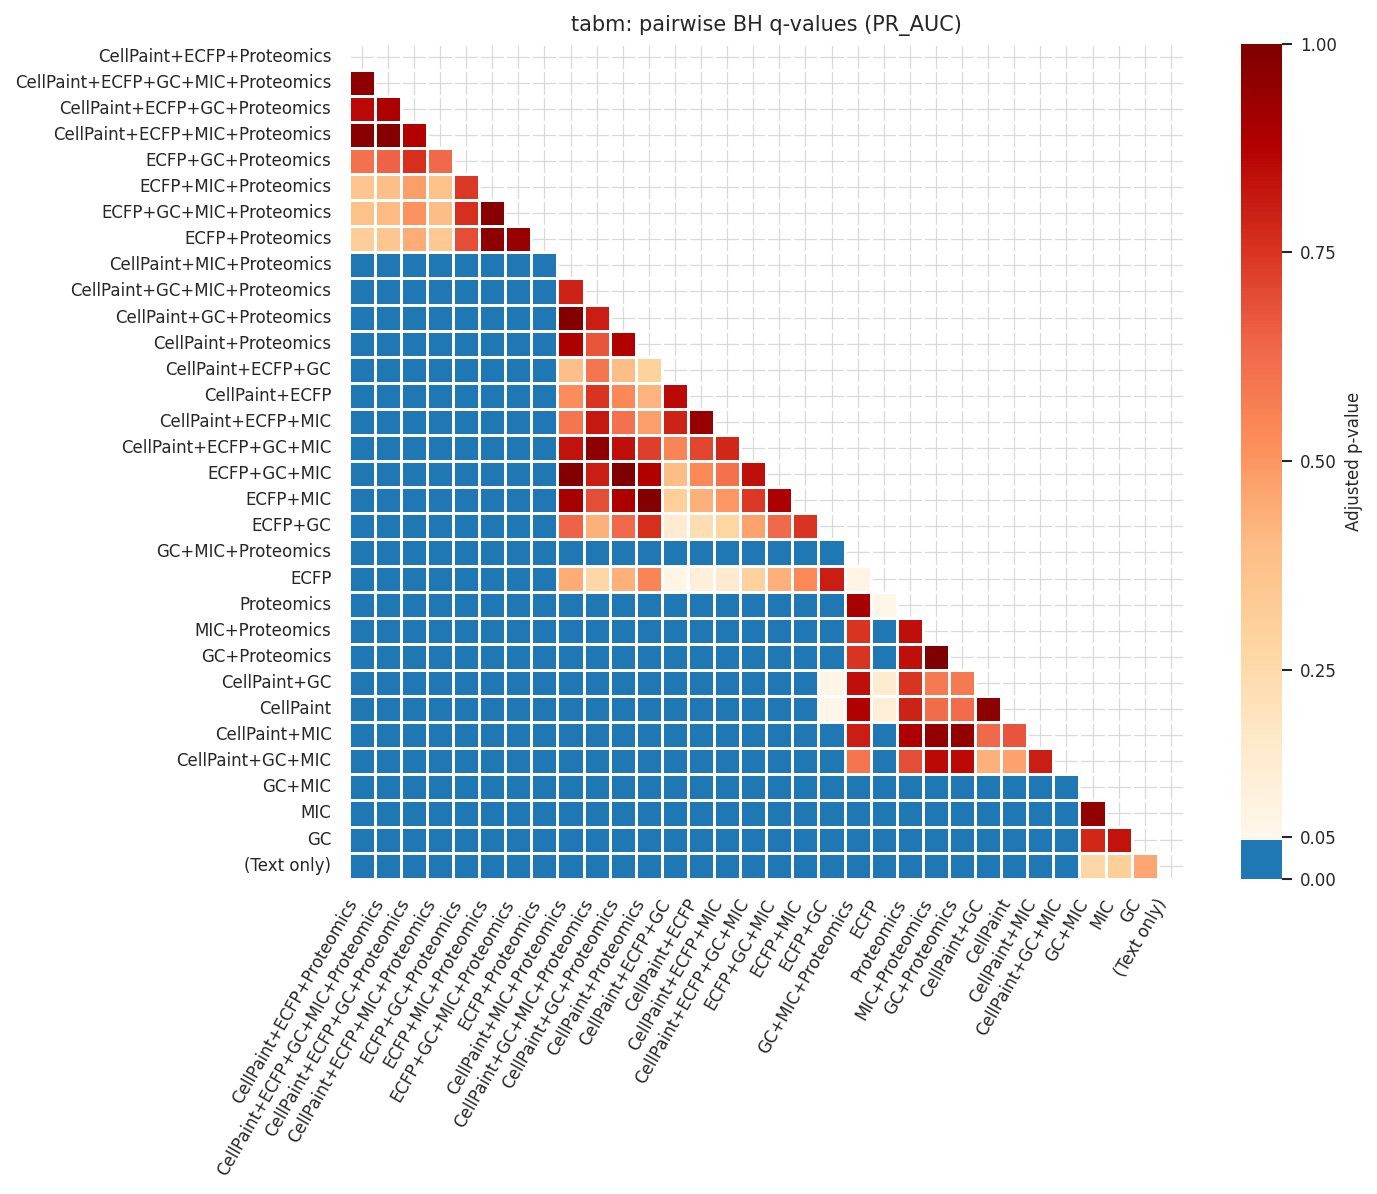


=== MODEL: lightgbm ===
  Bonferroni omnibus alpha across metrics: 0.016667 (m=3)


/tmp/ipykernel_6852/3597690819.py:142: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


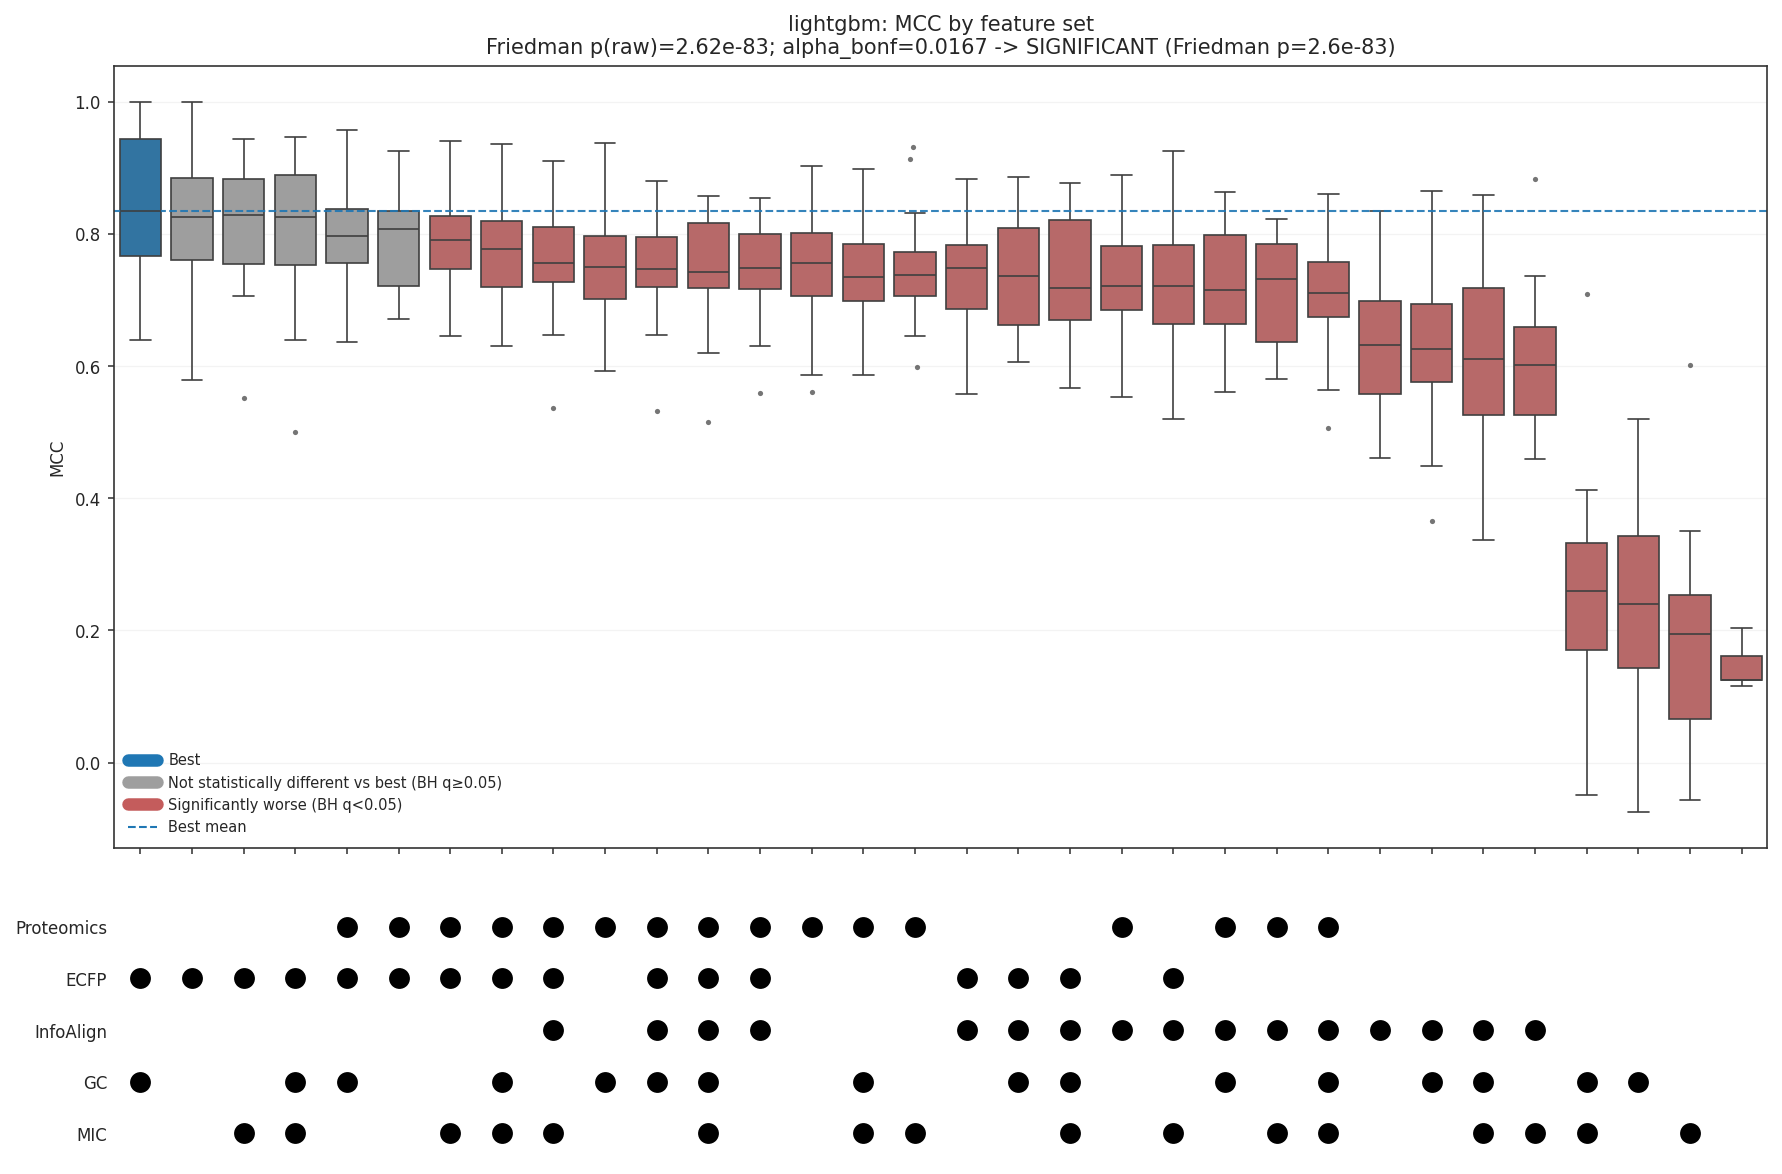

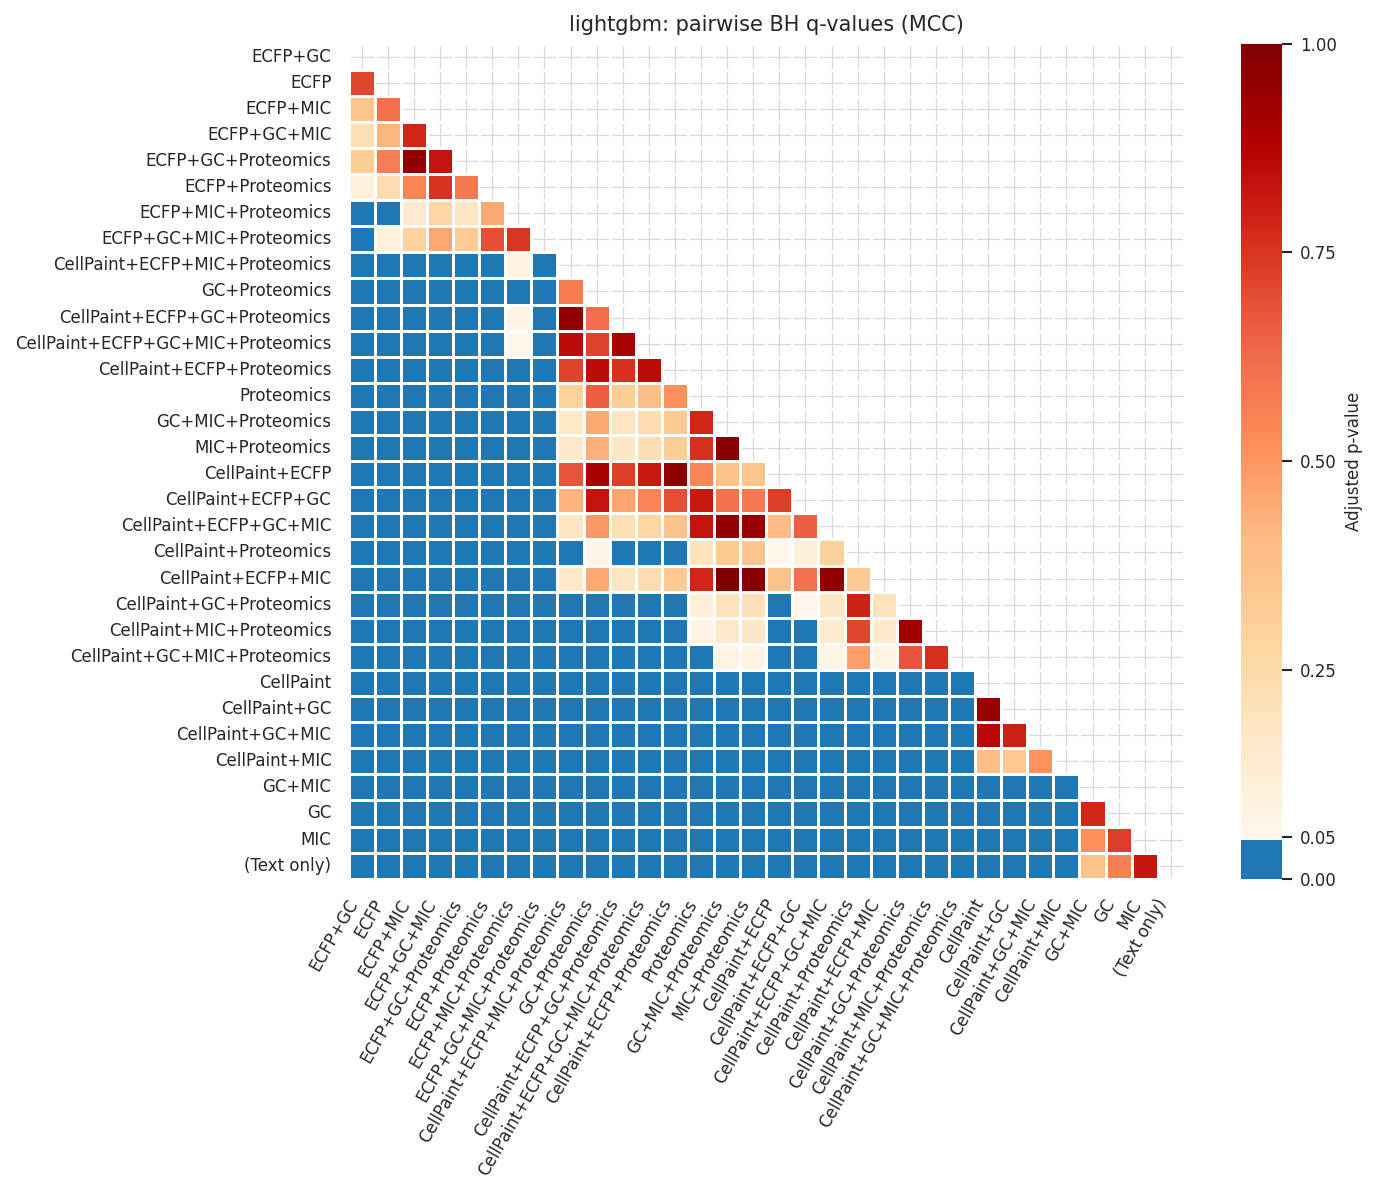

/tmp/ipykernel_6852/3597690819.py:142: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


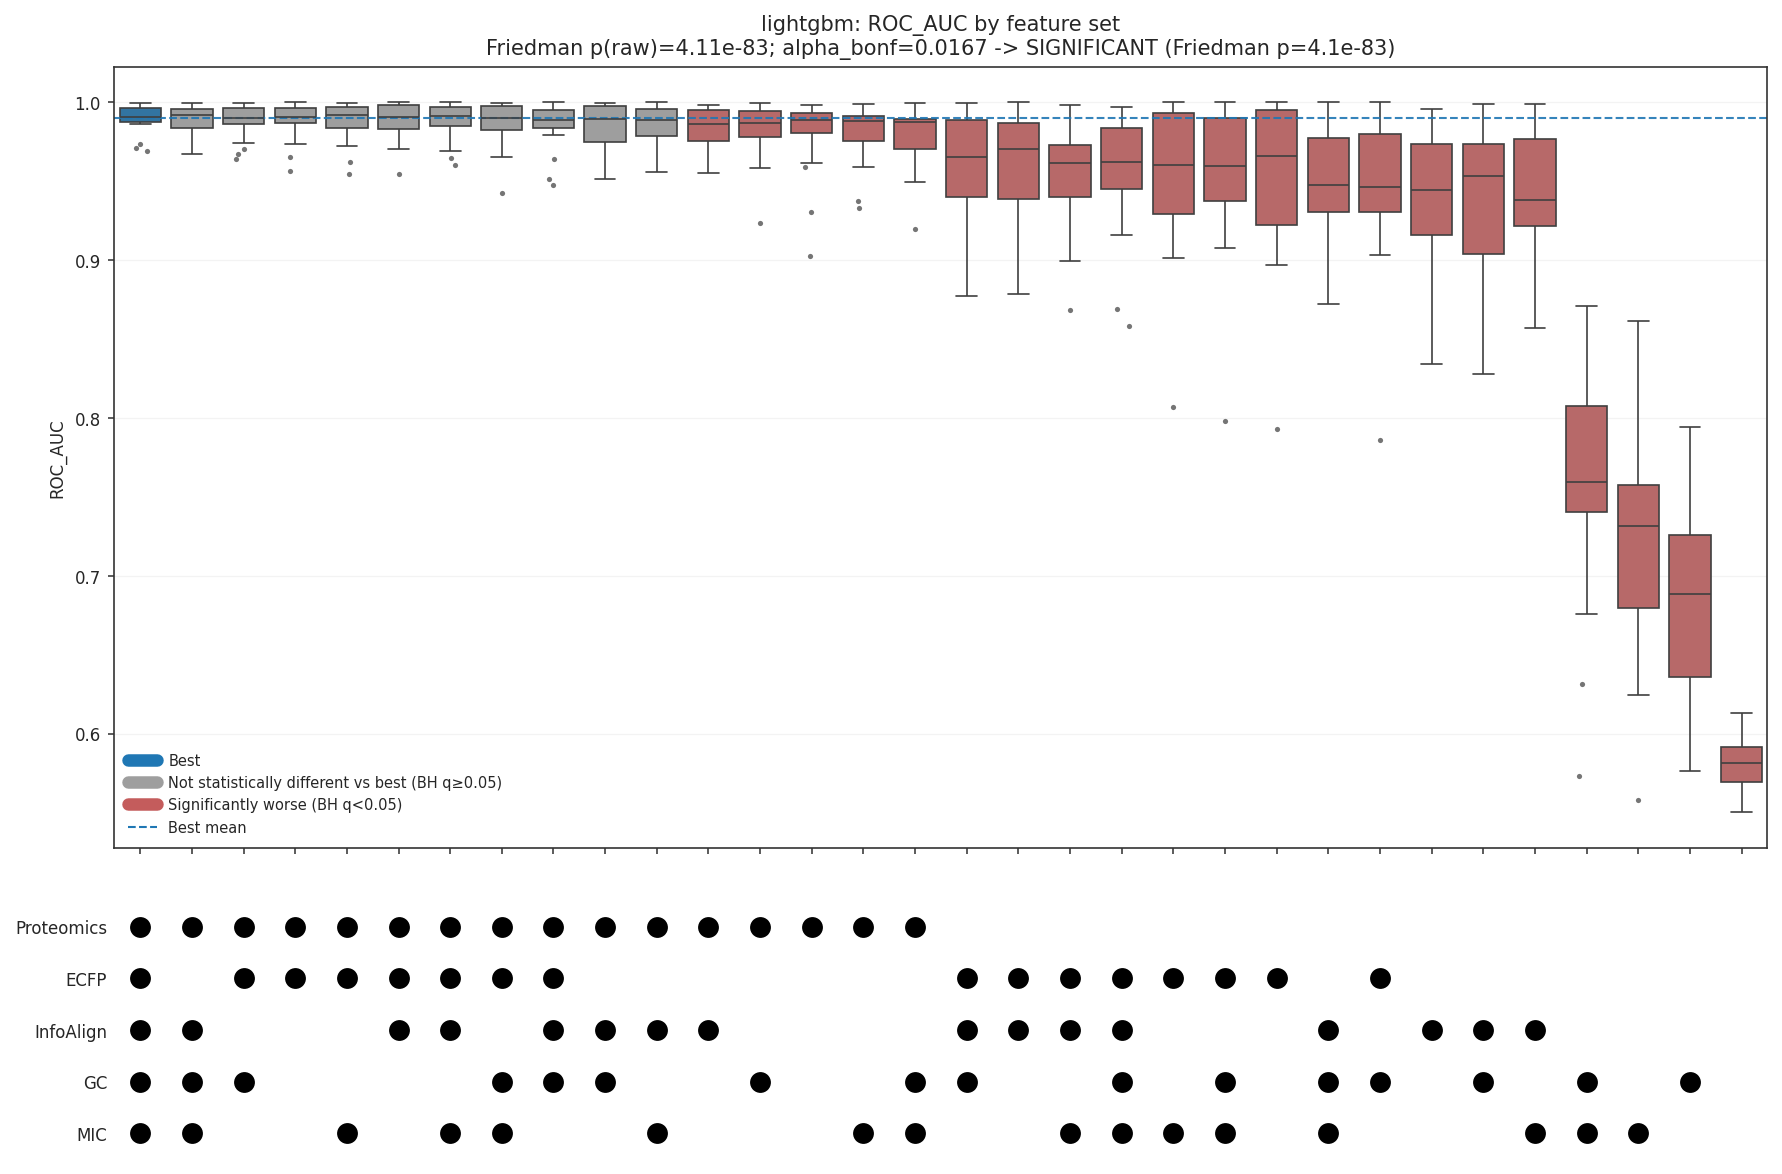

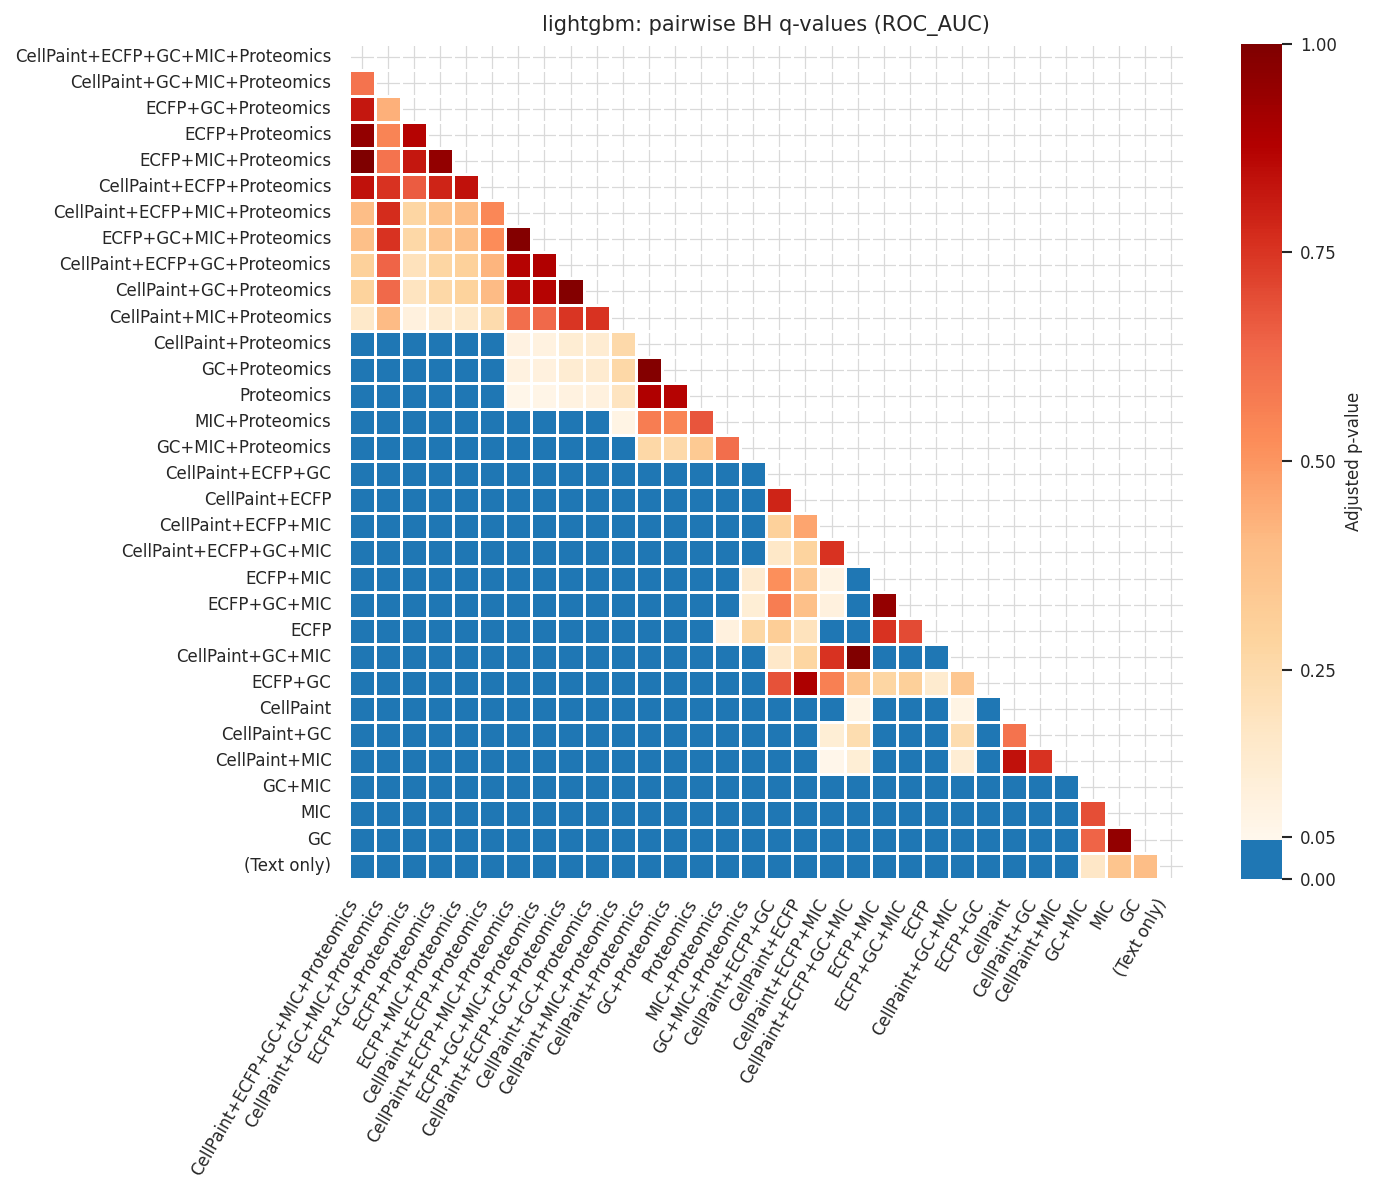

/tmp/ipykernel_6852/3597690819.py:142: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


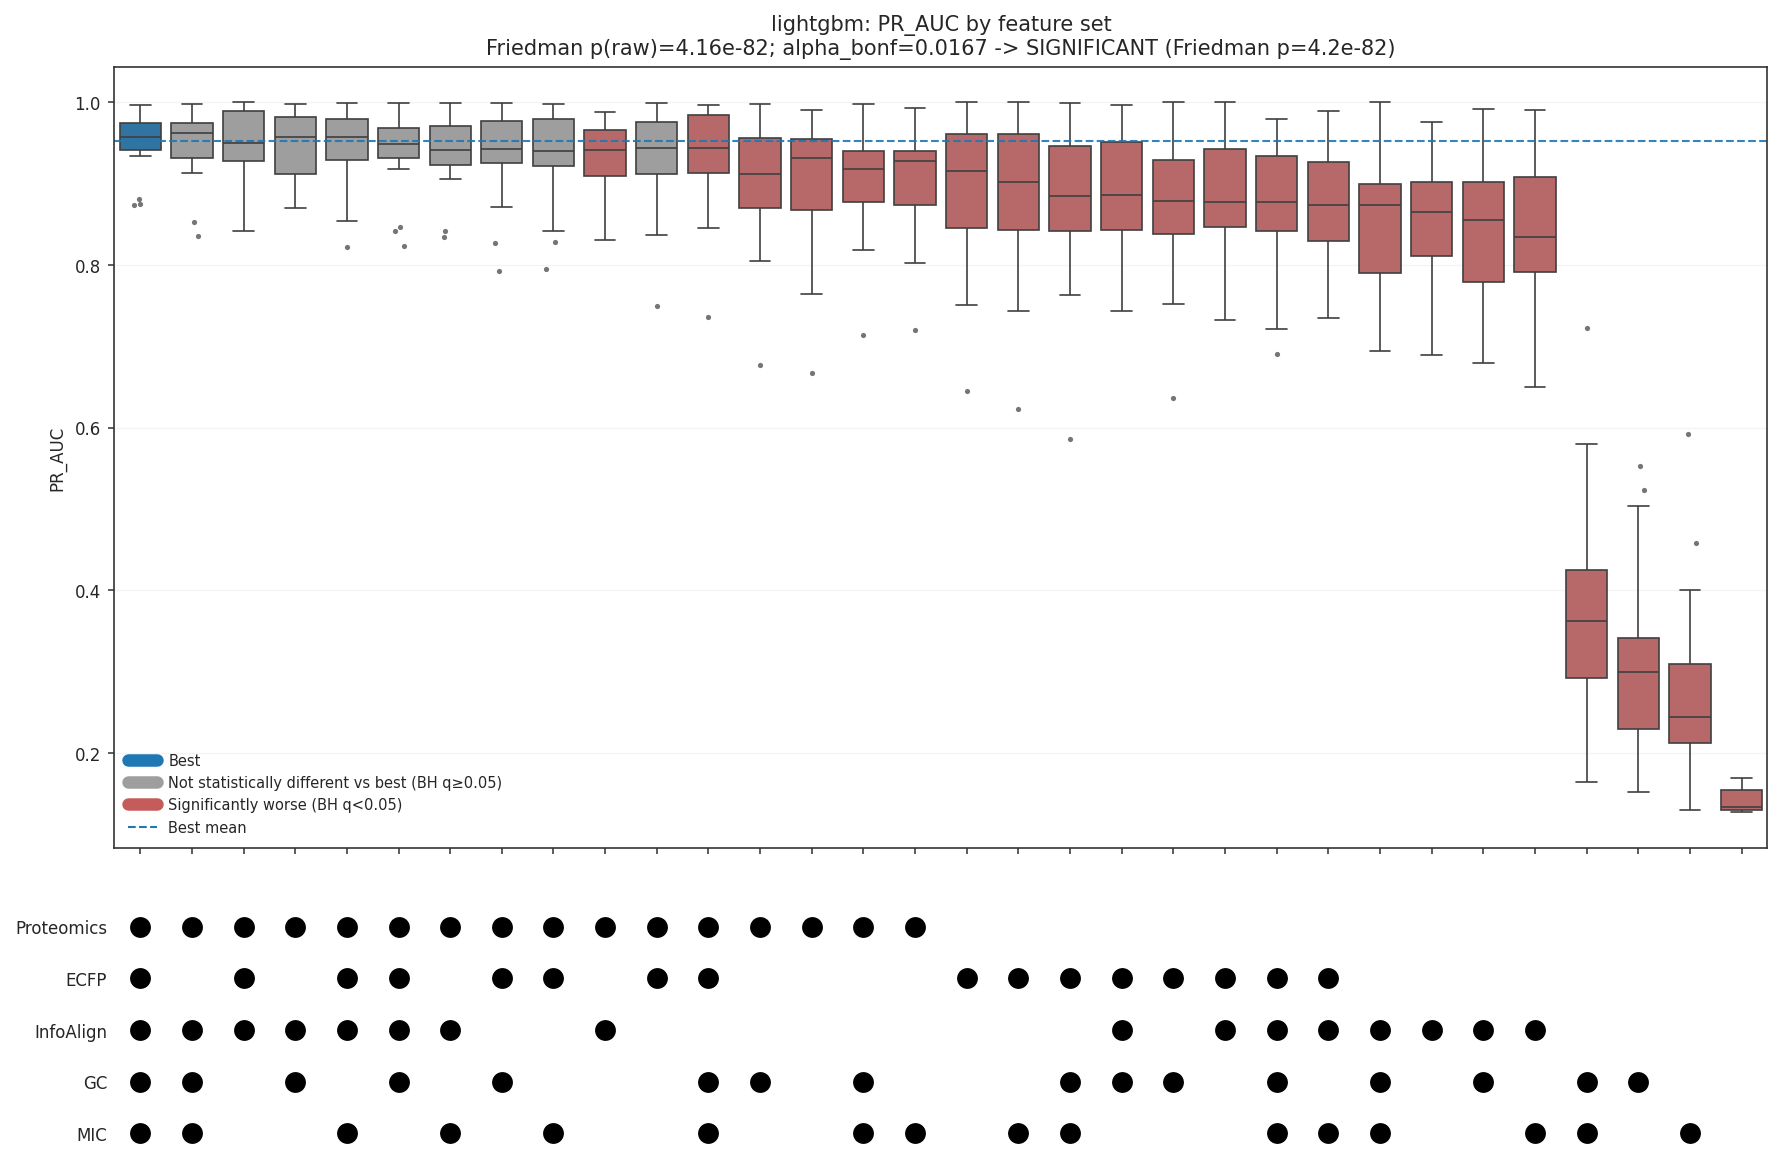

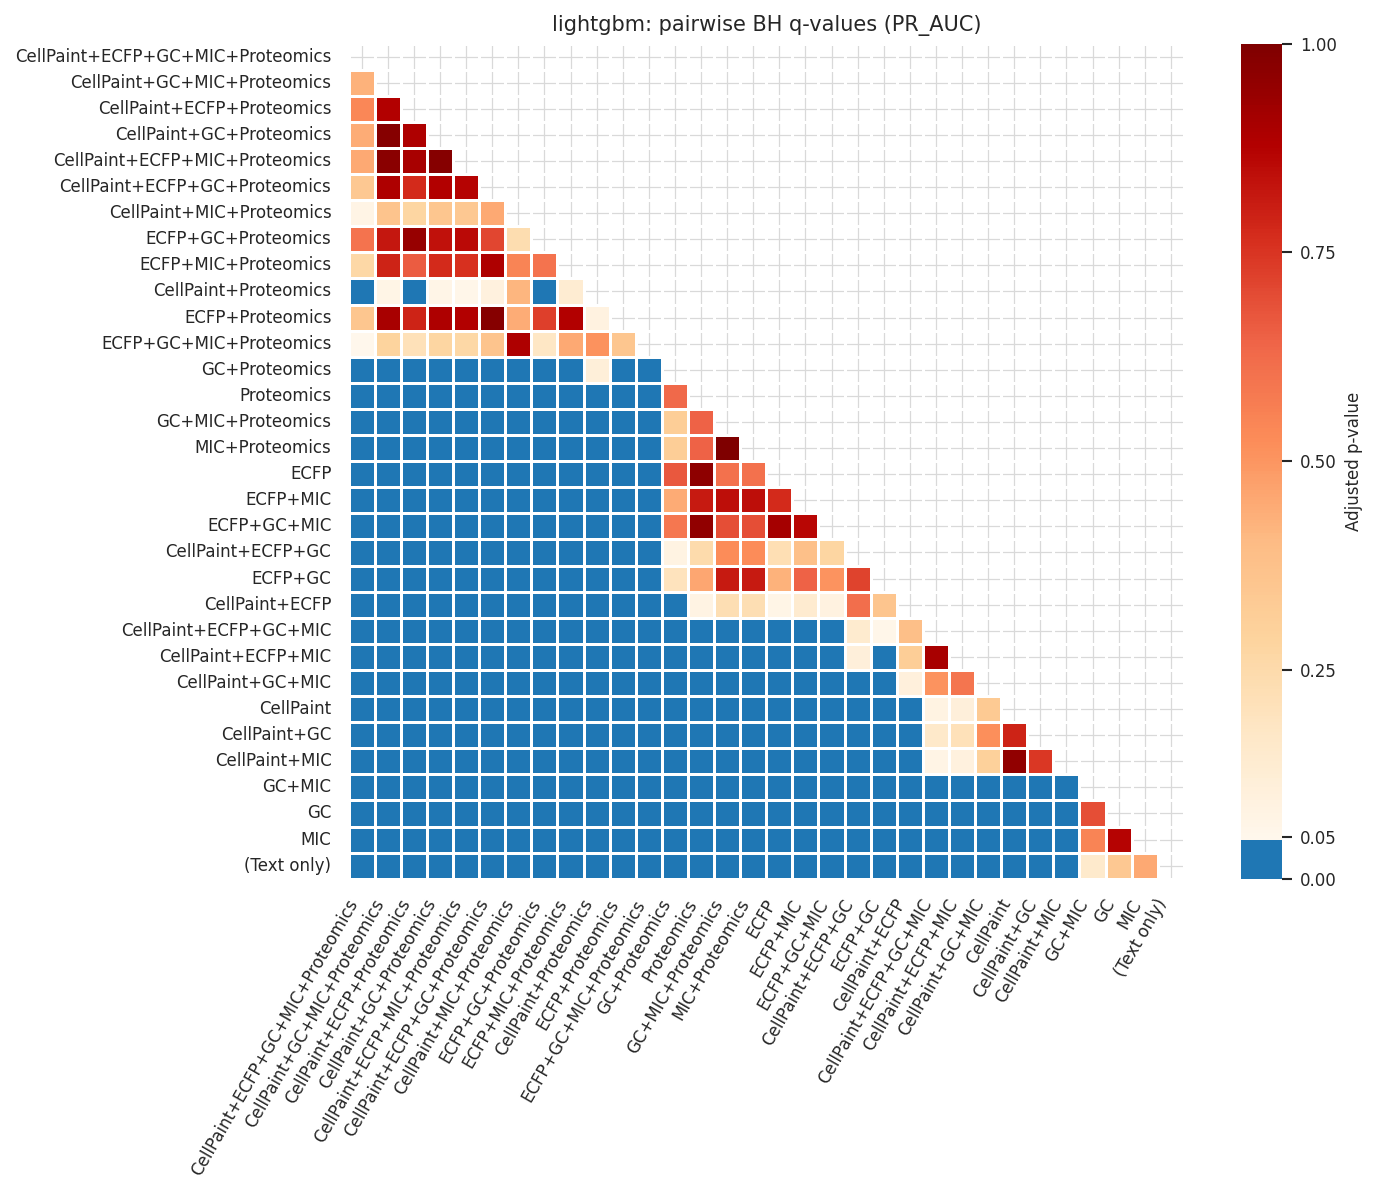


=== MODEL: mlp ===
  Bonferroni omnibus alpha across metrics: 0.016667 (m=3)


/tmp/ipykernel_6852/3597690819.py:142: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


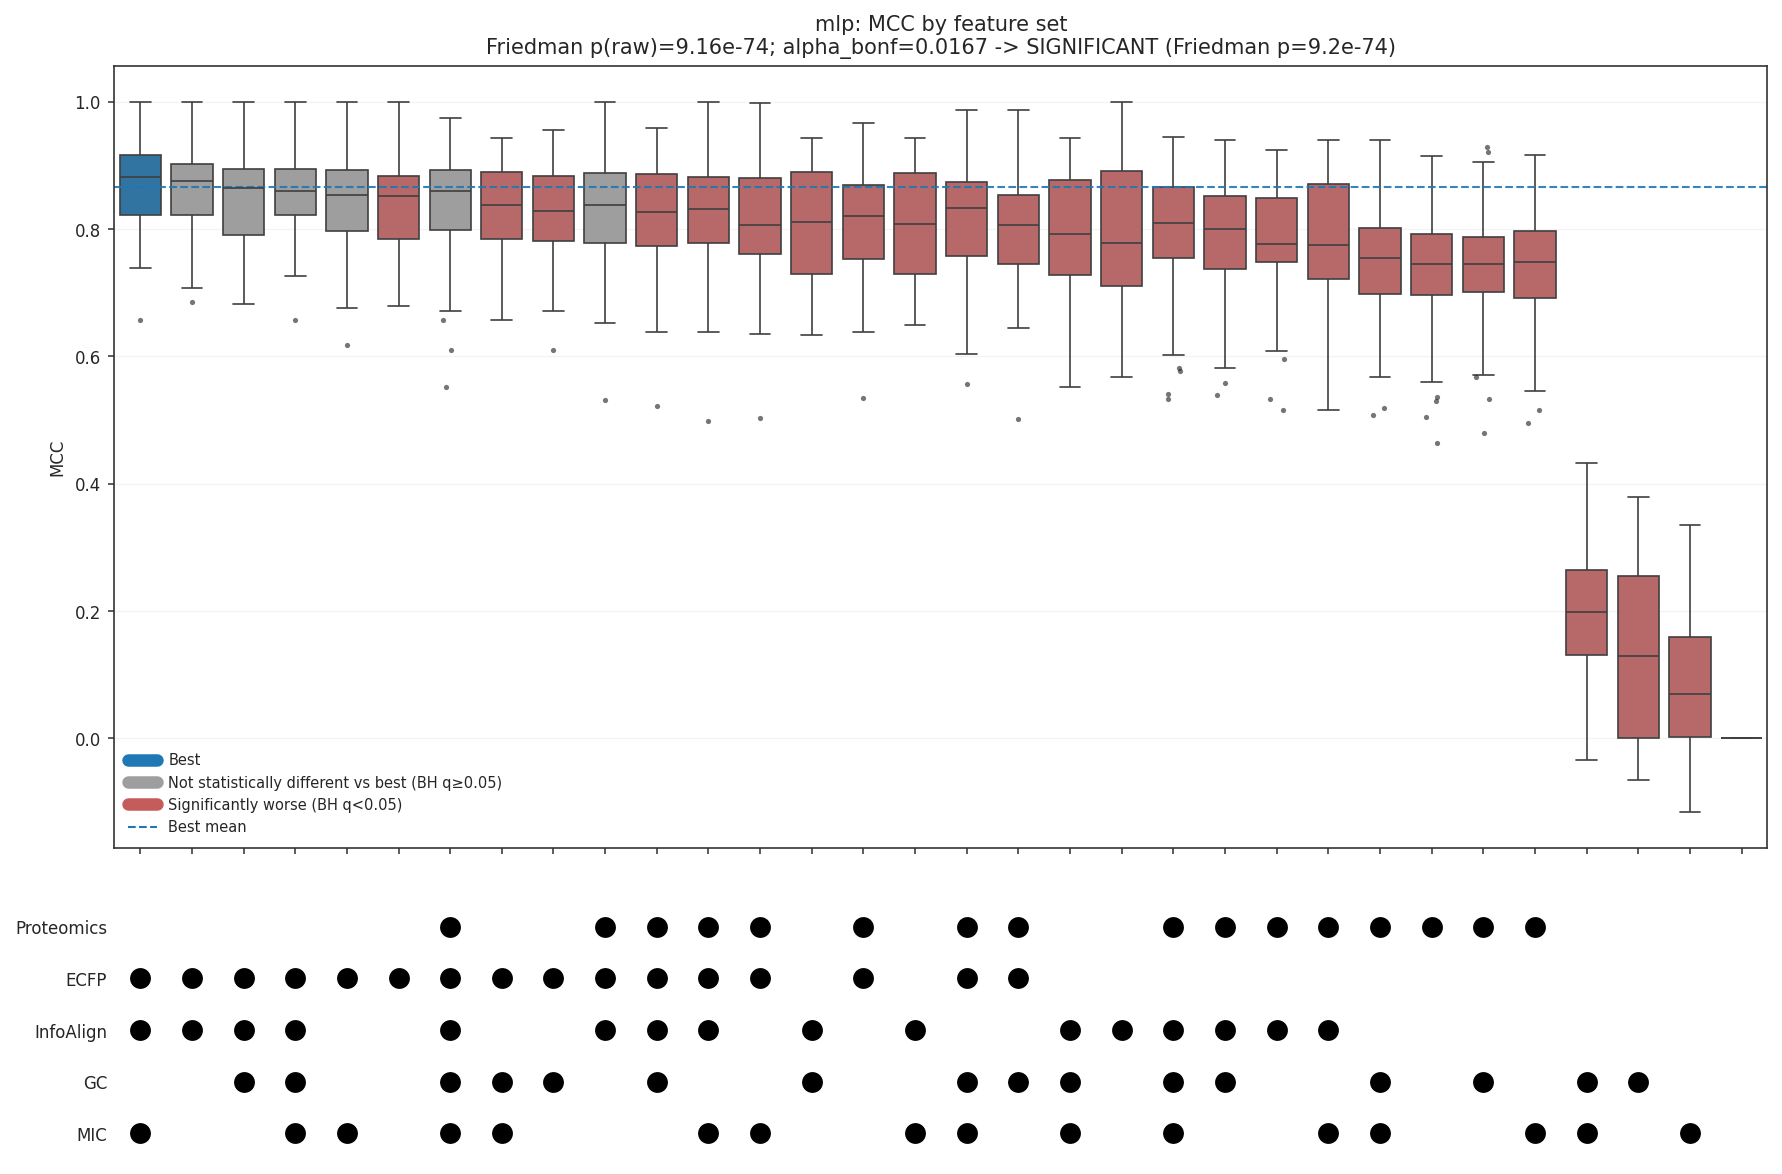

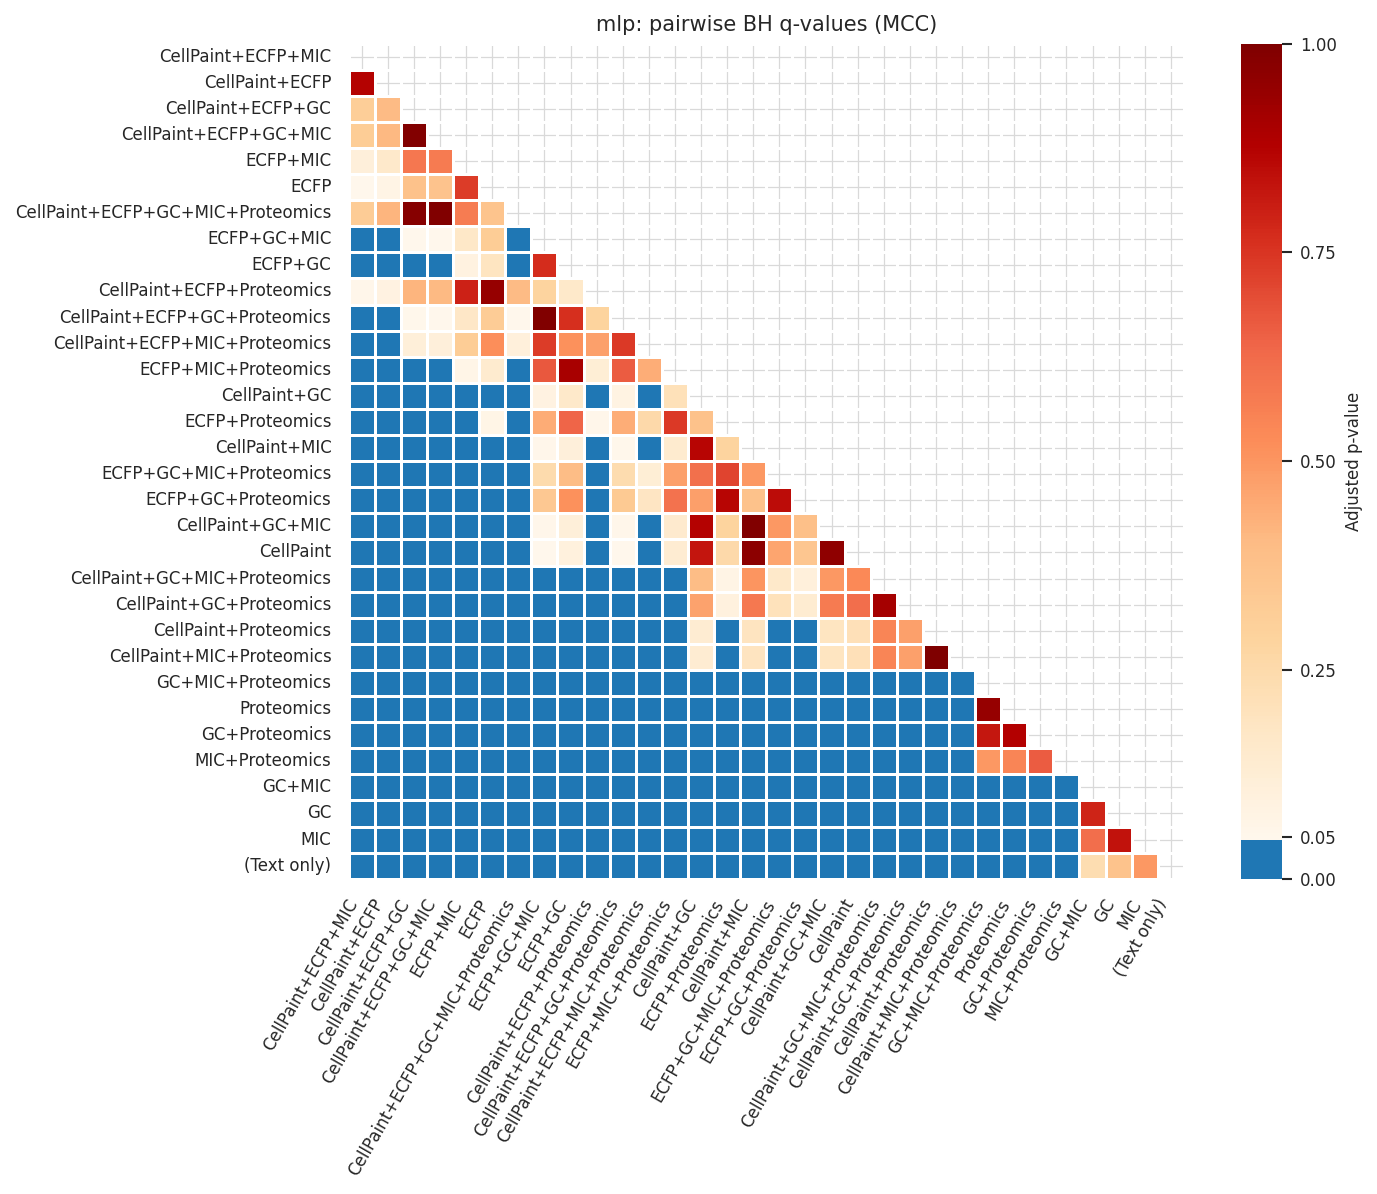

/tmp/ipykernel_6852/3597690819.py:142: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


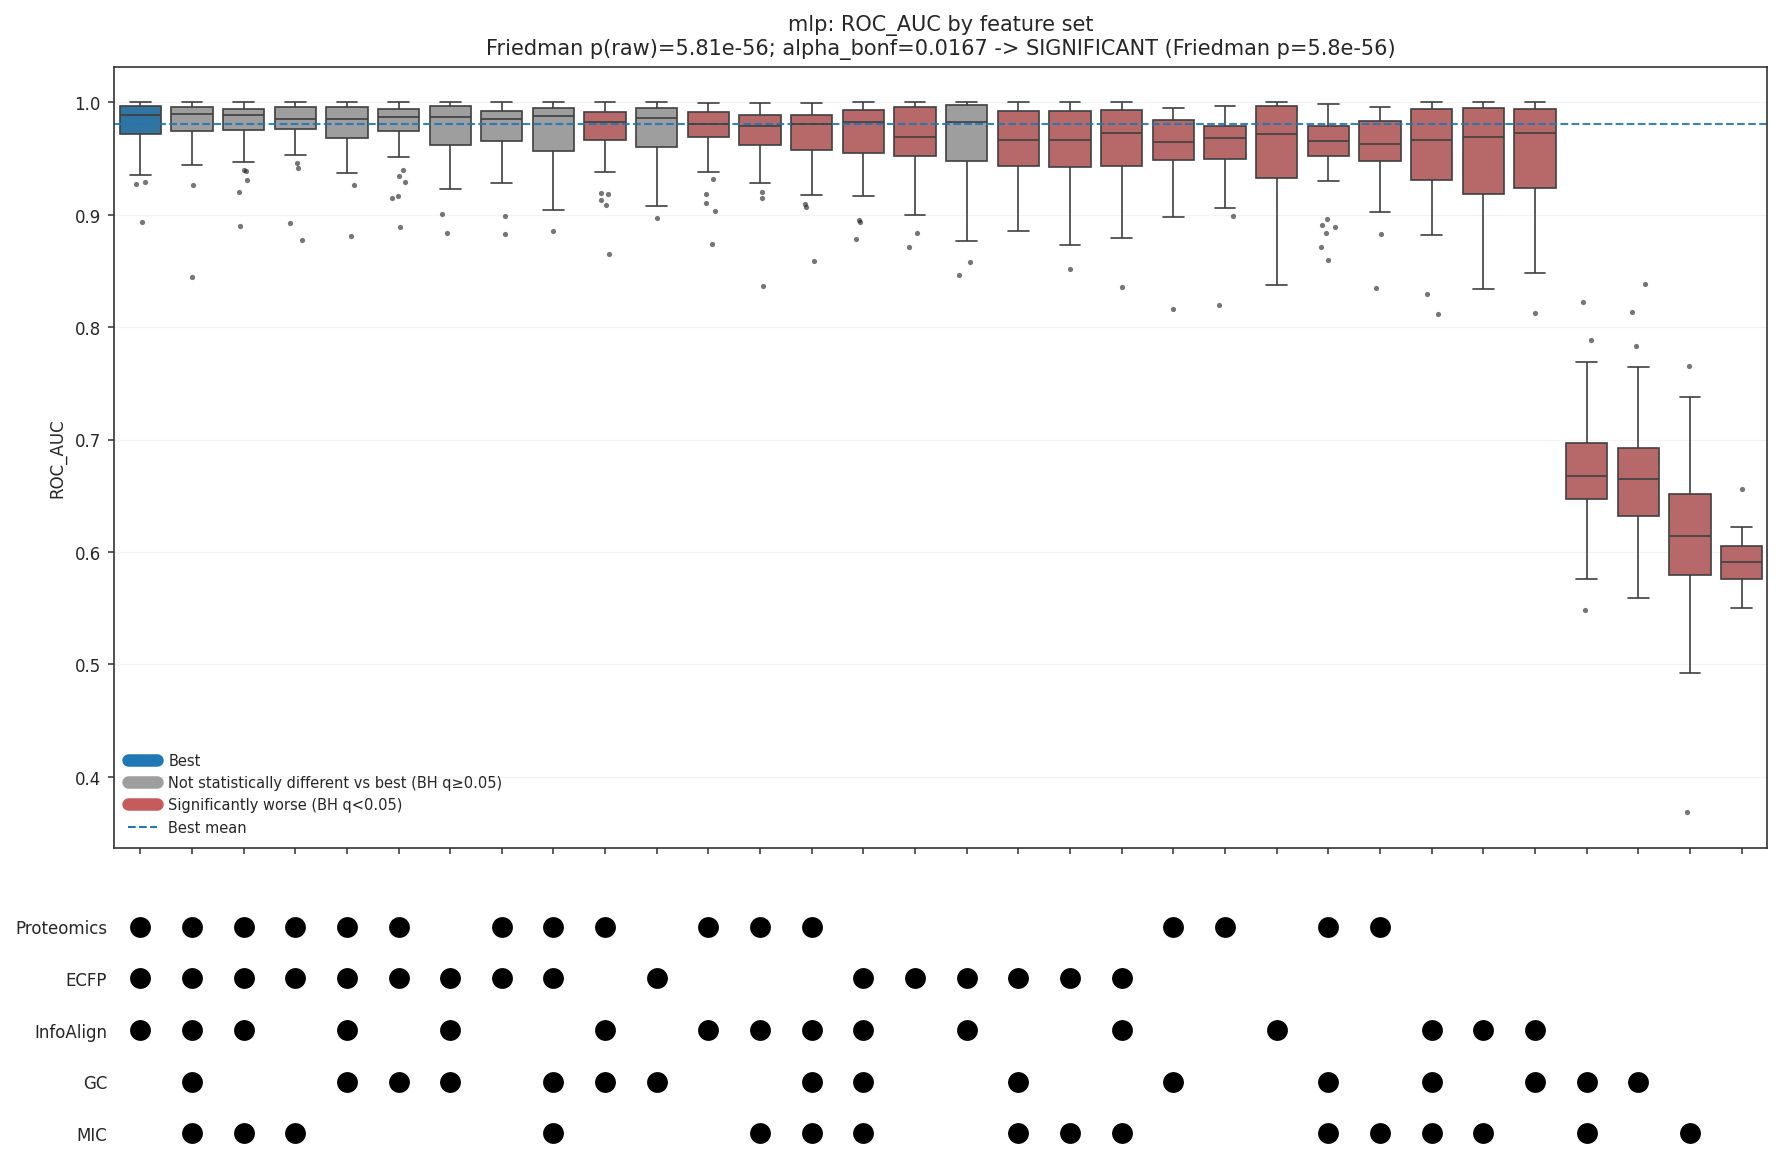

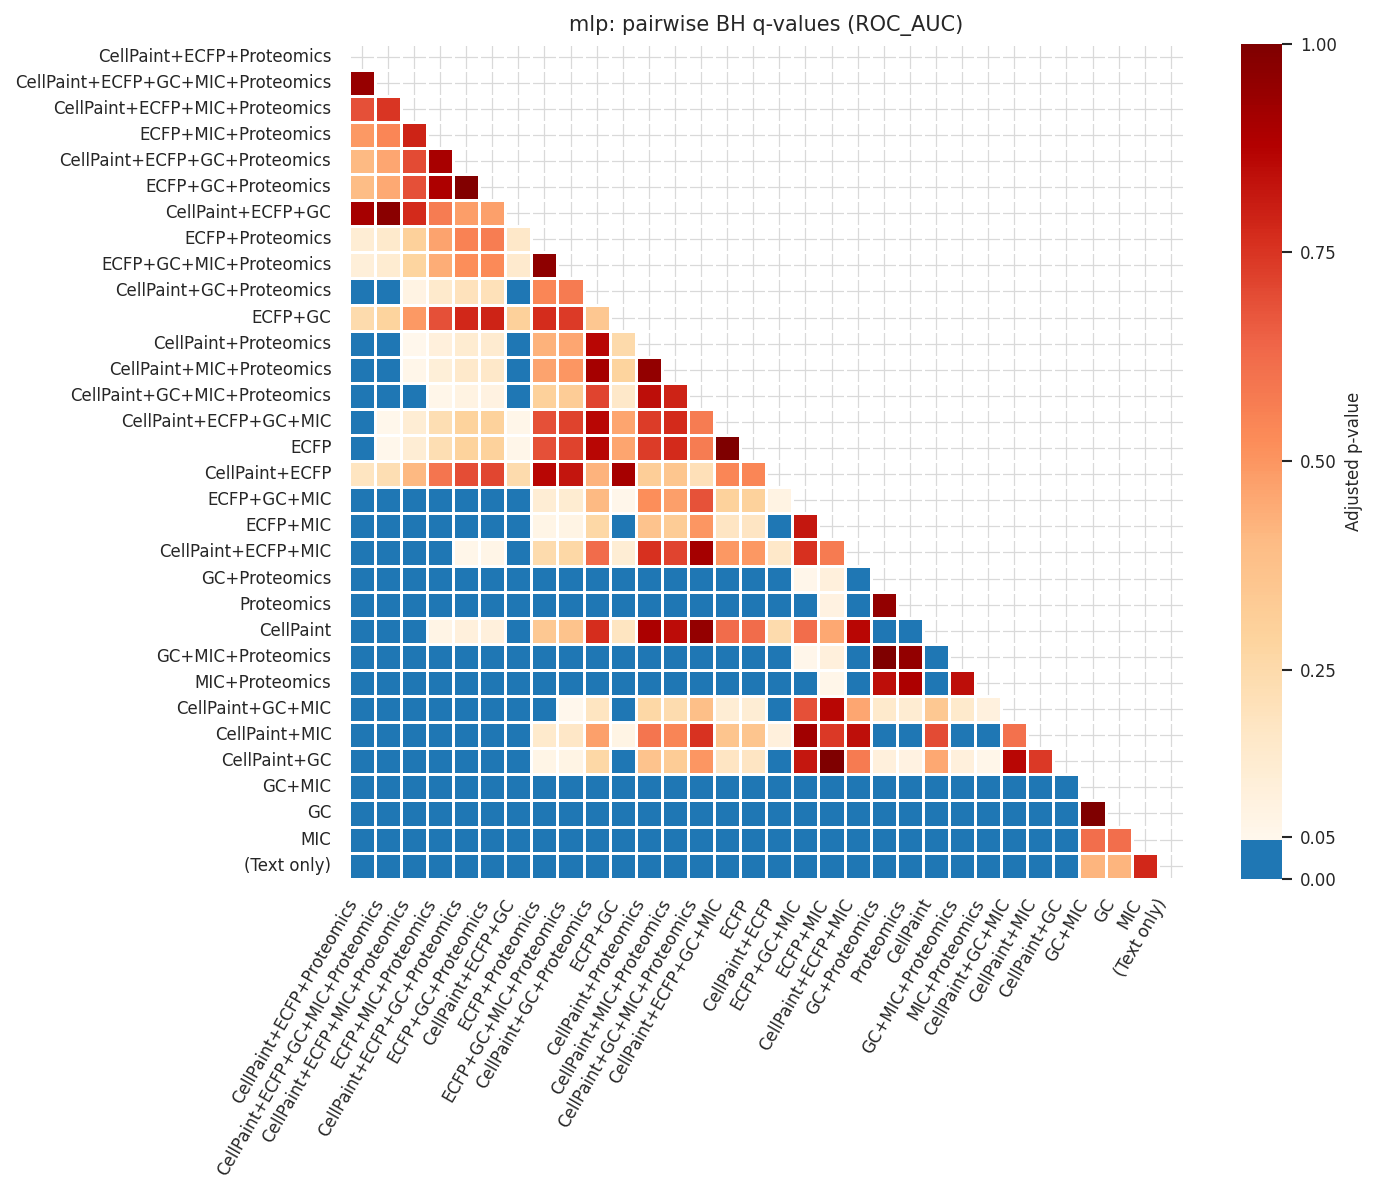

/tmp/ipykernel_6852/3597690819.py:142: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


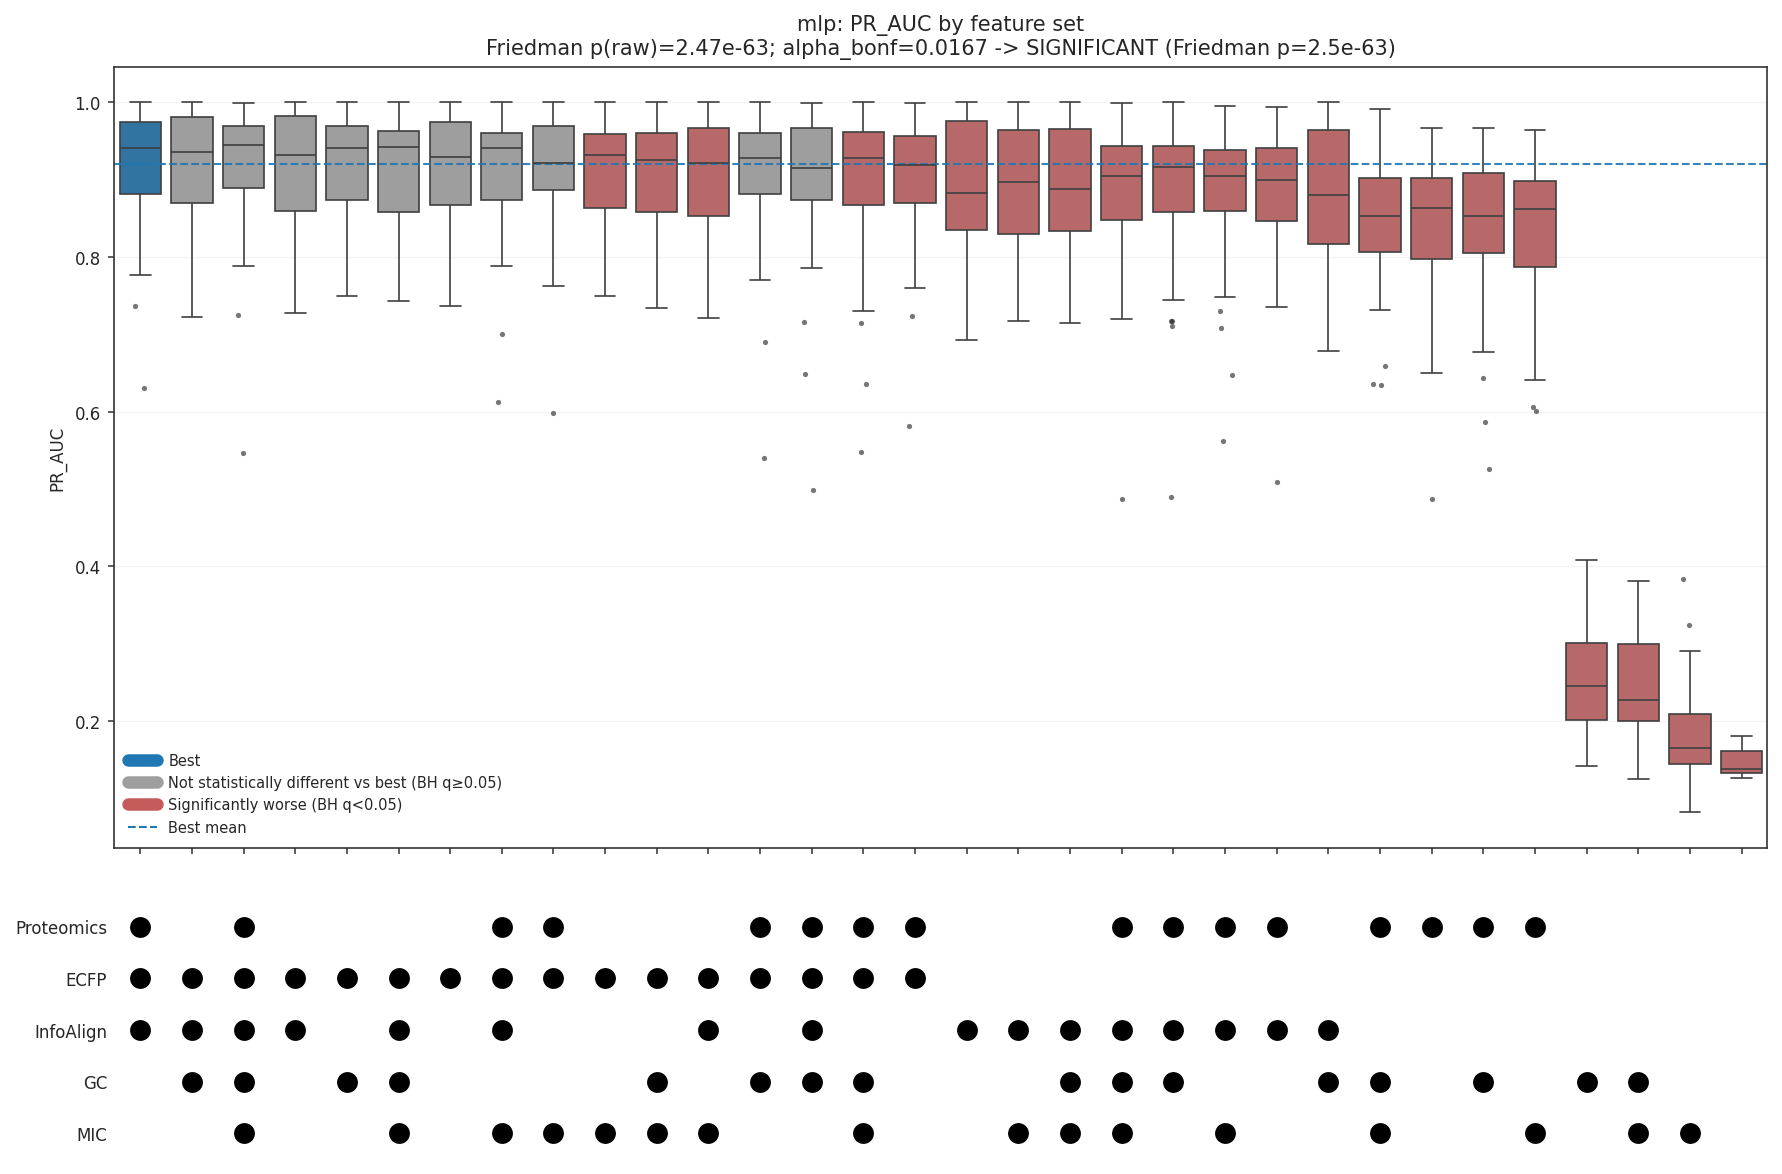

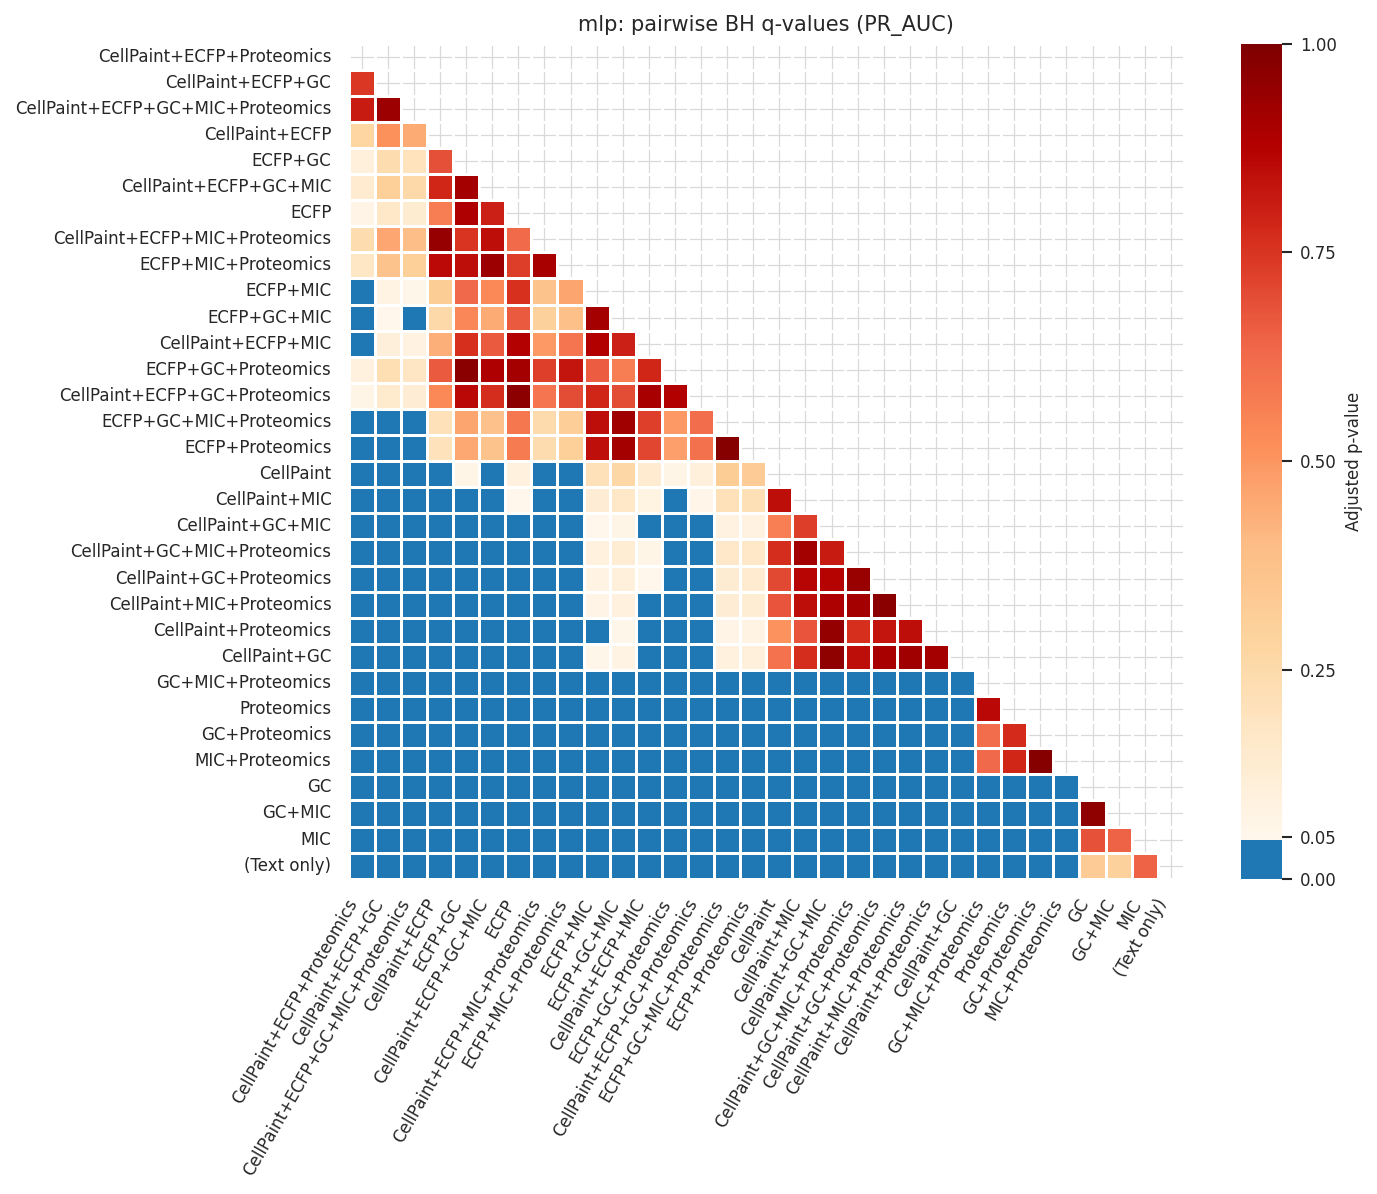


=== MODEL: rf ===
  Bonferroni omnibus alpha across metrics: 0.016667 (m=3)


/tmp/ipykernel_6852/3597690819.py:142: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


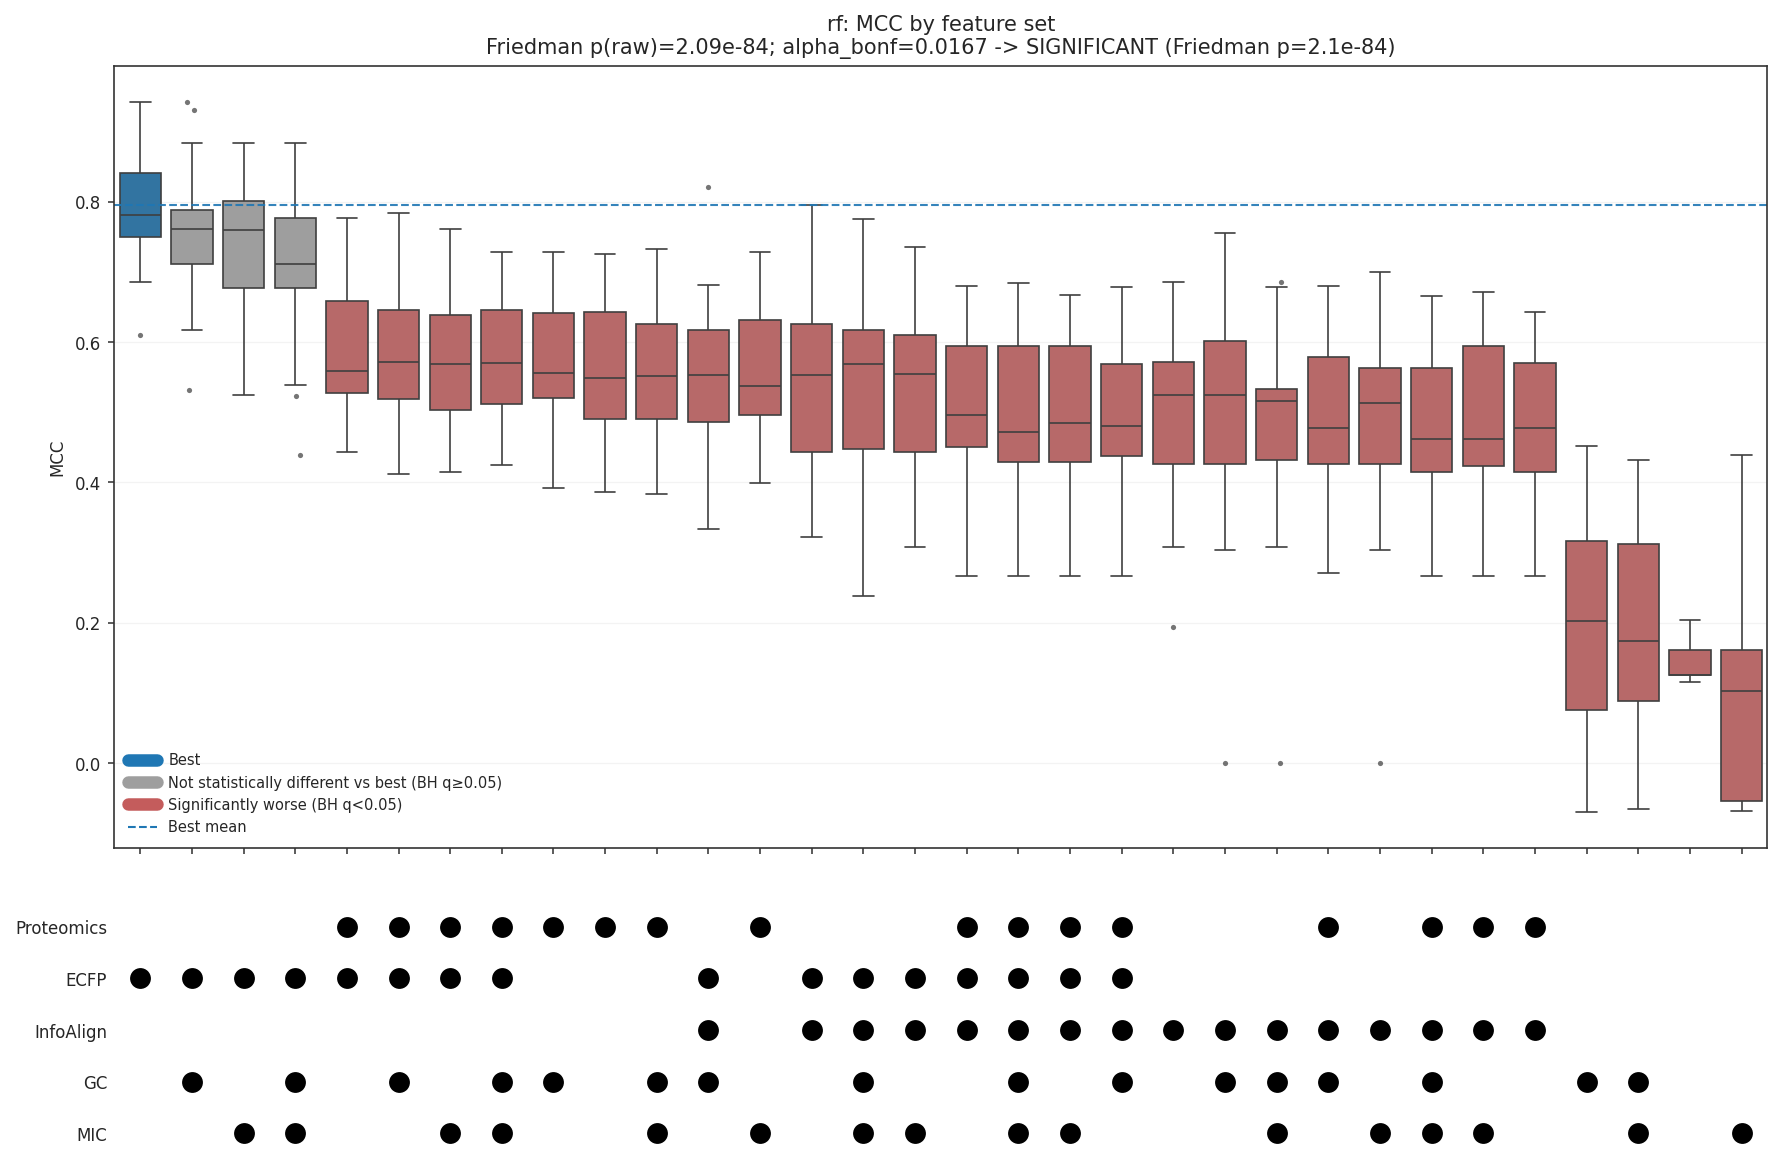

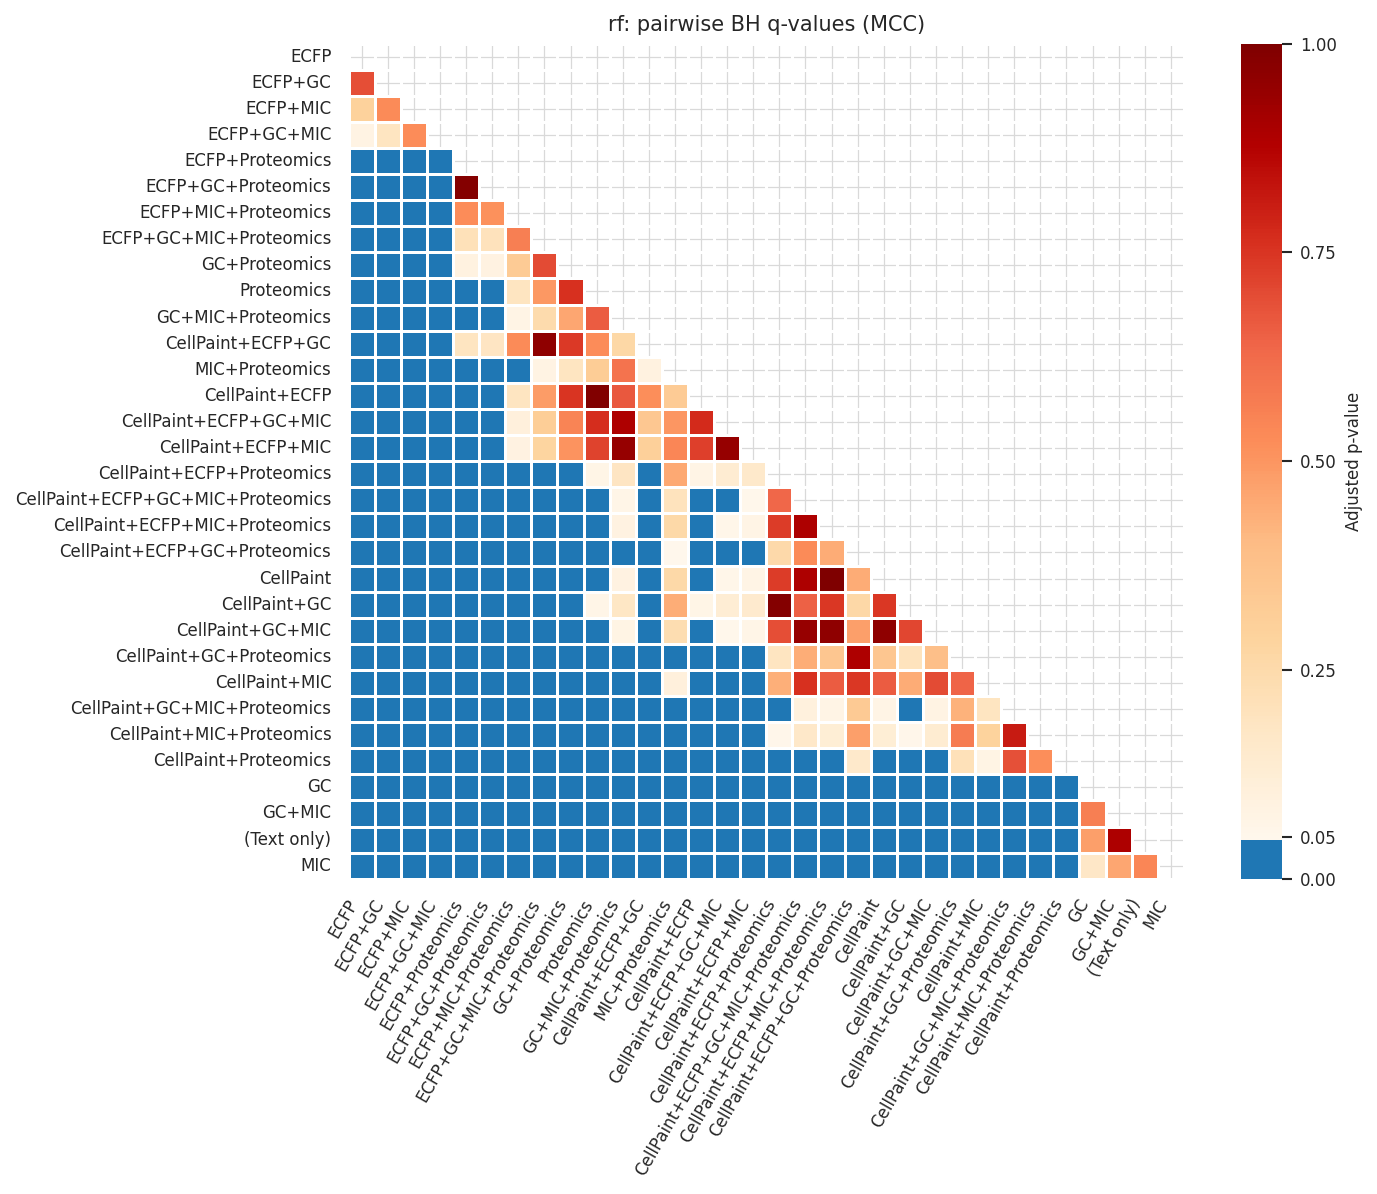

/tmp/ipykernel_6852/3597690819.py:142: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


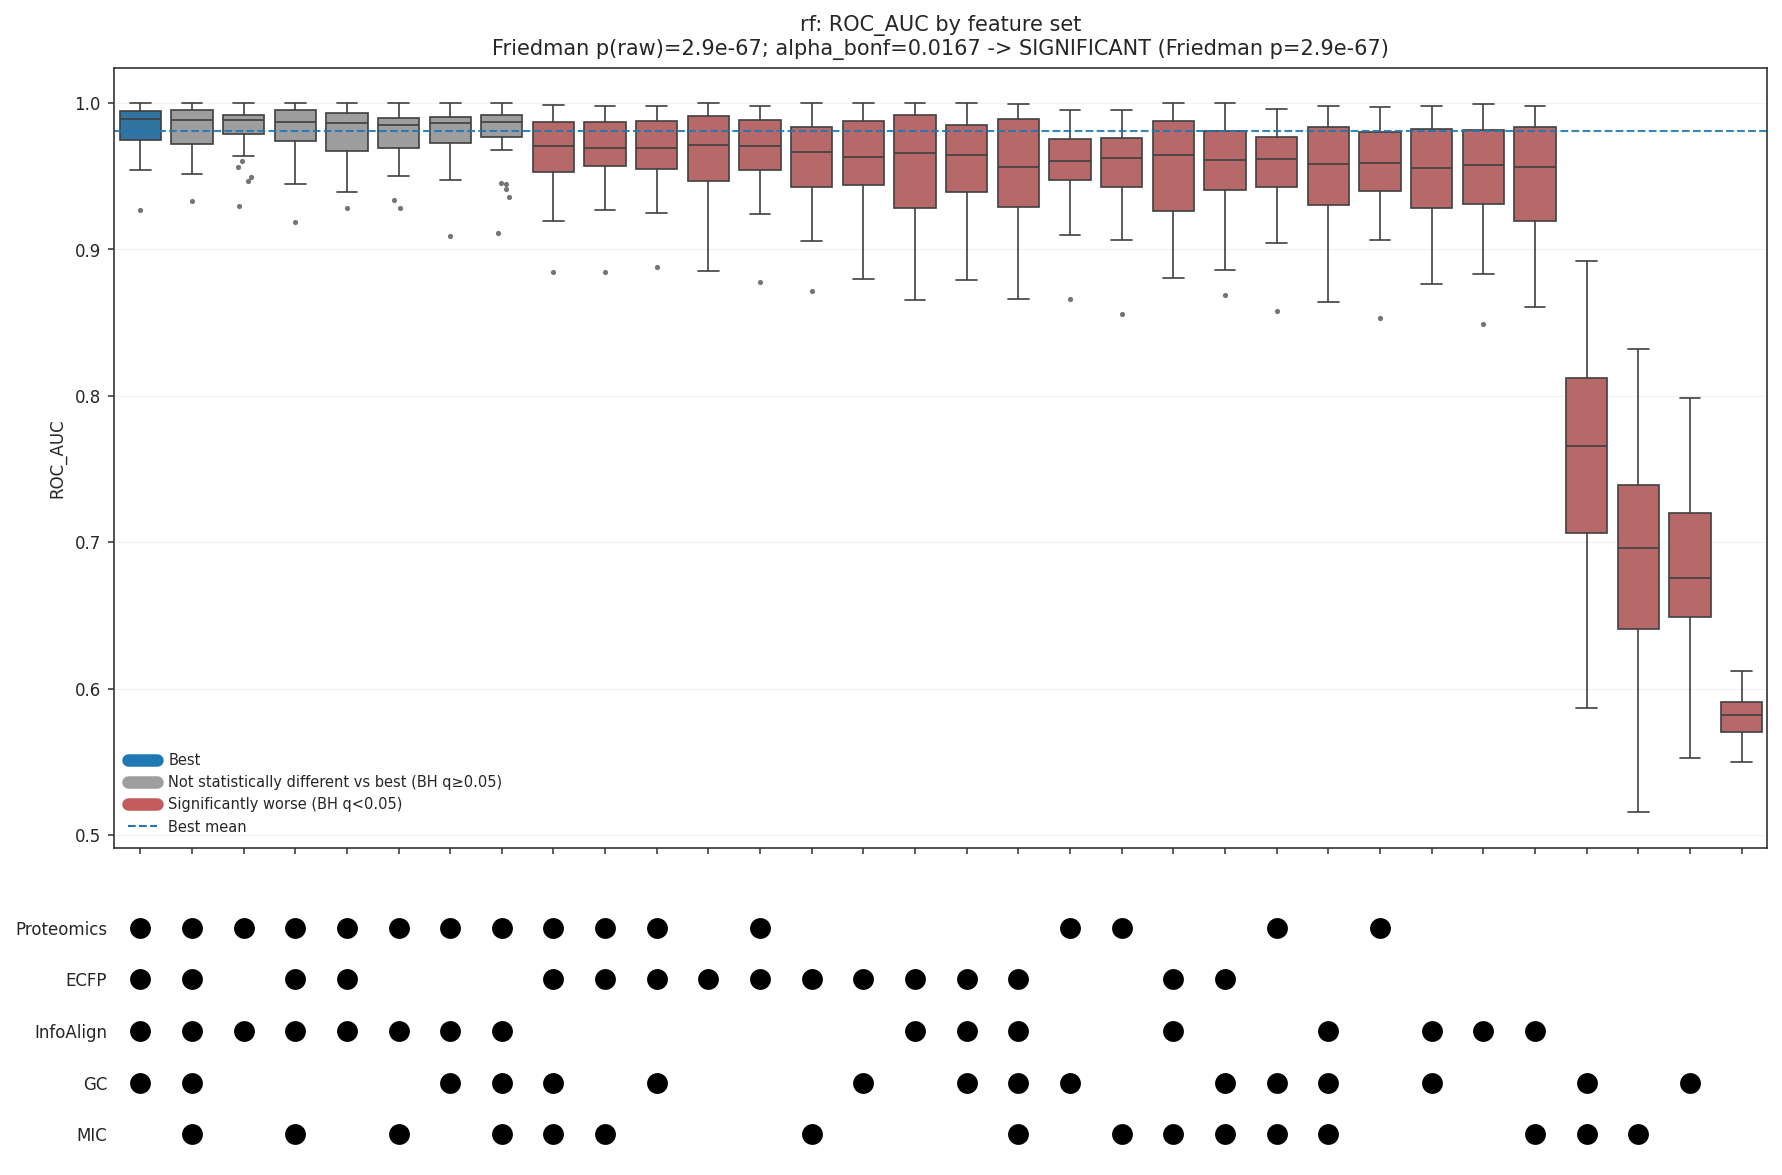

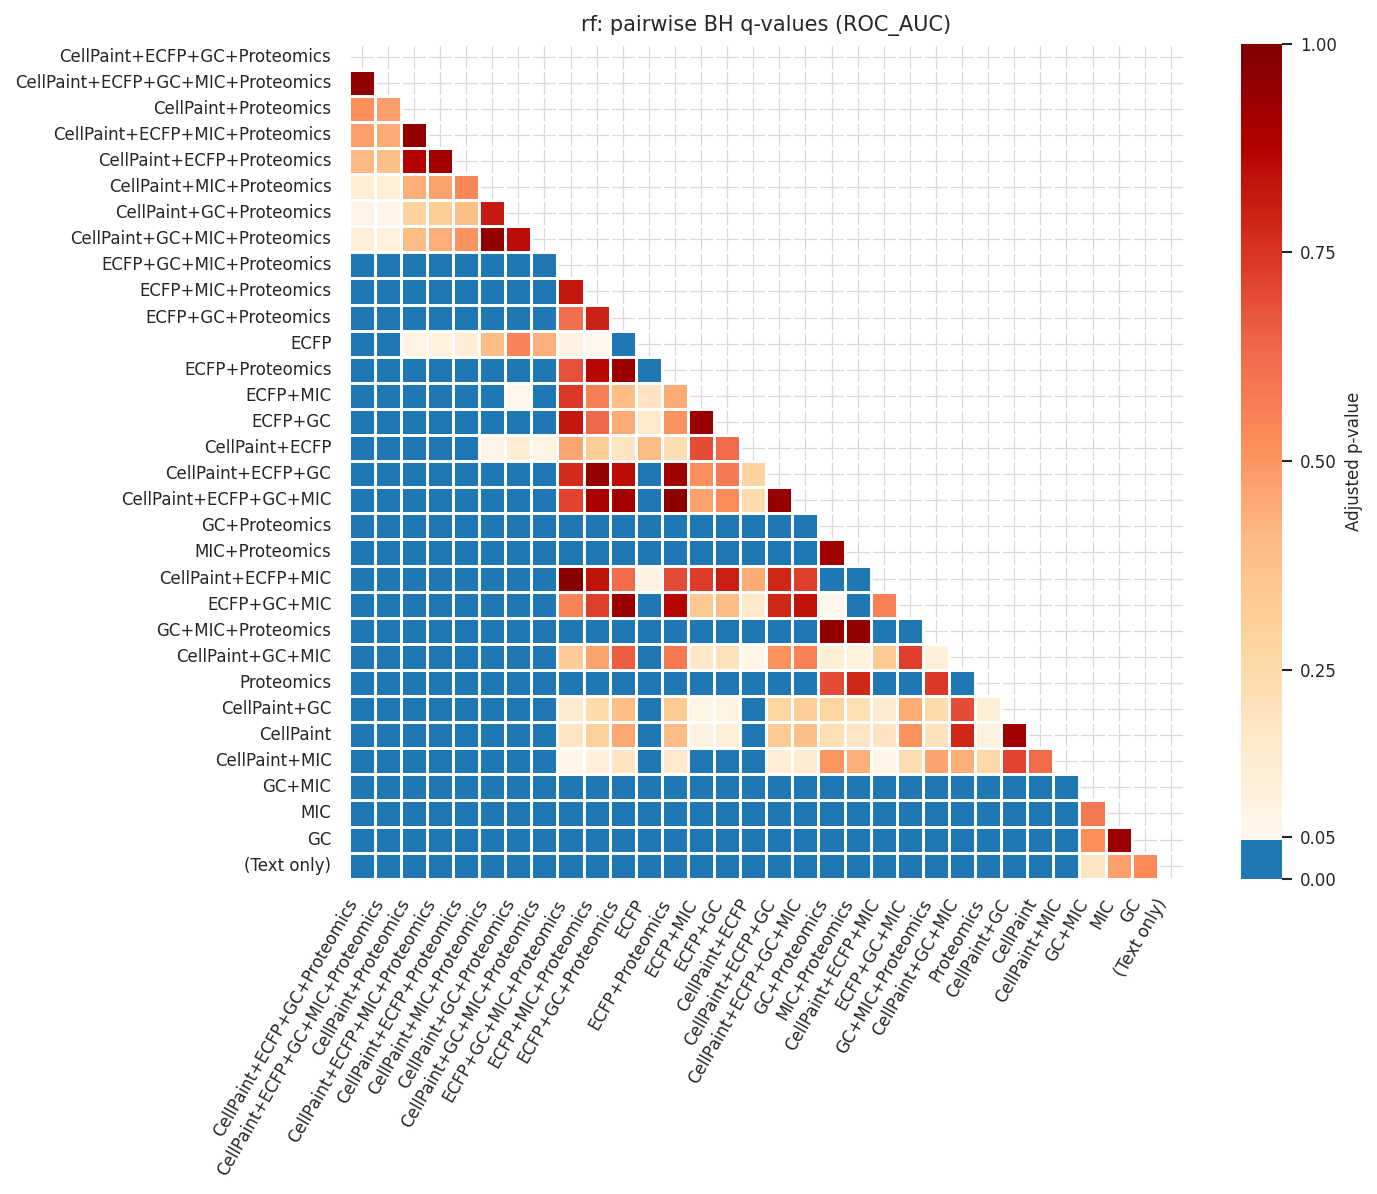

/tmp/ipykernel_6852/3597690819.py:142: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


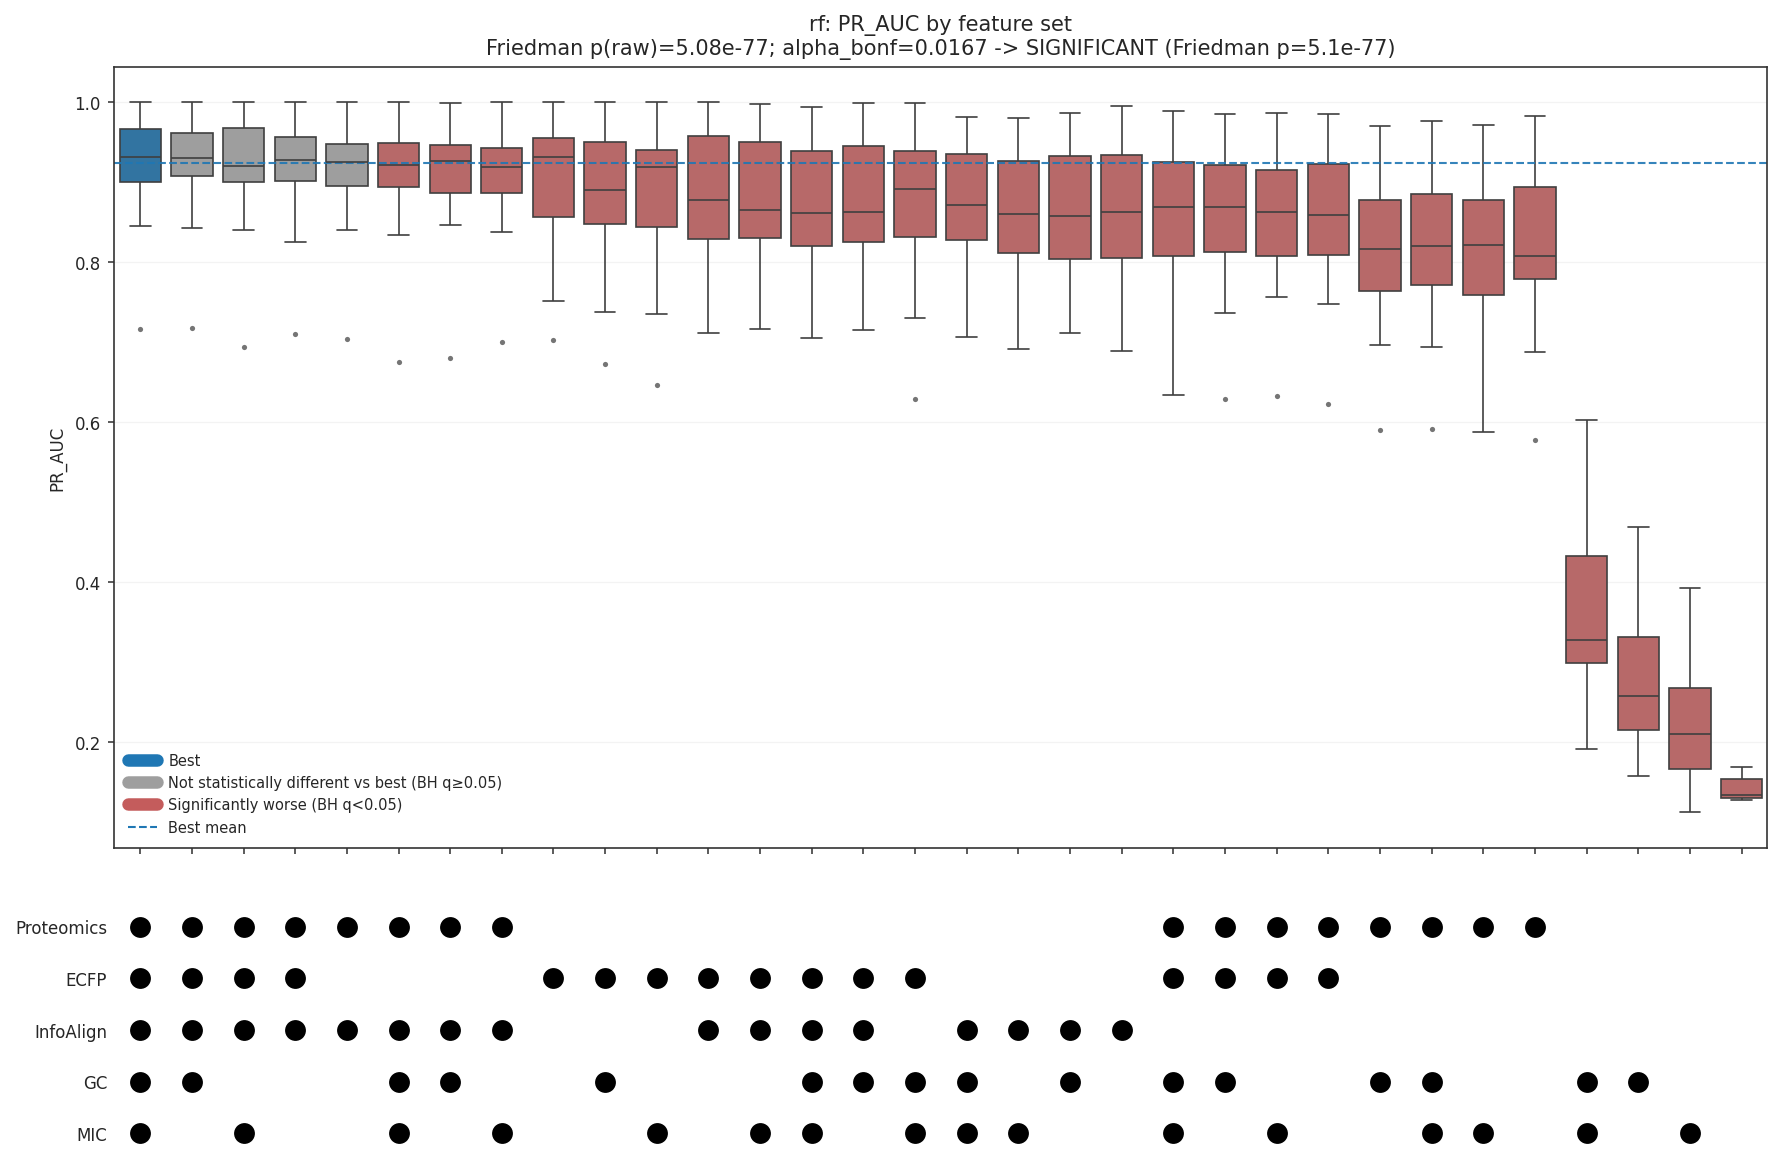

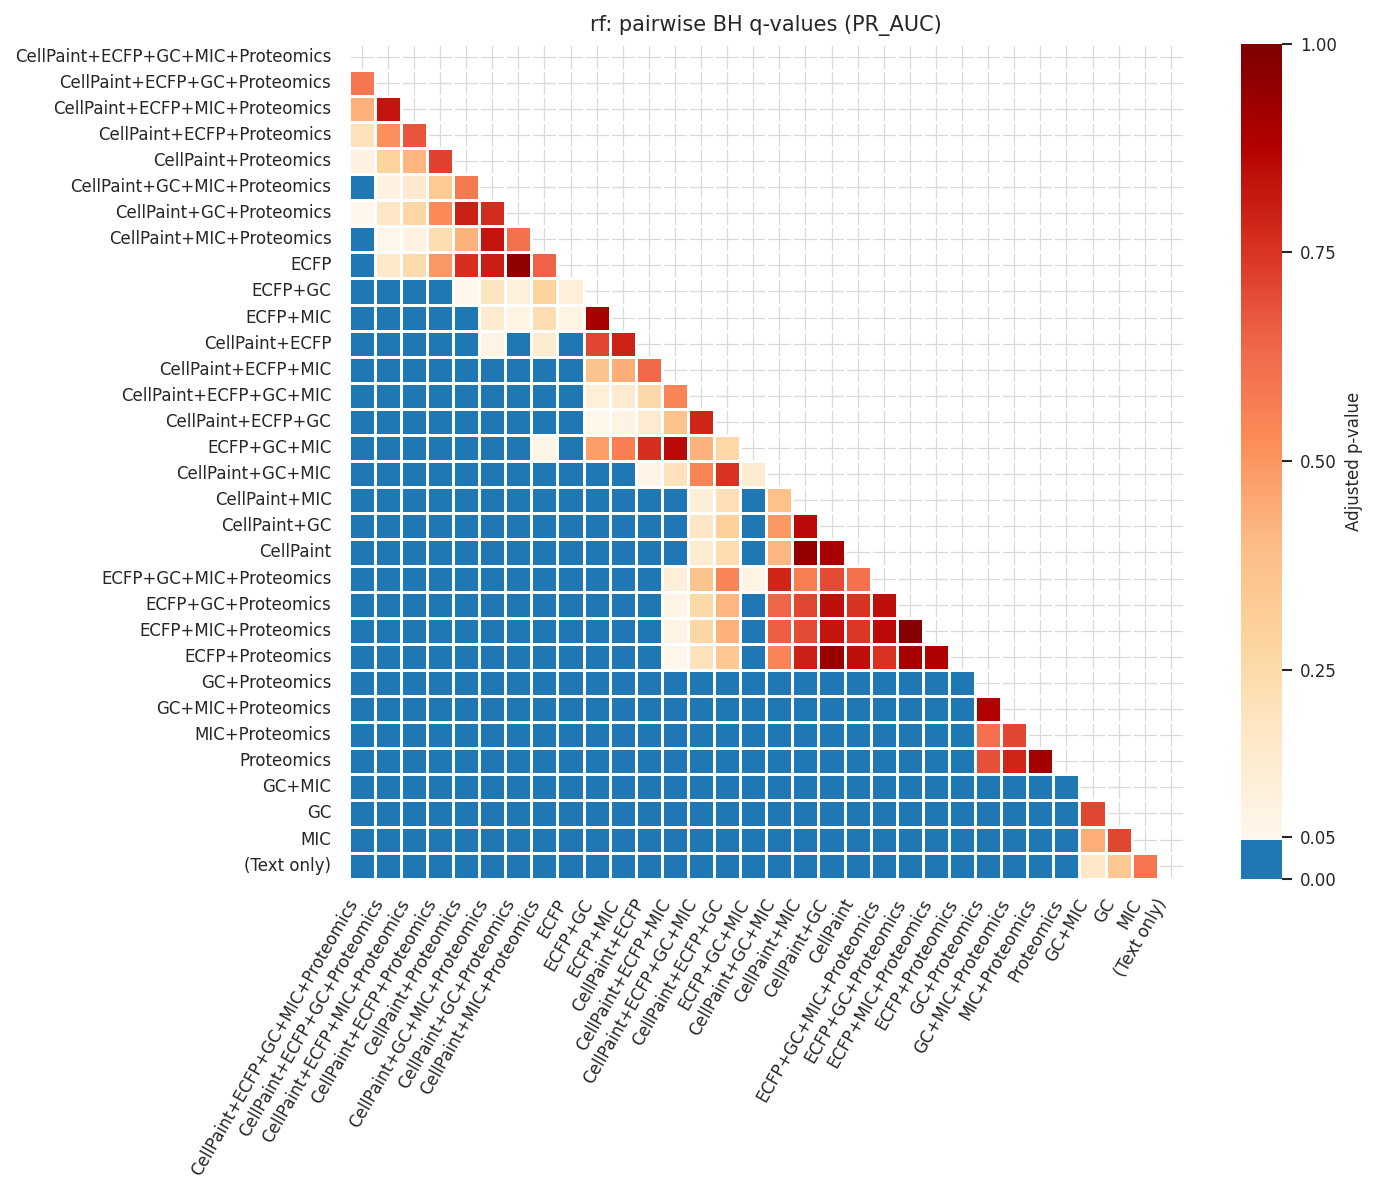


=== MODEL: xgboost ===
  Bonferroni omnibus alpha across metrics: 0.016667 (m=3)


/tmp/ipykernel_6852/3597690819.py:142: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


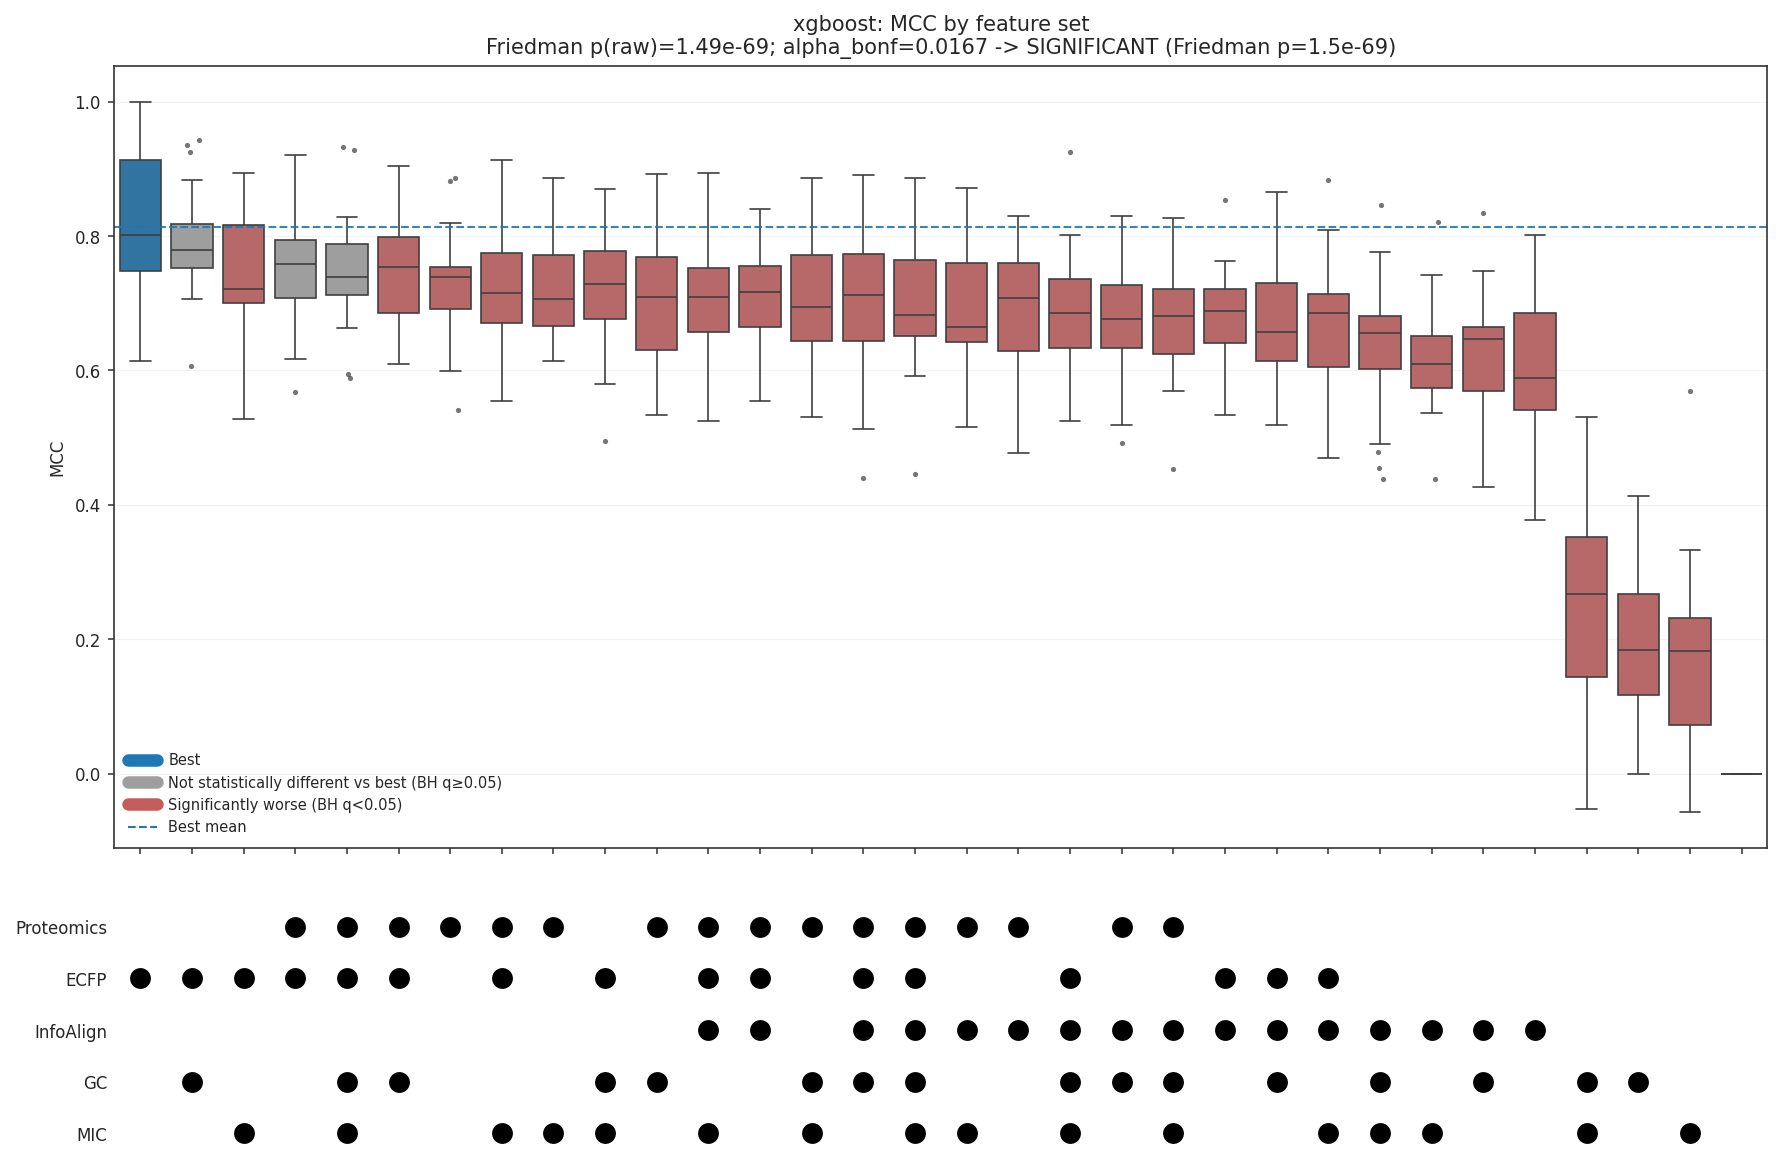

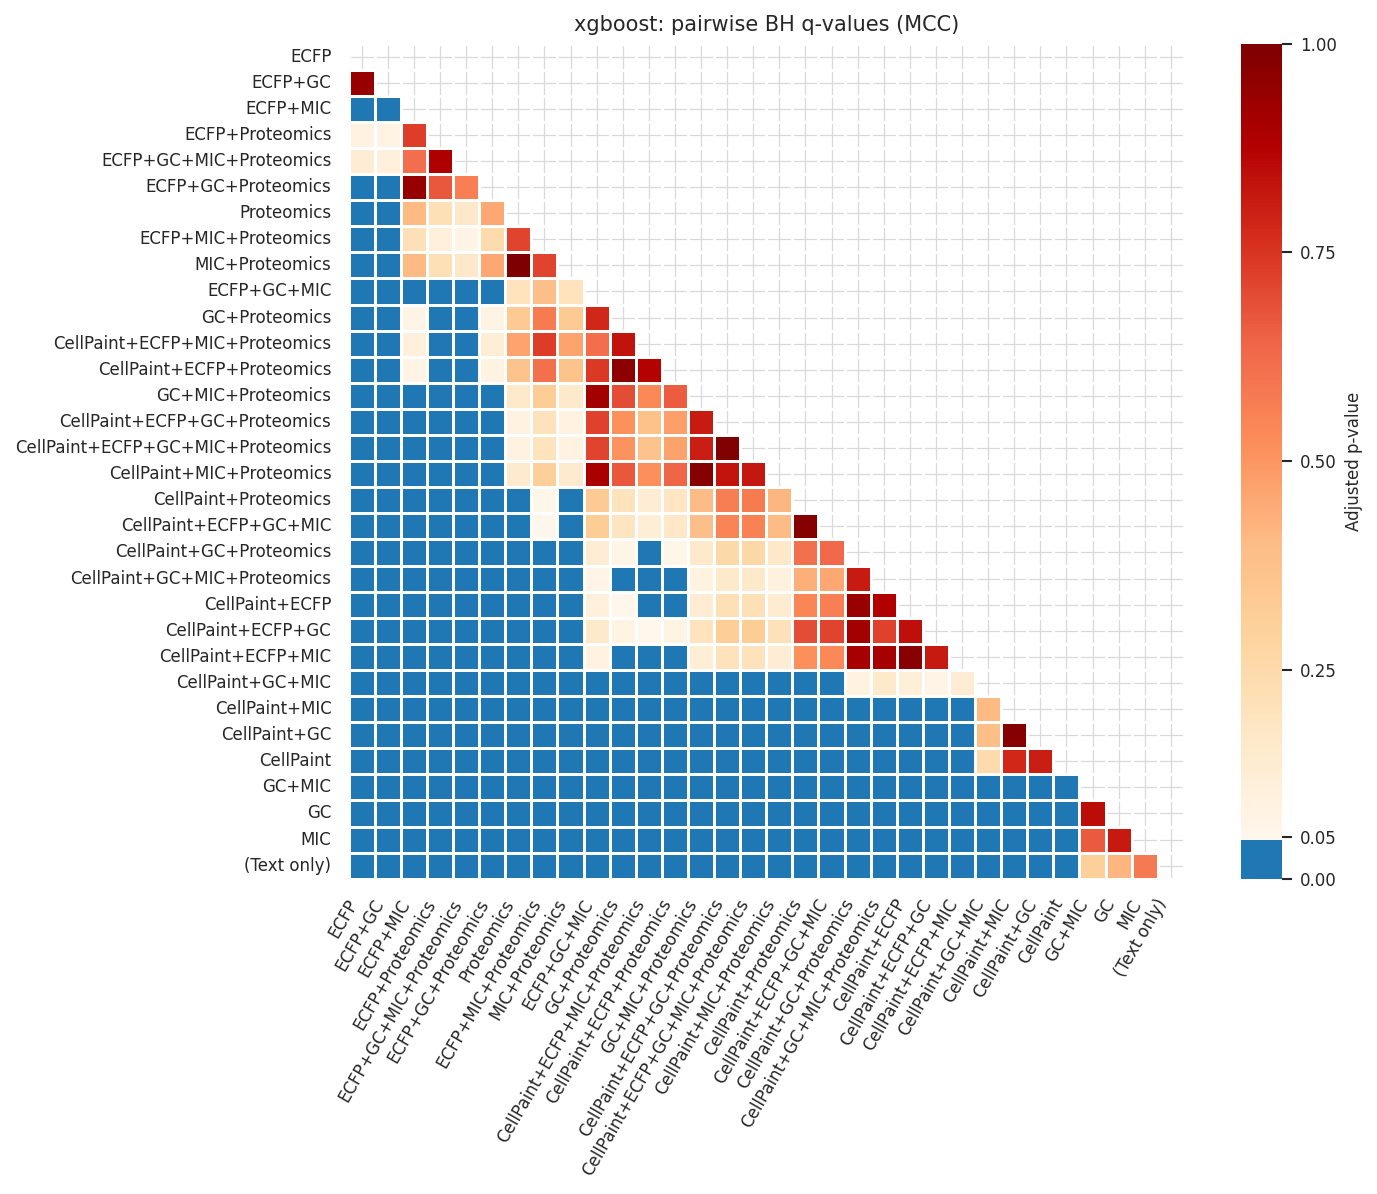

/tmp/ipykernel_6852/3597690819.py:142: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


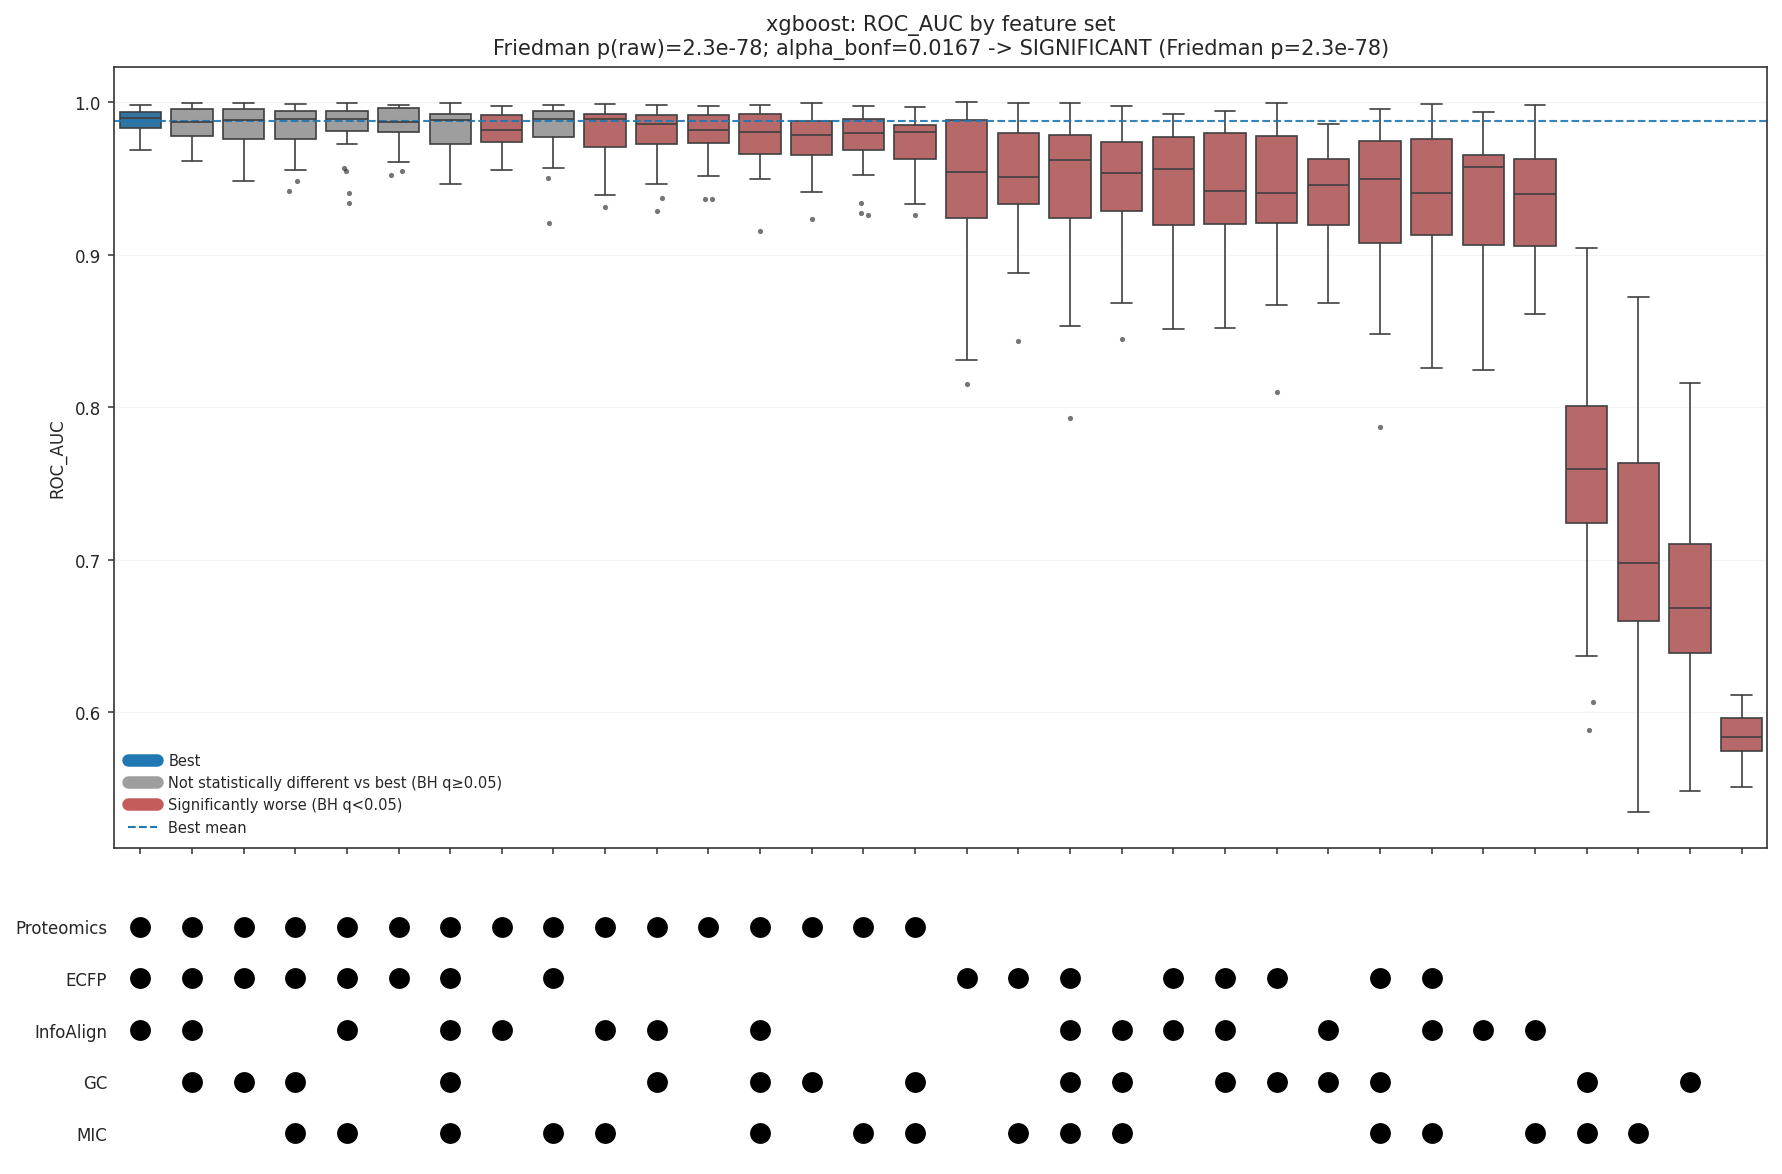

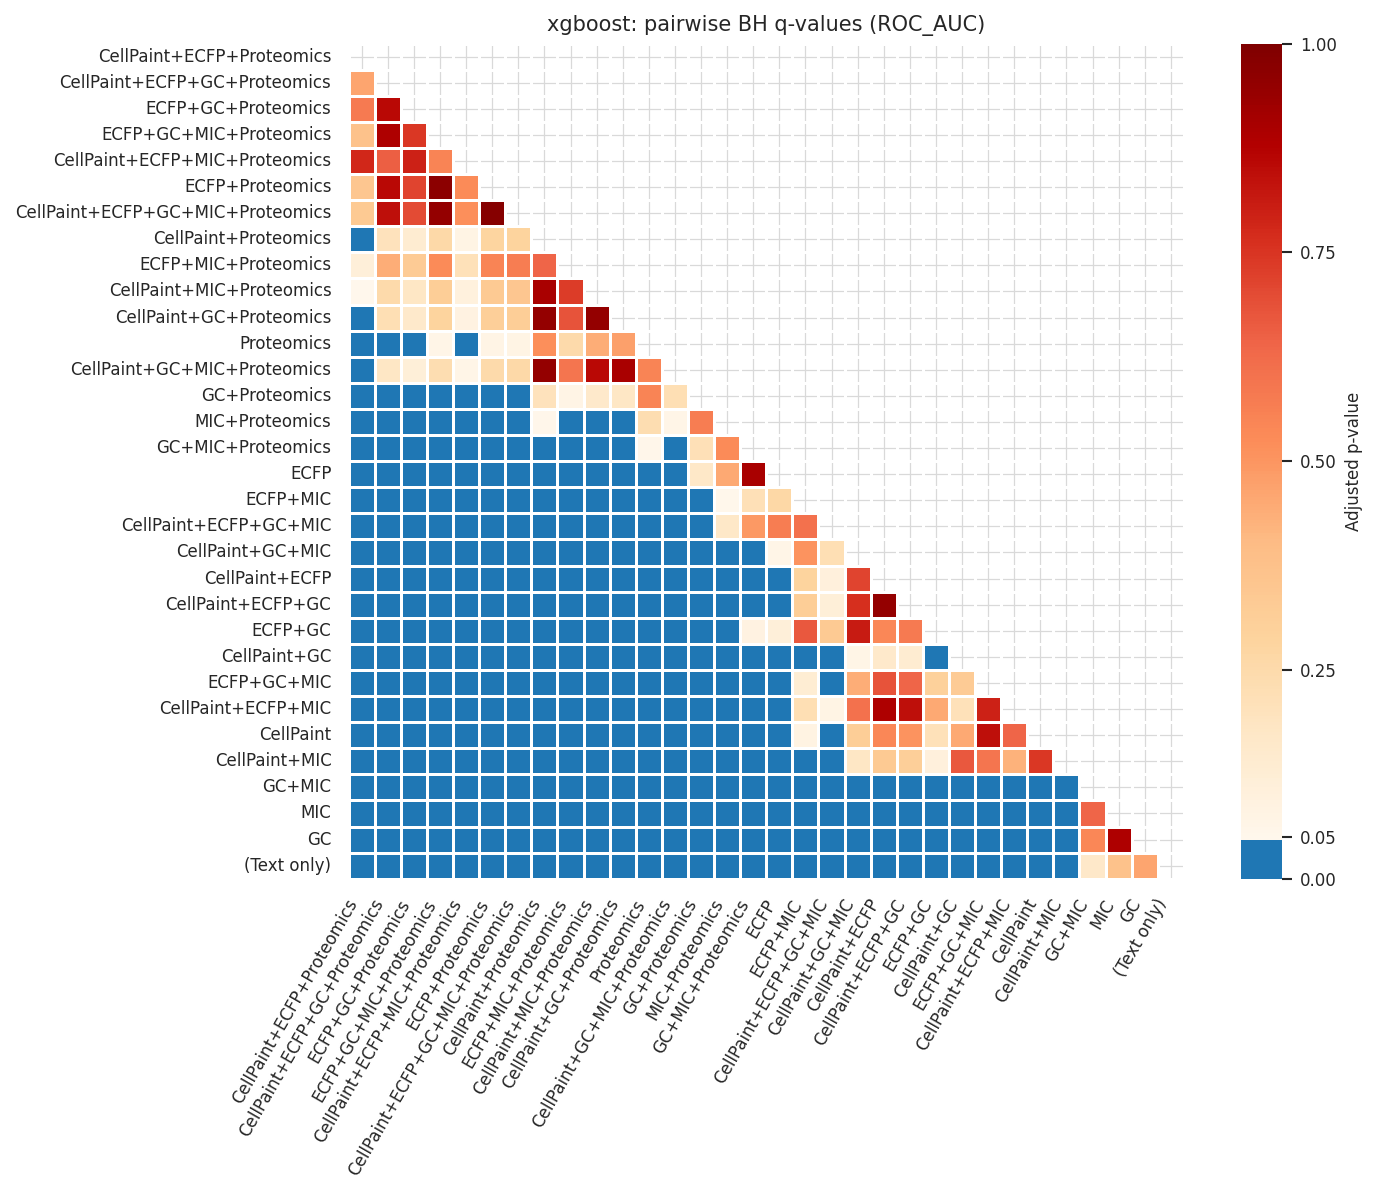

/tmp/ipykernel_6852/3597690819.py:142: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


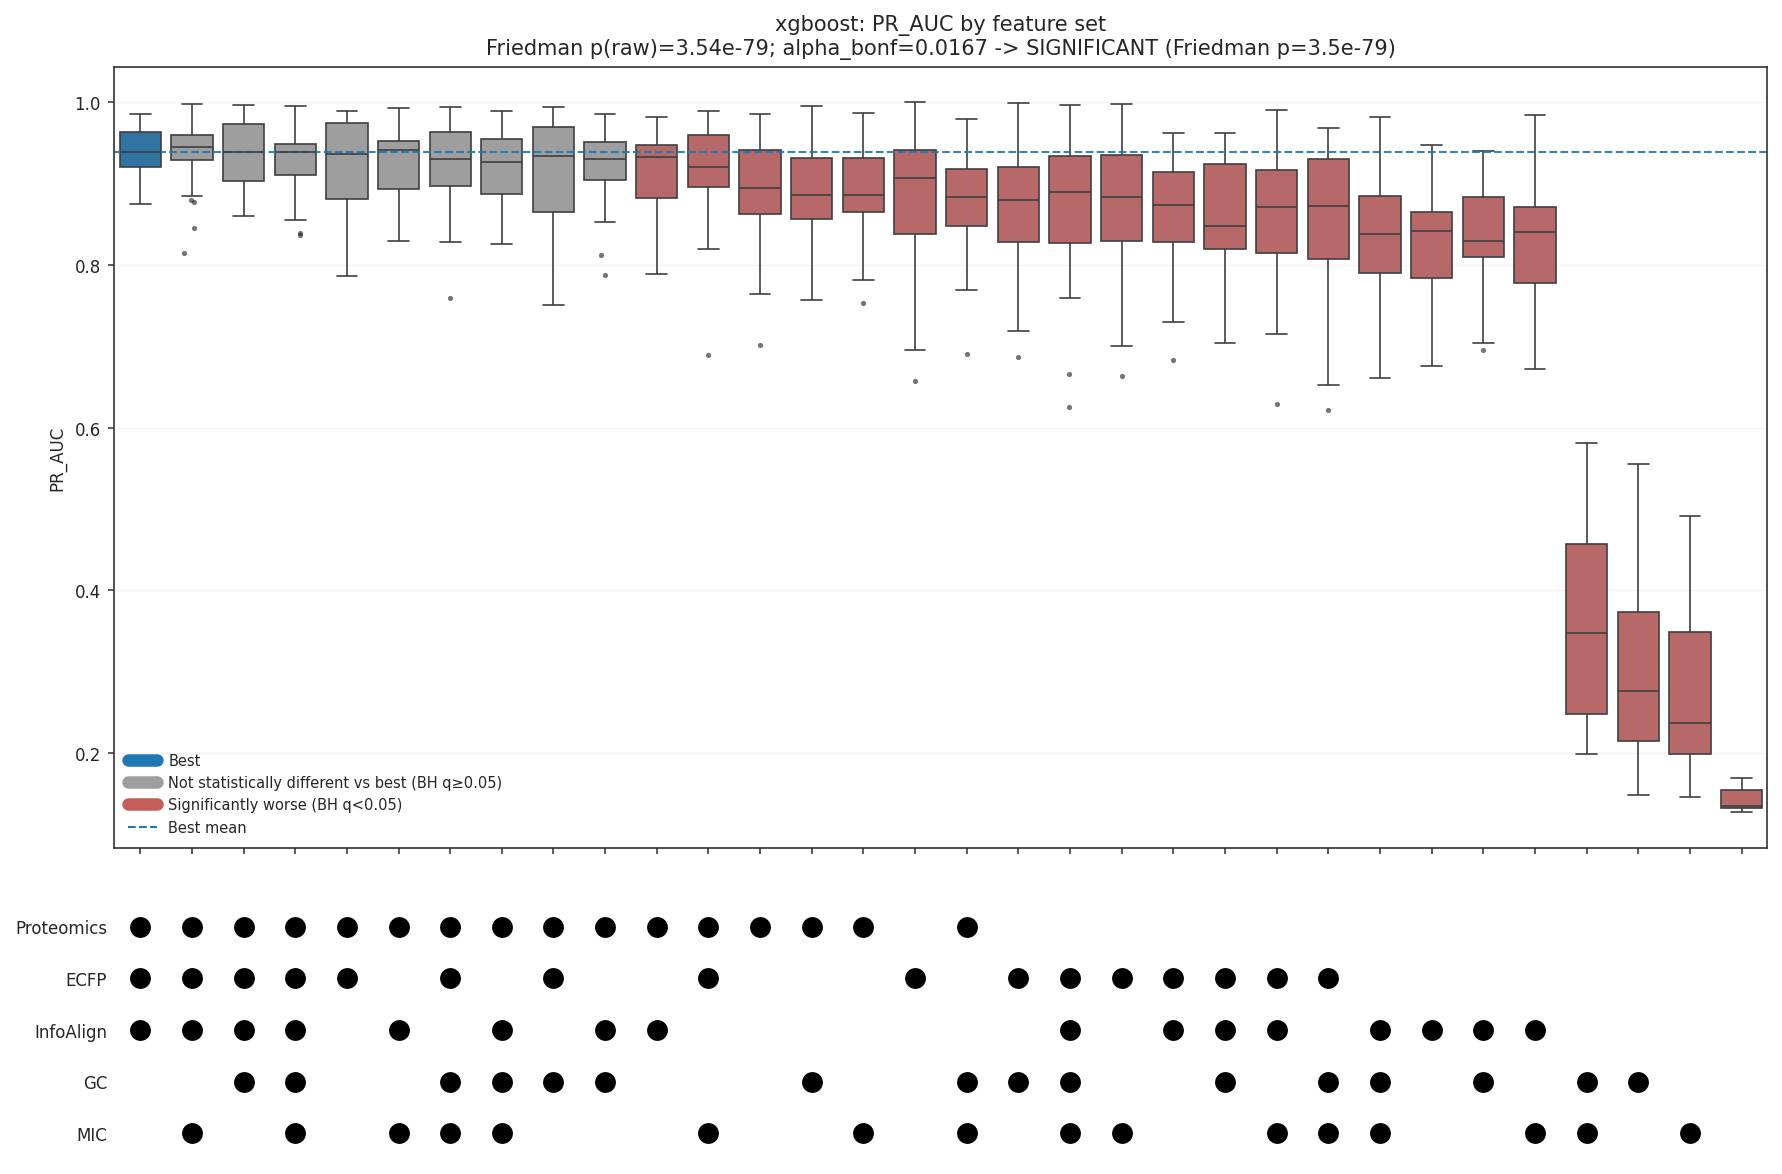

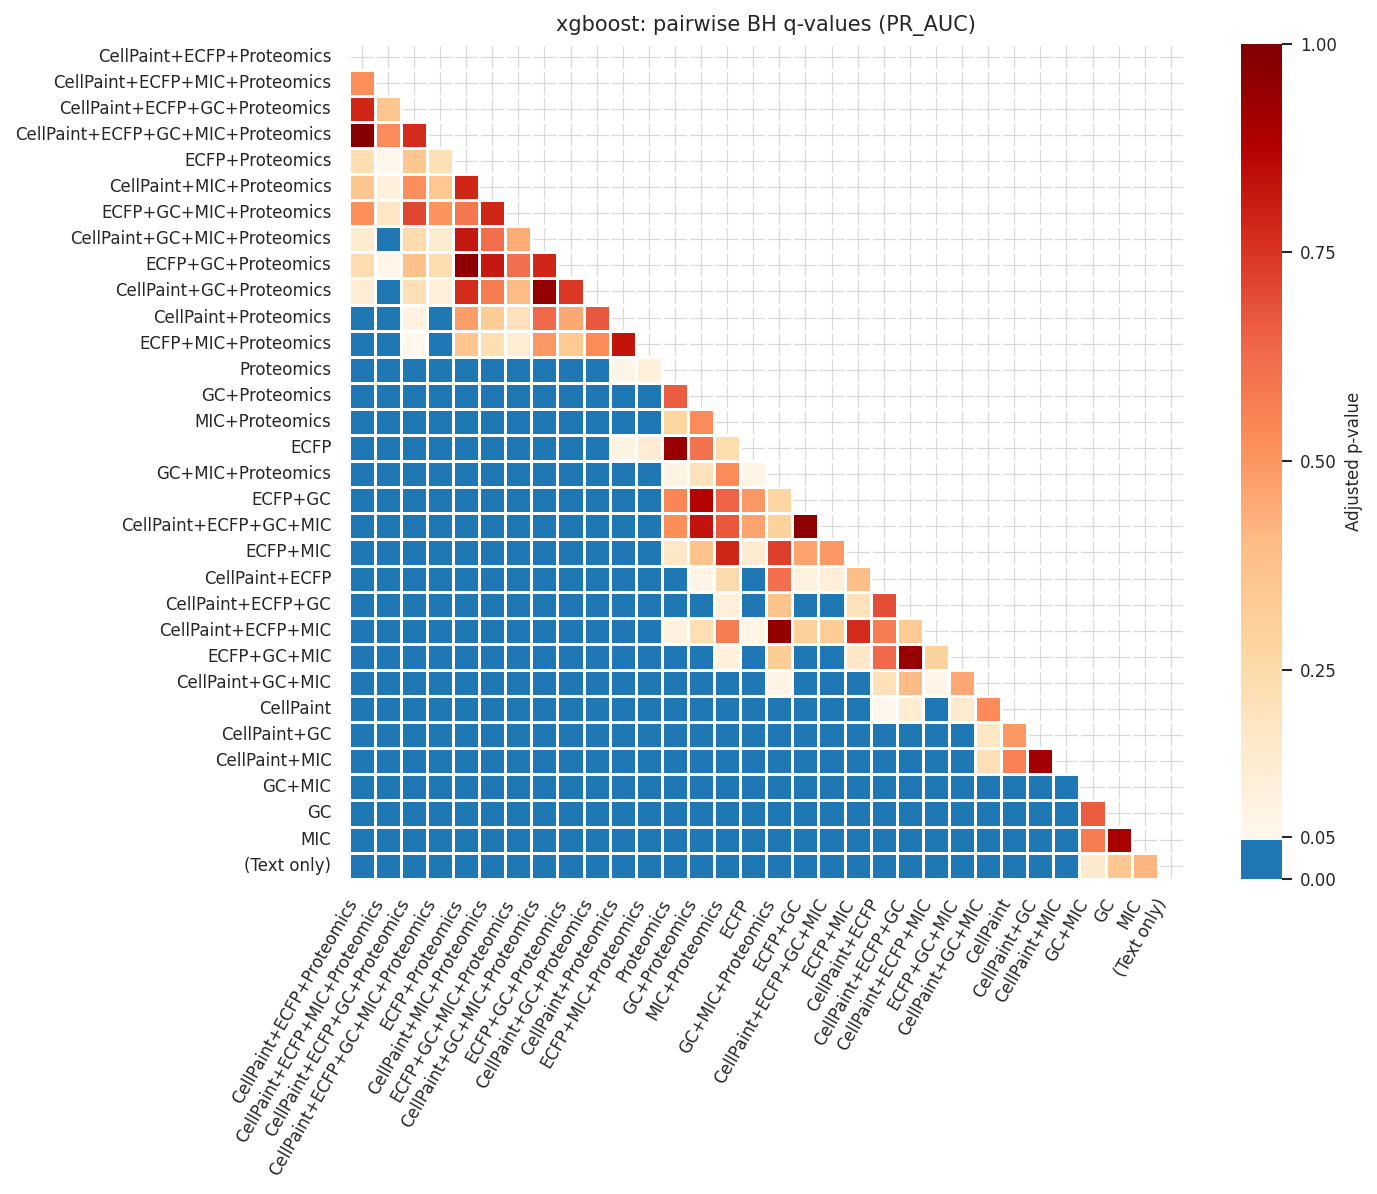

,model,metric,best,mean,std,n_cycles,friedman_p_raw,alpha_bonferroni,friedman_sig_after_alpha_bonf,posthoc,posthoc_performed,mcs_size
0,pytorch_mlp,mcc,CellPaint+ECFP+GC+MIC+Proteomics,0.879070,0.066248,25,1.006664e-68,0.016667,True,Conover–Friedman (BH),True,9
9,mlp,mcc,CellPaint+ECFP+MIC,0.866379,0.070532,25,9.161333e-74,0.016667,True,Conover–Friedman (BH),True,7
6,lightgbm,mcc,ECFP+GC,0.834970,0.101621,25,2.621287e-83,0.016667,True,Conover–Friedman (BH),True,6
3,tabm,mcc,CellPaint+ECFP+GC+Proteomics,0.829669,0.081257,25,9.408350e-61,0.016667,True,Conover–Friedman (BH),True,11
15,xgboost,mcc,ECFP,0.812957,0.098705,25,1.488665e-69,0.016667,True,Conover–Friedman (BH),True,4
12,rf,mcc,ECFP,0.794790,0.077179,25,2.088189e-84,0.016667,True,Conover–Friedman (BH),True,4
5,tabm,pr_auc,CellPaint+ECFP+Proteomics,0.957473,0.052158,25,1.842207e-73,0.016667,True,Conover–Friedman (BH),True,8
8,lightgbm,pr_auc,CellPaint+ECFP+GC+MIC+Proteomics,0.952540,0.034511,25,4.161206e-82,0.016667,True,Conover–Friedman (BH),True,10
2,pytorch_mlp,pr_auc,CellPaint+ECFP+Proteomics,0.951945,0.048493,25,2.024532e-63,0.016667,True,Conover–Friedman (BH),True,9
17,xgboost,pr_auc,CellPaint+ECFP+Proteomics,0.939580,0.029874,25,3.535333e-79,0.016667,True,Conover–Friedman (BH),True,10


In [14]:
# =========================
# 3) RUN ALL MODELS × METRICS, GATHER SUMMARIES
# =========================
winners = []
mcs_map = {m: {} for m in METRICS}    # metric -> {feature_set: set(models)}
models_done = []

for mt in MODEL_TYPES:
    print(f"\n=== MODEL: {mt} ===")
    per_cycle = build_per_cycle_table(mt)
    if per_cycle.empty:
        print("  (no runs found)")
        continue

    # optional: audit number of coalitions
    k = per_cycle["var_tag"].nunique()
    if k != 32:
        print(f"  ⚠ found {k} coalitions (expected 32); continuing anyway.")

    # save once (all metrics)
    out_model = BASE_OUTDIR / mt
    out_model.mkdir(parents=True, exist_ok=True)
    per_cycle.to_csv(out_model / f"{mt}_per_cycle_all_metrics.csv", index=False)

    # Bonferroni across metrics for this model (family = available metrics)
    metrics_available = [m for m in METRICS if (m in per_cycle.columns and per_cycle[m].notna().any())]
    m_metrics = max(1, len(metrics_available))
    alpha_bonf_model = 0.05 / m_metrics
    pd.DataFrame({
        "model": [mt],
        "metrics_available": [len(metrics_available)],
        "alpha_family": [0.05],
        "alpha_bonferroni": [alpha_bonf_model],
    }).to_csv(out_model / f"{mt}_friedman_bonf_config.csv", index=False)
    print(f"  Bonferroni omnibus alpha across metrics: {alpha_bonf_model:.6f} (m={m_metrics})")

    friedman_rows_model = []

    for metric in METRICS:
        out_metric = out_model / metric
        res = analyze_model_metric(
            per_cycle,
            mt,
            metric,
            out_metric,
            alpha=0.05,
            alpha_bonf=alpha_bonf_model,
            gate_posthoc_on_omnibus=True,
        )
        if res.get("status") == "no_data":
            print(f"  [{mt}/{metric}] no data")
            continue

        winners.append({
            "model": mt,
            "metric": metric,
            "best": res["best"],
            "mean": res["best_mean"],
            "std": res["best_std"],
            "n_cycles": res["n_cycles"],
            "friedman_p_raw": res["friedman_p_raw"],
            "alpha_bonferroni": res["alpha_bonferroni"],
            "friedman_sig_after_alpha_bonf": res["friedman_sig_after_alpha_bonf"],
            "posthoc": res["posthoc"],
            "posthoc_performed": res["posthoc_performed"],
            "mcs_size": len(res["mcs"]),
        })

        friedman_rows_model.append({
            "metric": metric,
            "friedman_p_raw": res["friedman_p_raw"],
            "alpha_bonferroni": res["alpha_bonferroni"],
            "friedman_sig_after_alpha_bonf": res["friedman_sig_after_alpha_bonf"],
            "posthoc_performed": res["posthoc_performed"],
        })

        # track MCS membership only for metrics with valid posthoc
        if res.get("posthoc_performed", False):
            for tag in res["mcs"]:
                mcs_map[metric].setdefault(tag, set()).add(mt)

    if friedman_rows_model:
        pd.DataFrame(friedman_rows_model).to_csv(out_model / f"{mt}_friedman_omnibus_summary.csv", index=False)
    models_done.append(mt)

# Save winners summary
winners_df = pd.DataFrame(winners).sort_values(["metric", "mean"], ascending=[True, False])
winners_df.to_csv(BASE_OUTDIR / "summary_winners_all.csv", index=False)
winners_df
